# Gaussian KAN: сравнение рёбер и агрегаций как воспроизводимый эксперимент
**Исследовательская тетрадка · версия 2: GPU, этапы A–D, сохранение и возобновление · 27 октября 2026 · 2D**

Цель — понять, **почему** модели различаются, а не найти победителя. Сравниваются шесть моделей
(Spline / mean, MLP edges / mean, Flat MLP, Spline / BW, MLP edges / BW, Anchor / BW) на задачах
affine, geodesic, nonlinear в пространстве гауссиан с метрикой Bures–Wasserstein.
Математическая постановка, архитектуры, ограничения преобразований, инициализация, потери
и генерация целей — как в исходной тетрадке. Изменились инфраструктура обучения, конфигурация и анализ.

**Наблюдения исходного короткого прогона (80 обновлений, seeds 11/29) — гипотезы для проверки, не результаты:**
- Spline / mean лучше на affine test;
- MLP edges / BW заметно лучше на geodesic; проигрыш сплайнов — в основном в μ, а не в Σ;
- на nonlinear OOD сплайны лучше по общей ошибке за счёт Σ, хотя μ предсказывают хуже;
- BW-агрегация помогает в основном на geodesic;
- Anchor / BW слабее, но у неё 162 параметра против 2520;
- в 27 из 36 запусков лучший validation-checkpoint на последнем шаге — сходимость не подтверждена.

### Порядок запуска
1. **Restart Kernel → Run All.** По умолчанию включён только `smoke`. Он выполняет проверки геометрии и gradcheck,
   сверяет батчевое обучение с одиночным и с исходным последовательным `fit`, сравнивает CPU и GPU (если есть CUDA).
   Затем проходит полный путь на коротком бюджете: данные → обучение → checkpoint → оценка → сохранение → загрузка.
   Внутри — имитация прерывания с продолжением и проверка, что неудачный прогон записывается, а не теряется.
2. Включить нужные этапы в словаре `RUN` первой ячейки и снова **Run All**. Готовые прогоны не повторяются,
   прерванные продолжаются с последнего сохранения. Порядок: **A** `long_training` → **B** `lr_search`
   (переиспользует прогоны A при lr = 0.003) → **C** `diagnostics` → **D** `robustness` (нужен выбор lr из B).
3. Ячейки анализа (§12–§17) читают результаты только с диска. Их можно запускать в новой сессии без обучения.

**Где результаты:** `gkan_results/<тег>/`:
- `runs.jsonl` — полная запись каждого прогона, по строке на прогон;
- `runs.csv`, `metrics.csv` — те же записи плоскими таблицами;
- `curves/<run_id>.csv` — кривые обучения;
- `ckpt/<run_id>/{best,best80,last}.pt` — checkpoints;
- `selected_lr.json`, `baselines.csv`, `env.json`.

Полный эксперимент пишет в тег `EXPERIMENT_TAG` (по умолчанию `main`). Smoke пишет в теги `smoke`, `smoke_ref`, `smoke_fail`.

**Требования:** Python 3.10+, `torch` ≥ 2.1 (нужен `torch.func`), `numpy`, `pandas`, `matplotlib`.

In [1]:
import copy, hashlib, json, math, os, platform, shutil, time, traceback, warnings
from dataclasses import dataclass, asdict, replace, fields
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import torch
from torch import nn
from torch.func import functional_call, vmap
from IPython.display import display, Markdown

# ── Какие этапы запускать. По умолчанию — только smoke (несколько минут на CPU). ──
RUN = dict(smoke=False,           # проверки + короткий полный путь, resume, загрузка, паритет с исходником
           long_training=False,  # этап A: 80 → 2000 обновлений, остальное как в исходном запуске
           lr_search=False,      # этап B: lr ∈ {0.001, 0.003, 0.01}, 2000 обновлений
           diagnostics=False,    # этап C: задача geo_position; разложение OOD считается из прогонов A/B
           robustness=True)     # этап D: 3 новых датасета × 3 seed обучения при lr из этапа B
EXPERIMENT_TAG = 'main'          # папка полного эксперимента; smoke всегда пишет в свои теги
RESULTS_ROOT = Path('gkan_results')
RETRY_FAILED = False             # True — переобучить с нуля прогоны со статусом failed

# Запуск без интерфейса Jupyter, например:
#   GKAN_RUN=long_training,lr_search jupyter nbconvert --to notebook --execute --inplace <тетрадка>.ipynb
if 'GKAN_RUN' in os.environ:
    RUN = {k: k in os.environ['GKAN_RUN'].split(',') for k in RUN}
EXPERIMENT_TAG = os.environ.get('GKAN_TAG', EXPERIMENT_TAG)
# Только для отладки конвейера: подмена полей во всех режимах, например '{"steps": 120}'.
# Подменённые поля входят в идентификатор прогона, поэтому с основными результатами не смешаются.
OVERRIDES = json.loads(os.environ.get('GKAN_OVERRIDES', '{}'))

# ── Устройство и точность ──
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# Основное сравнение — только float64. float32 и AMP здесь не реализованы: для корней, обратных,
# экспонент и BW-итераций их устойчивость не проверялась. Тензоры крошечные, время уходит
# на запуск ядер, а не на арифметику, так что float32 почти не ускорил бы обучение.
DTYPE = torch.float64
torch.set_default_dtype(DTYPE)
if DEVICE.type == 'cpu':
    torch.set_num_threads(1)

ENV = dict(python=platform.python_version(), torch=torch.__version__, numpy=np.__version__,
           pandas=pd.__version__, matplotlib=matplotlib.__version__, cuda=torch.version.cuda,
           device=str(DEVICE), dtype=str(DTYPE).replace('torch.', ''),
           device_name=(torch.cuda.get_device_name(DEVICE) if DEVICE.type == 'cuda'
                        else (platform.processor() or platform.machine())))
BARY_ITERS_CHECKS = 12           # BW-итерации в проверочных ячейках §3–§4 (в обучении — из конфигурации)
INTERVALS, DEGREE = 8, 3         # K = 8+3 = 11, открытая равномерная сетка.
WIDTHS = (2, 3, 1)
plt.rcParams.update({'figure.dpi': 115, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 10, 'axes.edgecolor': '#8a8986', 'axes.labelcolor': '#52514e',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e', 'lines.linewidth': 1.6})
print(ENV)
print('RUN =', RUN, '| EXPERIMENT_TAG =', EXPERIMENT_TAG, '| OVERRIDES =', OVERRIDES or '—')

{'python': '3.12.16', 'torch': '2.15.0+cu132', 'numpy': '2.5.4', 'pandas': '3.1.0', 'matplotlib': '3.11.2', 'cuda': '13.2', 'device': 'cuda', 'dtype': 'float64', 'device_name': 'NVIDIA GeForce GTX 1660 Ti'}
RUN = {'smoke': False, 'long_training': False, 'lr_search': False, 'diagnostics': False, 'robustness': True} | EXPERIMENT_TAG = main | OVERRIDES = —


## 1. Пространство состояний и операции

Состояние — $G=(\mu,\Sigma)\in\mathbb R^2\times\mathrm{SPD}(2)$.
Квадрат расстояния между гауссианами:

$$W_2^2(G,H)=\|\mu-m\|^2+
\operatorname{tr}\left(\Sigma+C-2(\Sigma^{1/2}C\Sigma^{1/2})^{1/2}\right).$$

Для положительно определённой **2×2** матрицы есть удобная формула:
$$M^{1/2}=\frac{M+\sqrt{\det M}\,I}{\sqrt{\operatorname{tr}M+2\sqrt{\det M}}}.$$
Она избегает дифференцирования собственных векторов при совпадающих собственных значениях.
Эта реализация специализирована под 2D; расширять её на 3D механической сменой размеров нельзя.
`clamp_min` ниже — численная страховка, не исправление произвольных не-SPD входов.
Допустимую область проверяем отдельно. `sym` устраняет погрешность симметрии.

In [2]:
def sym(M):
    return (M + M.transpose(-1, -2)) / 2

def eye_like(M):
    return torch.eye(2, device=M.device, dtype=M.dtype)

def trace(M):
    return M.diagonal(dim1=-2, dim2=-1).sum(-1)

def det2(M):
    return M[..., 0, 0]*M[..., 1, 1] - M[..., 0, 1]*M[..., 1, 0]

# Явные 2×2 формулы вместо torch.linalg (inv2, expm_sym2, eigmin_sym2, Холецкий в encode_gaussian).
# На CUDA linalg.inv/cholesky/eigvalsh проверяют ошибки и синхронизируют GPU с CPU на каждом вызове;
# matrix_exp для 2×2 избыточен (Паде + scaling-squaring). Здесь только поэлементные операции.
# Совпадение с torch.linalg проверяется в §3.
def inv2(M):
    a, b, c, d = M[..., 0, 0], M[..., 0, 1], M[..., 1, 0], M[..., 1, 1]
    adj = torch.stack((d, -b, -c, a), -1).reshape(*M.shape[:-2], 2, 2)
    return adj / det2(M)[..., None, None]

def expm_sym2(S):
    # S = m·I + N, N бесследовая симметричная, N² = d²·I ⇒ exp S = e^m (cosh d · I + sinh(d)/d · N).
    # Около d = 0 — ряд Тейлора по d², чтобы значение и градиент оставались конечными.
    a, b, c = S[..., 0, 0], S[..., 0, 1], S[..., 1, 1]
    m, h = (a + c)/2, (a - c)/2
    d2 = h*h + b*b
    small = d2 < 1e-4
    d = torch.where(small, torch.ones_like(d2), d2).sqrt()
    ch = torch.where(small, 1 + d2/2 + d2*d2/24 + d2**3/720, d.cosh())
    sc = torch.where(small, 1 + d2/6 + d2*d2/120 + d2**3/5040, d.sinh()/d)
    E = torch.stack((ch + sc*h, sc*b, sc*b, ch - sc*h), -1).reshape(*S.shape[:-2], 2, 2)
    return m.exp()[..., None, None]*E

def eigmin_sym2(M):
    M = sym(M)
    a, b, c = M[..., 0, 0], M[..., 0, 1], M[..., 1, 1]
    return (a + c)/2 - (((a - c)/2).square() + b.square()).sqrt()

def sqrt_spd(M):
    M = sym(M)
    det = M[..., 0, 0]*M[..., 1, 1] - M[..., 0, 1]*M[..., 1, 0]
    tiny = torch.finfo(M.dtype).tiny
    root_det = det.clamp_min(tiny).sqrt()
    denom = (trace(M) + 2*root_det).clamp_min(tiny).sqrt()
    return (M + root_det[..., None, None]*eye_like(M)) / denom[..., None, None]

def invsqrt_spd(M):
    return inv2(sqrt_spd(M))

def w2_parts(G, H):
    mu, C = G; nu, D = H
    root = sqrt_spd(C)
    mean = (mu-nu).square().sum(-1)
    cov = (trace(C)+trace(D)-2*trace(sqrt_spd(root @ D @ root))).clamp_min(0)
    return mean, cov

def w2sq(G, H):
    mean, cov = w2_parts(G, H)
    return mean + cov

def cov_from_raw(raw):
    # raw = (log L11, L21, log L22); диагональ положительна.
    a, b, c = raw.unbind(-1)
    zero = torch.zeros_like(a)
    L = torch.stack((a.exp(), zero, b, c.exp()), -1).reshape(*raw.shape[:-1], 2, 2)
    return L @ L.transpose(-1, -2)

def encode_gaussian(mu, cov):
    # Холецкий 2×2 явно, теми же шагами, что LAPACK. Не-SPD вход даёт NaN, а не исключение:
    # такой прогон ловит проверка конечности в обучении и помечает как failed.
    C = sym(cov)
    l11 = C[..., 0, 0].sqrt()
    l21 = C[..., 1, 0]/l11
    l22 = (C[..., 1, 1] - l21*l21).sqrt()
    return torch.cat((mu, l11.log()[..., None], l21[..., None], l22.log()[..., None]), -1)

def decode_gaussian(z):
    return z[..., :2], cov_from_raw(z[..., 2:])

def transport_matrix(C, D):
    root, invroot = sqrt_spd(C), invsqrt_spd(C)
    return sym(invroot @ sqrt_spd(root @ D @ root) @ invroot)

def geodesic(G, H, t):
    # t: скаляр или тензор с batch-размерами без координатных осей.
    mu, C = G; nu, D = H
    if not torch.is_tensor(t):
        t = torch.as_tensor(t, dtype=C.dtype, device=C.device)
    T = transport_matrix(C, D)
    A = (1-t)[..., None, None]*eye_like(C) + t[..., None, None]*T
    return ((1-t)[..., None]*mu + t[..., None]*nu,
            sym(A @ C @ A.transpose(-1, -2)))

def random_gaussians(n, nodes=2, seed=0, ood=False, shift_mean=None, shift_cov=None, device=None):
    """ood=True — исходный составной сдвиг (средние + анизотропия). shift_mean / shift_cov включают
    части по отдельности. При одном seed базовые случайные величины общие: варианты отличаются
    только контролируемым преобразованием."""
    shift_mean = ood if shift_mean is None else shift_mean
    shift_cov = ood if shift_cov is None else shift_cov
    rng = torch.Generator(device='cpu').manual_seed(seed)
    mu = 0.8*torch.randn(n, nodes, 2, generator=rng)
    angle = 2*math.pi*torch.rand(n, nodes, generator=rng)
    ca, sa = angle.cos(), angle.sin()
    R = torch.stack((ca, -sa, sa, ca), -1).reshape(n, nodes, 2, 2)
    log_std = 0.35*torch.randn(n, nodes, 2, generator=rng)
    if shift_mean:
        mu = 1.8*mu + torch.tensor([1.0, -0.6])
    if shift_cov:
        log_std = log_std + torch.tensor([0.5, -0.5])
    cov = R @ torch.diag_embed((2*log_std).exp()) @ R.transpose(-1, -2)
    device = DEVICE if device is None else device
    return mu.to(device), sym(cov).to(device)

## 2. BW-барицентр как агрегация

$$\operatorname{Bar}_{W_2}(G_i;w)=\arg\min_G\sum_iw_iW_2^2(G,G_i).$$
Среднее барицентра равно $\sum_iw_i\mu_i$. Для ковариации применяем итерацию
$$Q=\sum_iw_i(S^{1/2}\Sigma_iS^{1/2})^{1/2},\qquad
S_{\mathrm{next}}=S^{-1/2}Q^2S^{-1/2}.$$
В обучении используется **фиксированное число развёрнутых итераций**. Это приближённый
барицентр с дифференцированием через итерации, не точный оптимизатор и не implicit differentiation.
Численный остаток отдельно измеряется; для плохо обусловленных матриц даже 12 итераций может быть мало.
Ось сообщений всегда третья с конца для `cov`: `[..., messages, 2, 2]`.

In [3]:
def barycenter(G, weights=None, iters=12):
    mu, cov = G
    n = cov.shape[-3]
    if weights is None:
        weights = torch.full((n,), 1/n, device=cov.device, dtype=cov.dtype)
    mean = (mu*weights[..., None]).sum(-2)
    S = (cov*weights[..., None, None]).sum(-3)
    for _ in range(iters):
        root, invroot = sqrt_spd(S), invsqrt_spd(S)
        Q = (sqrt_spd(root.unsqueeze(-3) @ cov @ root.unsqueeze(-3))
             * weights[..., None, None]).sum(-3)
        S = sym(invroot @ Q @ Q @ invroot)
    return mean, S

def bary_residual(S, cov):
    root = sqrt_spd(S)
    Q = sqrt_spd(root.unsqueeze(-3) @ cov @ root.unsqueeze(-3)).mean(-3)
    return (Q-S).norm(dim=(-2,-1)) / S.norm(dim=(-2,-1)).clamp_min(1e-12)

def aggregate(msg, mode, iters):
    # iters задаётся конфигурацией прогона и автоматически не меняется ни в одной модели.
    if mode == 'mean':
        return msg[0].mean(-2), msg[1].mean(-3)
    if mode == 'bw':
        return barycenter(msg, iters=iters)
    raise ValueError(mode)

## 3. Проверяем формулы до обучения

Проверки: квадрат корня, нулевое и симметричное расстояние, концы и скорость геодезической,
положительная определённость, одномерный частный случай в 2D,
тождественная матрица с повторными собственными значениями и численные градиенты.
Проверки не доказывают устойчивость для всех возможных ковариаций.

In [4]:
G = random_gaussians(6, 1, 100)
H = random_gaussians(6, 1, 101)
C = G[1]
assert torch.allclose(sqrt_spd(C) @ sqrt_spd(C), C, atol=1e-10)
assert w2sq(G, G).max() < 1e-10
assert torch.allclose(w2sq(G,H), w2sq(H,G), atol=1e-10)
for t, target in [(0., G), (1., H)]:
    got = geodesic(G,H,t)
    assert all(torch.allclose(a,b,atol=1e-9) for a,b in zip(got,target))
mid = geodesic(G,H,0.37)
assert torch.allclose(w2sq(G,mid), 0.37**2*w2sq(G,H), atol=1e-9)
assert torch.linalg.eigvalsh(mid[1]).min() > 0

I = torch.eye(2, device=DEVICE)
mu_pair = torch.zeros(1,2,2, device=DEVICE)
cov_pair = torch.stack((I, 9*I))[None]
bm, bc = barycenter((mu_pair,cov_pair), iters=20)
assert torch.allclose(bc, (4*I)[None], atol=1e-9)
assert torch.allclose(barycenter((G[0],G[1]),iters=3)[1], G[1][:,0], atol=1e-9)

raw1 = torch.tensor([.1,.2,-.15], device=DEVICE, requires_grad=True)
raw2 = torch.tensor([-.2,.1,.25], device=DEVICE, requires_grad=True)
assert torch.autograd.gradcheck(
    lambda a,b: geodesic((torch.zeros(2,device=DEVICE),cov_from_raw(a)),
                         (torch.ones(2,device=DEVICE),cov_from_raw(b)),.4)[1],
    (raw1,raw2), atol=1e-5, rtol=1e-4)
zero_raw = torch.zeros(3, device=DEVICE, requires_grad=True)
assert torch.autograd.gradcheck(lambda a: sqrt_spd(cov_from_raw(a)),
                               (zero_raw,), atol=1e-5)
assert torch.autograd.gradcheck(
    lambda a,b: barycenter((mu_pair,torch.stack((cov_from_raw(a),cov_from_raw(b)))[None]),
                          iters=8)[1], (raw1,raw2), atol=1e-5)
# Явные 2×2 формулы совпадают с torch.linalg, включая вырожденный случай d = 0 у экспоненты.
Mt = random_gaussians(256,1,105)[1][:,0]
assert torch.allclose(inv2(Mt), torch.linalg.inv(Mt), atol=1e-12)
assert torch.allclose(eigmin_sym2(Mt), torch.linalg.eigvalsh(Mt)[...,0], atol=1e-12)
L_ref = torch.linalg.cholesky(Mt)
assert torch.allclose(encode_gaussian(torch.zeros(256,2,device=DEVICE),Mt)[:,2:],
                      torch.stack((L_ref[:,0,0].log(),L_ref[:,1,0],L_ref[:,1,1].log()),-1), atol=1e-12)
St = sym(.6*torch.randn(256,2,2,generator=torch.Generator().manual_seed(106))).to(DEVICE)
St[:4] = torch.tensor([[.2,0.],[0.,.2]],device=DEVICE) + 1e-4*St[:4]   # d² ≈ 0: ветка ряда Тейлора
St[4] = torch.tensor([[.3,0.],[0.,.3]],device=DEVICE)                    # d = 0 ровно
assert torch.allclose(expm_sym2(St), torch.linalg.matrix_exp(St), atol=1e-12)
for s_raw in ([.1,.4,-.2], [.2,1e-3,.2005], [.3,0.,.3]):
    s_raw = torch.tensor(s_raw, device=DEVICE, requires_grad=True)
    assert torch.autograd.gradcheck(
        lambda s: expm_sym2(torch.stack((s[0],s[1],s[1],s[2])).reshape(2,2)), (s_raw,), atol=1e-6)

demo = random_gaussians(12,3,102)
_, demo_bar = barycenter(demo,iters=BARY_ITERS_CHECKS)
print('Все проверки геометрии и gradcheck пройдены.')
print('Максимальный относительный остаток барицентра:',
      float(bary_residual(demo_bar,demo[1]).max()))

Все проверки геометрии и gradcheck пройдены.
Максимальный относительный остаток барицентра: 2.8714421298374e-16


## 4. Новый объект исследования: ребро с ориентиром

У каждого ребра обучаемая гауссиана $H_{oi}=(m_{oi},C_{oi})$:
$$F_{oi}(G)=\operatorname{Geo}_{W_2}(G,H_{oi};t_{oi}(G)).$$
Зададим $\tau_{oi}>0$, $r=W_2^2(G,H_{oi})/\tau_{oi}^2$ и ограниченный аргумент
$u=r/(1+r)\in[0,1)$. Тогда
$$t_{oi}(G)=\sigma\left(\beta_{oi}+\sum_k c_{oi,k}B_k(u)\right).$$

**Что обучается:** положение и форма ориентира, масштаб расстояния, коэффициенты
одномерного сплайна и bias. Это геометрическое ребро с радиальным управлением шагом,
а не стандартное скалярное KAN-ребро. Для конечного sigmoid $0<t<1$;
тождественное отображение при $t=0$ и полное приближение при $t=1$ — предельные случаи.

Проверяемое преимущество: геометрический смысл и небольшое число параметров.
Ограничение: один ориентир задаёт только направление к себе; изотропный по расстоянию
контроллер не различает точки на одинаковом расстоянии. Новая модель не обязана выиграть.
Вход $G$ остаётся непосредственно в геодезической: весь выход не сжимается до одного скаляра.

Для сравнения старое ребро использует $\mu'=\mu+b$, $\Sigma'=e^S\Sigma e^S$.
Его $e^S$ тоже задаёт оптимальный аффинный транспорт к построенному результату;
новое ребро меняет способ задания преобразования, а не впервые делает ковариации корректными.

In [5]:
class BSplineBasis(nn.Module):
    """Открытый равномерный B-сплайн-базис; никаких обучаемых узлов."""
    def __init__(self, intervals=8, degree=3, left=-1., right=1.):
        super().__init__()
        self.degree, self.left, self.right = degree, left, right
        knots = torch.cat((torch.full((degree+1,),left),
                           torch.linspace(left,right,intervals+1)[1:-1],
                           torch.full((degree+1,),right)))
        self.register_buffer('knots',knots)
        self.n_basis = len(knots)-degree-1

    def forward(self,x):
        # Численное насыщение на границе; тест градиента проводится внутри интервала.
        eps = torch.finfo(x.dtype).eps*8
        x = x.clamp(self.left, self.right-eps)
        t = self.knots
        N = ((x[...,None]>=t[:-1]) & (x[...,None]<t[1:])).to(x.dtype)
        for p in range(1,self.degree+1):
            size = len(t)-p-1
            den1 = t[p:p+size]-t[:size]
            den2 = t[p+1:p+1+size]-t[1:1+size]
            d1 = torch.where(den1>0,den1,torch.ones_like(den1))
            d2 = torch.where(den2>0,den2,torch.ones_like(den2))
            a = (x[...,None]-t[:size])/d1*(den1>0)
            b = (t[p+1:p+1+size]-x[...,None])/d2*(den2>0)
            N = a*N[...,:size]+b*N[...,1:size+1]
        return N

class GaussianCoordinateLayer(nn.Module):
    def __init__(self,n_in,n_out,kind='spline',aggregation='mean',hidden=25,bary_iters=12):
        super().__init__()
        self.n_in,self.n_out = n_in,n_out
        self.kind,self.aggregation,self.bary_iters = kind,aggregation,bary_iters
        self.register_buffer('coord_scale',torch.tensor([1.5,1.5,.7,.7,.7]))
        self.s_limit = .6
        if kind=='spline':
            self.basis = BSplineBasis(INTERVALS,DEGREE)
            self.coeff = nn.Parameter(.015*torch.randn(n_out,n_in,5,5,self.basis.n_basis))
            self.bias = nn.Parameter(torch.zeros(n_out,n_in,5))
        elif kind=='mlp':
            # Независимый MLP 5→25→5 на каждом ребре, в векторизованной форме.
            self.W1=nn.Parameter(torch.randn(n_out,n_in,hidden,5)/math.sqrt(5))
            self.b1=nn.Parameter(torch.zeros(n_out,n_in,hidden))
            self.W2=nn.Parameter(.015*torch.randn(n_out,n_in,5,hidden))
            self.b2=nn.Parameter(torch.zeros(n_out,n_in,5))
        else:
            raise ValueError(kind)

    def forward(self,mu,cov,return_messages=False):
        x=torch.tanh(encode_gaussian(mu,cov)/self.coord_scale)
        if self.kind=='spline':
            q=torch.einsum('biqk,oirqk->boir',self.basis(x),self.coeff)+self.bias
        else:
            h=torch.tanh(torch.einsum('biq,oihq->boih',x,self.W1)+self.b1)
            q=torch.einsum('boih,oirh->boir',h,self.W2)+self.b2
        b=q[...,:2]
        s=self.s_limit*torch.tanh(q[...,2:]/self.s_limit)
        S=torch.stack((s[...,0],s[...,1],s[...,1],s[...,2]),-1).reshape(*s.shape[:-1],2,2)
        A=expm_sym2(S)
        msg=(mu[:,None]+b, sym(A @ cov[:,None] @ A.transpose(-1,-2)))
        result=aggregate(msg,self.aggregation,self.bary_iters)
        return (result,msg,(b,S,A)) if return_messages else result

class AnchorGeodesicLayer(nn.Module):
    def __init__(self,n_in,n_out,aggregation='bw',bary_iters=12):
        super().__init__()
        self.aggregation,self.bary_iters=aggregation,bary_iters
        self.anchor_mu=nn.Parameter(.5*torch.randn(n_out,n_in,2))
        self.anchor_raw=nn.Parameter(.1*torch.randn(n_out,n_in,3))
        self.log_tau=nn.Parameter(torch.zeros(n_out,n_in))
        self.basis=BSplineBasis(INTERVALS,DEGREE,0.,1.)
        self.coeff=nn.Parameter(torch.zeros(n_out,n_in,self.basis.n_basis))
        self.bias=nn.Parameter(torch.full((n_out,n_in),-2.2))

    def forward(self,mu,cov,return_messages=False):
        H=(self.anchor_mu,cov_from_raw(self.anchor_raw))
        incoming=(mu[:,None],cov[:,None])
        r=w2sq(incoming,H)/self.log_tau.exp().square()
        u=r/(1+r)
        t=torch.sigmoid((self.basis(u)*self.coeff).sum(-1)+self.bias)
        msg=geodesic(incoming,H,t)
        result=aggregate(msg,self.aggregation,self.bary_iters)
        return (result,msg,t) if return_messages else result

class GaussianNetwork(nn.Module):
    def __init__(self,kind='spline',aggregation='mean',widths=WIDTHS,bary_iters=12):
        super().__init__()
        self.layers=nn.ModuleList([
            AnchorGeodesicLayer(a,b,aggregation,bary_iters) if kind=='anchor'
            else GaussianCoordinateLayer(a,b,kind,aggregation,bary_iters=bary_iters)
            for a,b in zip(widths[:-1],widths[1:])])

    def forward(self,mu,cov):
        for layer in self.layers:
            mu,cov=layer(mu,cov)
        return mu,cov

class FlatMLP(nn.Module):
    def __init__(self,hidden=42):
        super().__init__()
        self.register_buffer('coord_scale',torch.tensor([1.5,1.5,.7,.7,.7]))
        self.net=nn.Sequential(nn.Linear(10,hidden),nn.Tanh(),
                               nn.Linear(hidden,hidden),nn.Tanh(),nn.Linear(hidden,5))
        # Предсказание остатка к среднему состоянию: старт тоже близок к mean-baseline.
        nn.init.normal_(self.net[-1].weight,std=.015)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self,mu,cov):
        x=torch.tanh(encode_gaussian(mu,cov)/self.coord_scale).flatten(1)
        base=encode_gaussian(mu.mean(1),cov.mean(1))
        out=decode_gaussian(base+self.net(x))
        return out[0][:,None],out[1][:,None]

MODEL_SPECS={'Spline / mean':('spline','mean'), 'MLP edges / mean':('mlp','mean'), 'Flat MLP':('flat',None),
             'Spline / BW':('spline','bw'), 'MLP edges / BW':('mlp','bw'), 'Anchor / BW':('anchor','bw')}
MODELS=list(MODEL_SPECS)
MODEL_SLUG={'Spline / mean':'spline-mean','MLP edges / mean':'mlp-mean','Flat MLP':'flat',
            'Spline / BW':'spline-bw','MLP edges / BW':'mlp-bw','Anchor / BW':'anchor-bw'}
# Цвет закреплён за моделью (порядок слотов фиксирован, не по рангу).
MODEL_COLORS={'Spline / mean':'#2a78d6','MLP edges / mean':'#eb6834','Flat MLP':'#1baf7a',
              'Spline / BW':'#eda100','MLP edges / BW':'#e87ba4','Anchor / BW':'#008300'}

def build_model(name,bary_iters=12):
    kind,agg=MODEL_SPECS[name]
    return FlatMLP() if kind=='flat' else GaussianNetwork(kind,agg,bary_iters=bary_iters)

FACTORIES={name:(lambda name=name:build_model(name,BARY_ITERS_CHECKS)) for name in MODELS}
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)
counts={name:count_params(factory()) for name,factory in FACTORIES.items()}
print(counts)
assert counts['Spline / mean']==counts['MLP edges / mean']==2520
assert counts['Flat MLP']==2483 and counts['Anchor / BW']==162

{'Spline / mean': 2520, 'MLP edges / mean': 2520, 'Flat MLP': 2483, 'Spline / BW': 2520, 'MLP edges / BW': 2520, 'Anchor / BW': 162}


### Как читать число параметров и сравнение

На сплайновом ребре $25K+5=280$ параметров. У MLP $5\to25\to5$ их
$5\cdot25+25+25\cdot5+5=280$. В сети 9 рёбер: **2520 у обоих**.
Это не равенство выразительности: MLP сразу моделирует взаимодействия координат,
а сплайновое ребро аддитивно до матричного преобразования.
Flat MLP имеет 2483 параметра и фиксированную остаточную связь к среднему состоянию.
У Anchor/BW всего 162 параметра; его сравнение исследовательское и не parameter-matched.

`0.015`, `[1.5,1.5,.7,.7,.7]`, `.6` сохранены как настройки исходного прототипа;
их оптимальность не установлена. Anchor использует свои масштабы расстояния и начальный
шаг sigmoid(-2.2)≈0.10. Число параметров, ограничения и инициализации выводим явно.

In [6]:
basis_test=BSplineBasis().to(DEVICE)
xx=torch.linspace(-.999,.999,301,device=DEVICE)
vals=basis_test(xx)
assert torch.allclose(vals.sum(-1),torch.ones_like(xx),atol=1e-12)
assert vals.min()>=-1e-12
point=torch.tensor([.137],device=DEVICE,requires_grad=True)
assert torch.autograd.gradcheck(basis_test,(point,),atol=1e-5)

torch.manual_seed(7)
Gtest=random_gaussians(5,2,123)
Htest=random_gaussians(5,1,124)
for name,factory in FACTORIES.items():
    model=factory().to(DEVICE)
    pred=model(*Gtest)
    assert pred[0].shape==(5,1,2) and pred[1].shape==(5,1,2,2)
    assert torch.linalg.eigvalsh(pred[1]).min()>0
    loss=w2sq(pred,Htest).mean()
    loss.backward()
    assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters())
print('Базис: разбиение единицы и gradcheck OK. Все 6 моделей: размеры, SPD, градиенты OK.')

# Одинаковые параметры при смене агрегации, независимость от режима random-init.
pair_a=GaussianNetwork('spline','mean').to(DEVICE)
pair_b=GaussianNetwork('spline','bw').to(DEVICE)
pair_b.load_state_dict(pair_a.state_dict())
assert all(torch.equal(a,b) for a,b in zip(pair_a.parameters(),pair_b.parameters()))

# Пары mean/BW внутри типа рёбер: при одном seed обучения начальные параметры совпадают побитово.
for a,b in [('Spline / mean','Spline / BW'),('MLP edges / mean','MLP edges / BW')]:
    for seed in (11,29,47):
        torch.manual_seed(seed); ma=build_model(a)
        torch.manual_seed(seed); mb=build_model(b)
        assert all(torch.equal(p,q) for p,q in zip(ma.parameters(),mb.parameters()))
print('Пары mean/BW: одинаковые начальные параметры при одинаковом seed обучения.')

Базис: разбиение единицы и gradcheck OK. Все 6 моделей: размеры, SPD, градиенты OK.
Пары mean/BW: одинаковые начальные параметры при одинаковом seed обучения.


## 5. Визуализация геодезической и гауссовой кривой Безье

Эллипсы показывают контур одной стандартной девиации (в 2D это не 68%-область).
Кривая Безье строится де Кастельжо с геодезическими интерполяциями.
Это отдельная демонстрация $t\mapsto G$, **не обучаемая модель из бенчмарка**:
ребро $G\mapsto C(t(G))$ ограничило бы все выходы одной кривой.

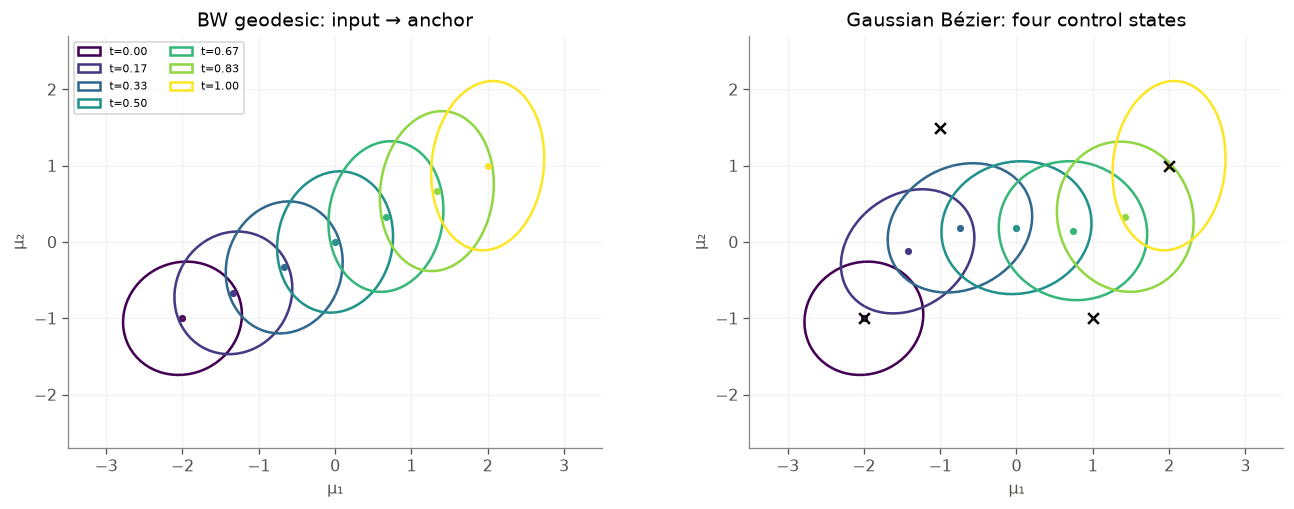

In [7]:
def draw_gaussian(ax,G,color,label=None,alpha=1.,linewidth=1.6):
    mu,cov=(v.detach().cpu().numpy() for v in G)
    ev,U=np.linalg.eigh(cov)
    angle=np.degrees(np.arctan2(U[1,1],U[0,1]))
    ax.add_patch(Ellipse(mu,2*np.sqrt(ev[1]),2*np.sqrt(ev[0]),angle=angle,
                         fill=False,edgecolor=color,linewidth=linewidth,alpha=alpha,label=label))
    ax.scatter(*mu,s=12,color=color,alpha=alpha)

def bezier_gaussian(controls,t):
    current=list(controls)
    while len(current)>1:
        current=[geodesic(a,b,t) for a,b in zip(current[:-1],current[1:])]
    return current[0]

ctrl_raw=[[-.25,.05,-.3],[.0,.5,-.2],[.15,-.35,-.3],[-.3,.1,.1]]
ctrl_mu=[[-2.,-1.],[-1.,1.5],[1.,-1.0],[2.,1.]]
controls=[(torch.tensor(m,device=DEVICE),cov_from_raw(torch.tensor(c,device=DEVICE)))
          for m,c in zip(ctrl_mu,ctrl_raw)]
fig,axs=plt.subplots(1,2,figsize=(12,4.4))
for t in np.linspace(0,1,7):
    draw_gaussian(axs[0],geodesic(controls[0],controls[-1],float(t)),plt.cm.viridis(t),f't={t:.2f}')
    draw_gaussian(axs[1],bezier_gaussian(controls,float(t)),plt.cm.viridis(t))
for g in controls:
    axs[1].scatter(*g[0].cpu(),marker='x',s=45,color='black')
for ax,title in zip(axs,['BW geodesic: input → anchor','Gaussian Bézier: four control states']):
    ax.set(title=title,xlim=(-3.5,3.5),ylim=(-2.7,2.7),xlabel='μ₁',ylabel='μ₂')
    ax.set_aspect('equal'); ax.grid(alpha=.15)
axs[0].legend(fontsize=7,loc='upper left',ncol=2)
plt.tight_layout(); plt.show()

## 6. Данные: задачи, seed данных и раздельные OOD-наборы

Два входа и один выход, гауссианы с вращениями и недиагональными ковариациями.
Генератор входов одинаков для задач; цели не получены обученным KAN.

1. **affine**: фиксированное аффинное преобразование арифметического среднего параметров.
2. **geodesic**: точка $t=0.35$ между двумя входными гауссианами.
3. **nonlinear**: нелинейный сдвиг среднего и SPD-деформация средней ковариации, зависящая от входных средних.
4. **geo_position** (диагностика этапа C): те же средние, но $\Sigma_1=\Sigma_2=I$.
   Цель $\mu^*=0.65\mu_1+0.35\mu_2$, $\Sigma^*=I$ — это та же geodesic-цель, ограниченная на единичные ковариации.

**Seed данных** $d$ задаёт выборки: train = $d+1$, val = $d+2$, test = $d+3$, база OOD = $d+4$.
$d=2000$ воспроизводит исходную тетрадку побитово. Данные создаются на CPU, не зависят от устройства и seed обучения,
общие для всех моделей внутри одного seed данных.

**OOD-варианты** строятся из **одних и тех же** базовых случайных величин (seed $d+4$):

| срез | средние | анизотропия Σ |
|---|---|---|
| `ood_id` | без изменения | без изменения — контрольный ID-набор той же выборки |
| `ood_mean` | $1.8\mu+(1,-0.6)$ | без изменения |
| `ood_cov` | без изменения | $\log\sigma+(0.5,-0.5)$ |
| `ood` | оба изменения — исходный составной сдвиг | |

Цели каждого варианта заново считаются исходной `target_fn`. Важно для интерпретации:
в nonlinear деформация ковариации зависит от входных средних, поэтому и сдвиг только средних
может ухудшить предсказание Σ. Диагностические OOD-наборы не используются ни для выбора checkpoint, ни для выбора lr.

In [8]:
TASKS=['affine','geodesic','nonlinear']      # основные задачи
DIAG_TASKS=['geo_position']                   # диагностика положения, этап C
ALL_TASKS=TASKS+DIAG_TASKS
DATA_SEED_ORIGINAL=2000                       # seed 2001/2002/2003/2004 — как в исходной тетрадке
OOD_VARIANTS={'ood_id':(False,False),'ood_mean':(True,False),'ood_cov':(False,True),'ood':(True,True)}

def task_splits(task):
    ood=['ood_id','ood_mean'] if task=='geo_position' else list(OOD_VARIANTS)
    return ['train','val','test']+ood

def target_fn(G,task):
    mu,cov=G
    m,C=mu.mean(1),cov.mean(1)
    if task=='affine':
        A=torch.tensor([[1.1,.15],[.15,.85]],device=mu.device)
        out=(m @ A.T + torch.tensor([.25,-.15],device=mu.device),sym(A @ C @ A.T))
    elif task=='geodesic':
        out=geodesic((mu[:,0],cov[:,0]),(mu[:,1],cov[:,1]),.35)
    elif task=='nonlinear':
        u,v=mu[:,0],mu[:,1]
        shift=torch.stack((.35*torch.sin(u[:,0]*v[:,1]),
                           .30*torch.tanh(u[:,1]+v[:,0])), -1)
        a=.18*torch.sin(u[:,0]+v[:,0])
        b=.12*torch.tanh(u[:,1]*v[:,1])
        c=-.15*torch.cos(u[:,1]-v[:,0])
        S=torch.stack((a,b,b,c),-1).reshape(-1,2,2)
        A=torch.linalg.matrix_exp(S)
        out=(m+shift,sym(A @ C @ A.transpose(-1,-2)))
    elif task=='geo_position':
        out=(.65*mu[:,0]+.35*mu[:,1], torch.eye(2,device=mu.device).expand_as(cov[:,0]).clone())
    else:
        raise ValueError(task)
    return out[0][:,None],out[1][:,None]

def make_inputs(data_seed,n_train,n_val,n_test,identity_cov=False):
    cpu=torch.device('cpu')
    G={'train':random_gaussians(n_train,2,data_seed+1,device=cpu),
       'val':random_gaussians(n_val,2,data_seed+2,device=cpu),
       'test':random_gaussians(n_test,2,data_seed+3,device=cpu)}
    for name,(shift_mean,shift_cov) in OOD_VARIANTS.items():
        G[name]=random_gaussians(n_test,2,data_seed+4,shift_mean=shift_mean,shift_cov=shift_cov,device=cpu)
    if identity_cov:
        G={k:(mu,torch.eye(2).expand_as(cov).clone()) for k,(mu,cov) in G.items()
           if k in ('train','val','test','ood_id','ood_mean')}
    return G

_DATA_CACHE={}
def make_dataset(task,data_seed,n_train,n_val,n_test):
    """{split: (G, Y)} на CPU. Зависит только от задачи, seed данных и размеров."""
    key=(task,data_seed,n_train,n_val,n_test)
    if key not in _DATA_CACHE:
        G=make_inputs(data_seed,n_train,n_val,n_test,identity_cov=(task=='geo_position'))
        _DATA_CACHE[key]={s:(G[s],target_fn(G[s],task)) for s in task_splits(task)}
    return _DATA_CACHE[key]

SIZES0=(256,128,256)
D0={task:make_dataset(task,DATA_SEED_ORIGINAL,*SIZES0) for task in ALL_TASKS}
# 'ood' — ровно исходный составной сдвиг; варианты делят базовые случайные величины.
orig_ood=random_gaussians(256,2,DATA_SEED_ORIGINAL+4,ood=True,device='cpu')
assert all(torch.equal(a,b) for a,b in zip(D0['affine']['ood'][0],orig_ood))
Gi,Gm,Gc=(D0['affine'][s][0] for s in ('ood_id','ood_mean','ood_cov'))
assert torch.equal(Gm[1],Gi[1]) and torch.equal(Gc[0],Gi[0])
assert torch.allclose(Gm[0],1.8*Gi[0]+torch.tensor([1.,-.6]))
# geo_position — geodesic-цель на входах с единичными ковариациями.
for split,(G,Y) in D0['geo_position'].items():
    Yg=target_fn(G,'geodesic')
    assert torch.allclose(Y[0],Yg[0],atol=1e-12) and torch.allclose(Y[1],Yg[1],atol=1e-12)

def describe(G):
    ev=torch.linalg.eigvalsh(G[1])
    return dict(mean_norm_mu=float(G[0].norm(dim=-1).mean()),
                median_log_anisotropy=float((ev[...,1]/ev[...,0]).log().median()))
display(pd.DataFrame({s:describe(D0['affine'][s][0]) for s in task_splits('affine')}).T.round(3))
for task in ALL_TASKS:
    print(f'{task:12s}', {s:tuple(p[0][0].shape) for s,p in D0[task].items()})

,mean_norm_mu,median_log_anisotropy
train,1.012,0.650
val,1.011,0.672
test,0.997,0.680
ood_id,1.013,0.709
ood_mean,2.075,0.709
ood_cov,1.013,2.104
ood,2.075,2.104


affine       {'train': (256, 2, 2), 'val': (128, 2, 2), 'test': (256, 2, 2), 'ood_id': (256, 2, 2), 'ood_mean': (256, 2, 2), 'ood_cov': (256, 2, 2), 'ood': (256, 2, 2)}
geodesic     {'train': (256, 2, 2), 'val': (128, 2, 2), 'test': (256, 2, 2), 'ood_id': (256, 2, 2), 'ood_mean': (256, 2, 2), 'ood_cov': (256, 2, 2), 'ood': (256, 2, 2)}
nonlinear    {'train': (256, 2, 2), 'val': (128, 2, 2), 'test': (256, 2, 2), 'ood_id': (256, 2, 2), 'ood_mean': (256, 2, 2), 'ood_cov': (256, 2, 2), 'ood': (256, 2, 2)}
geo_position {'train': (256, 2, 2), 'val': (128, 2, 2), 'test': (256, 2, 2), 'ood_id': (256, 2, 2), 'ood_mean': (256, 2, 2)}


## 7. Протокол, режимы и конфигурации

**Что одинаково у всех сравниваемых моделей.** Внутри одного seed данных: train/val/test/OOD.
Внутри одного seed обучения: последовательность индексов мини-батчей (свой генератор `seed+10000`)
и начальные параметры пар mean/BW одного типа рёбер (`manual_seed(seed)` перед построением модели).
Инициализация не зависит от задачи, seed данных и lr. Поэтому сравнения разных lr и задач парные.

**Выбор checkpoint — только по validation $W_2^2$**, отдельно в каждом прогоне. Сохраняются два:
- `best` — лучший по validation за весь прогон;
- `best80` — лучший среди шагов 0–80, то есть исходный бюджет на той же траектории.

Траектория первых 80 обновлений не зависит от общего числа шагов: Adam без расписания, те же батчи.
Поэтому `best80` длинного прогона обязан совпасть с исходным 80-шаговым результатом — это проверяется.
Последний checkpoint лучшим автоматически не считается.

**Каждые `eval_every` = 10 обновлений**, включая шаги 0 и 80, записываются train (вся выборка) и validation:
$W_2^2$, `mean_error` $=\|\mu-\mu^*\|^2$ и `cov_error` $=\mathrm{BW}^2(\Sigma,\Sigma^*)$.
Оценка train не трогает генератор батчей.

**Конфигурация прогона (`RunCfg`)** — всё, что влияет на результат:
- модель, задача, seed данных, seed обучения;
- lr, число обновлений, batch, размеры выборок;
- `bary_iters`, dtype;
- частота оценки, окно `best80`;
- клиппинг, параметры Adam, версия протокола.

Хэш этих полей — идентификатор прогона. Одинаковая конфигурация из разных этапов — один и тот же прогон.
Так этап B переиспользует прогоны A при lr = 0.003 и ничего не обучает дважды.
Устройство и частота сохранения `last.pt` в идентификатор не входят: от них результат не зависит
(CPU/GPU совпадают с точностью до округления — сверка в §8). Они записываются в лог.

**Режимы:**

| режим | что меняется относительно исходного запуска |
|---|---|
| `smoke` | 80 обновлений, seed 11, 4 задачи, проверки пути и паритета; свои теги |
| `long_training` (A) | только число обновлений: 80 → 2000 |
| `lr_search` (B) | lr ∈ {0.001, 0.003, 0.01}, 2000 обновлений; выбор по средней лучшей validation по seeds 11/29 |
| `diagnostics` (C) | задача geo_position, lr = 0.003, 2000 обновлений |
| `robustness` (D) | новые seed данных 3000/4000/5000 × seed обучения 11/29/47, lr из этапа B |

**Время.** Прогоны одной архитектуры обучаются одним батчем на устройстве. Измеряется время группы
с синхронизацией GPU. В него входят обновления, оценка train/val каждые 10 шагов и выбор лучших состояний.
Не входят сохранение checkpoints и финальная оценка test/OOD. `seconds_amortized` — время группы,
делённое на число прогонов в ней. Равное число обновлений не равно равному вычислительному бюджету:
BW-модели делают 12 развёрнутых итераций на каждый узел, сплайны и MLP стоят по-разному.

In [9]:
@dataclass(frozen=True)
class RunCfg:
    """Всё, что определяет результат прогона. Хэш полей — идентификатор."""
    model: str
    task: str
    data_seed: int
    train_seed: int
    lr: float
    steps: int
    batch: int
    n_train: int
    n_val: int
    n_test: int
    bary_iters: int
    dtype: str = 'float64'
    eval_every: int = 10
    early_window: int = 80
    clip_norm: float = 5.0
    adam_betas: tuple = (0.9, 0.999)
    adam_eps: float = 1e-8
    protocol: str = 'gkan-v2'   # версия кода данных/обучения/оценки; менять при изменении протокола

    @property
    def config_id(self):
        return hashlib.sha1(json.dumps(asdict(self), sort_keys=True).encode()).hexdigest()[:12]

    @property
    def run_id(self):
        return (f'{MODEL_SLUG[self.model]}__{self.task}__d{self.data_seed}__s{self.train_seed}'
                f'__lr{self.lr:g}__{self.config_id}')

    def group_key(self):
        """Поля, которые должны совпадать у прогонов одного батча (vmap)."""
        d = asdict(self)
        for k in ('task', 'data_seed', 'train_seed', 'lr'):
            d.pop(k)
        return json.dumps(d, sort_keys=True)

RUN_FIELDS = ('steps','batch','n_train','n_val','n_test','bary_iters','dtype','eval_every','early_window')
BASE = dict(batch=64, n_train=256, n_val=128, n_test=256, bary_iters=12, dtype='float64',
            eval_every=10, early_window=80, device=str(DEVICE), save_every=200)
STAGES = {
    'smoke':         dict(BASE, steps=80, save_every=20, tasks=ALL_TASKS, models=MODELS,
                          data_seeds=[DATA_SEED_ORIGINAL], train_seeds=[11], lrs=[0.003]),
    'long_training': dict(BASE, steps=2000, tasks=TASKS, models=MODELS,
                          data_seeds=[DATA_SEED_ORIGINAL], train_seeds=[11, 29], lrs=[0.003]),
    'lr_search':     dict(BASE, steps=2000, tasks=TASKS, models=MODELS,
                          data_seeds=[DATA_SEED_ORIGINAL], train_seeds=[11, 29], lrs=[0.001, 0.003, 0.01]),
    'diagnostics':   dict(BASE, steps=2000, tasks=DIAG_TASKS, models=MODELS,
                          data_seeds=[DATA_SEED_ORIGINAL], train_seeds=[11, 29], lrs=[0.003]),
    'robustness':    dict(BASE, steps=2000, tasks=TASKS, models=MODELS,
                          data_seeds=[3000, 4000, 5000], train_seeds=[11, 29, 47], lrs='selected'),
}
for preset in STAGES.values():
    preset.update(OVERRIDES)

# Протокол исходного запуска — для сверок, не зависящих от OVERRIDES.
ORIGINAL_PROTOCOL = dict(steps=80, batch=64, n_train=256, n_val=128, n_test=256, bary_iters=12,
                         eval_every=10, early_window=80)

def cfg_like(stage, **kw):
    p = STAGES[stage]
    d = dict(model=MODELS[0], task=TASKS[0], data_seed=p['data_seeds'][0], train_seed=p['train_seeds'][0],
             lr=0.003 if p['lrs'] == 'selected' else p['lrs'][0], **{k: p[k] for k in RUN_FIELDS})
    d.update(kw)
    return RunCfg(**d)

# Результаты исходной тетрадки (80 обновлений, данные 2000, float64, CPU): test / OOD W₂² и лучший шаг.
_REF = """
affine    11  0.00069 0.02387 80  0.00077 0.02125 80  0.00165 0.03438 80  0.00252 0.05419 80  0.00297 0.05294 70  0.15283 0.41507 80
affine    29  0.00058 0.02354 80  0.00072 0.02040 80  0.00158 0.03343 80  0.00237 0.05103 80  0.00308 0.05097 80  0.16433 0.44068 80
geodesic  11  0.01701 0.13983 80  0.00378 0.07901 70  0.00491 0.07577 50  0.01502 0.11649 80  0.00217 0.04740 70  0.07875 0.30371 80
geodesic  29  0.01706 0.14765 80  0.00392 0.07557 80  0.00456 0.07690 70  0.01494 0.12254 80  0.00231 0.04645 80  0.07874 0.30546 80
nonlinear 11  0.04377 0.18091 80  0.03925 0.25041 80  0.04166 0.24443 70  0.04452 0.21857 80  0.04405 0.25794 80  0.12702 0.37531 80
nonlinear 29  0.04436 0.19113 80  0.04137 0.26359 70  0.04236 0.24309 70  0.04494 0.22702 80  0.04585 0.27958 70  0.12640 0.37357 80
"""
REFERENCE_80 = {}
for line in _REF.strip().splitlines():
    task, seed, *vals = line.split()
    for j, model in enumerate(MODELS):
        test, ood, best = vals[3*j:3*j+3]
        REFERENCE_80[(task, int(seed), model)] = dict(test=float(test), ood=float(ood), best_step=int(best))
assert sum(v['best_step'] == 80 for v in REFERENCE_80.values()) == 27

overview = []
for name, p in STAGES.items():
    n_lr = 1 if p['lrs'] == 'selected' else len(p['lrs'])
    overview.append(dict(stage=name, steps=p['steps'], batch=p['batch'], lrs=p['lrs'], tasks=', '.join(p['tasks']),
                         data_seeds=p['data_seeds'], train_seeds=p['train_seeds'], bary_iters=p['bary_iters'],
                         dtype=p['dtype'], device=p['device'],
                         runs=len(p['tasks'])*len(p['models'])*len(p['data_seeds'])*len(p['train_seeds'])*n_lr,
                         enabled=RUN[name]))
display(pd.DataFrame(overview).set_index('stage'))

,steps,batch,lrs,tasks,data_seeds,train_seeds,bary_iters,dtype,device,runs,enabled
stage,,,,,,,,,,,
smoke,80,64,[0.003],"affine, geodesic, nonlinear, geo_position",[2000],[11],12,float64,cuda,24,False
long_training,2000,64,[0.003],"affine, geodesic, nonlinear",[2000],"[11, 29]",12,float64,cuda,36,False
lr_search,2000,64,"[0.001, 0.003, 0.01]","affine, geodesic, nonlinear",[2000],"[11, 29]",12,float64,cuda,108,False
diagnostics,2000,64,[0.003],geo_position,[2000],"[11, 29]",12,float64,cuda,12,False
robustness,2000,64,selected,"affine, geodesic, nonlinear","[3000, 4000, 5000]","[11, 29, 47]",12,float64,cuda,162,True


In [10]:
def _now():
    return time.strftime('%Y-%m-%dT%H:%M:%S%z')

def n_runs(n):
    if n % 10 == 1 and n % 100 != 11: return f'{n} прогон'
    if n % 10 in (2, 3, 4) and n % 100 not in (12, 13, 14): return f'{n} прогона'
    return f'{n} прогонов'

def _atomic_text(path, text):
    tmp = path.with_name(path.name + '.tmp'); tmp.write_text(text, encoding='utf-8'); os.replace(tmp, path)

class Store:
    """Результаты одного тега на диске. Каждый завершённый (или упавший) прогон дописывается
    в runs.jsonl одной строкой; актуальна последняя строка с данным run_id. Файлы пишутся
    через временный файл и os.replace, поэтому прерывание ядра не портит уже сохранённое."""
    def __init__(self, tag):
        self.tag, self.root = tag, RESULTS_ROOT/tag
        for sub in ('ckpt', 'curves'):
            (self.root/sub).mkdir(parents=True, exist_ok=True)
        self.runs_path = self.root/'runs.jsonl'

    def records(self):
        out = {}
        if self.runs_path.exists():
            for line in self.runs_path.read_text(encoding='utf-8').splitlines():
                if line.strip():
                    rec = json.loads(line); out[rec['run_id']] = rec
        return out

    def append(self, rec):
        with open(self.runs_path, 'a', encoding='utf-8') as f:
            f.write(json.dumps(rec, ensure_ascii=False) + '\n'); f.flush(); os.fsync(f.fileno())

    def ckpt(self, run_id, name):
        return self.root/'ckpt'/run_id/f'{name}.pt'

    def save_pt(self, run_id, name, obj):
        path = self.ckpt(run_id, name); path.parent.mkdir(parents=True, exist_ok=True)
        tmp = path.with_name(path.name + '.tmp'); torch.save(obj, tmp); os.replace(tmp, path)

    def load_pt(self, run_id, name):
        path = self.ckpt(run_id, name)
        return torch.load(path, map_location='cpu', weights_only=True) if path.exists() else None

    def save_curve(self, run_id, df):
        path = self.root/'curves'/f'{run_id}.csv'
        tmp = path.with_name(path.name + '.tmp'); df.to_csv(tmp, index=False); os.replace(tmp, path)

    def load_curve(self, run_id):
        return pd.read_csv(self.root/'curves'/f'{run_id}.csv')

    def export_tables(self):
        runs, met = records_to_frames(self.records())
        for name, df in (('runs.csv', runs), ('metrics.csv', met)):
            tmp = self.root/(name + '.tmp'); df.to_csv(tmp, index=False); os.replace(tmp, self.root/name)
        _atomic_text(self.root/'env.json', json.dumps(ENV, indent=1))

def records_to_frames(recs):
    runs, met = [], []
    for r in recs.values():
        row = {k: v for k, v in r.items() if k not in ('metrics', 'config', 'versions', 'traceback')}
        for k, v in r['config'].items():
            row[k] = json.dumps(v) if isinstance(v, (list, tuple)) else v
        runs.append(row)
        for ck, splits in (r.get('metrics') or {}).items():
            for sp, m in splits.items():
                met.append(dict(run_id=r['run_id'], stage=r['stage'], status=r['status'], model=r['model'],
                                task=r['task'], data_seed=r['data_seed'], train_seed=r['train_seed'], lr=r['lr'],
                                ckpt=ck, split=sp, **m))
    runs = pd.DataFrame(runs)
    for col in ('bary_residual_max', 'bary_vs_40iter_w2max', 'best_val_w2', 'best80_val_w2'):
        if col in runs:
            runs[col] = pd.to_numeric(runs[col], errors='coerce')
    return runs, pd.DataFrame(met)

def stage_configs(stage, tag=None):
    p = STAGES[stage]
    sel = load_selected_lr(tag or EXPERIMENT_TAG) if p['lrs'] == 'selected' else None
    cfgs = []
    for task in p['tasks']:
        for model in p['models']:
            lrs = [sel[(task, model)]] if sel else p['lrs']
            for ds in p['data_seeds']:
                for ts in p['train_seeds']:
                    for lr in lrs:
                        cfgs.append(RunCfg(model=model, task=task, data_seed=ds, train_seed=ts, lr=lr,
                                           **{k: p[k] for k in RUN_FIELDS}))
    return cfgs

LR_RULE = ('для каждой пары задача × модель: минимум средней по seed лучшей validation W₂² '
           '(checkpoint внутри прогона — тоже по validation); при равенстве — меньший lr')

def select_learning_rates(tag=None):
    tag = tag or EXPERIMENT_TAG
    store = Store(tag); recs = store.records()
    cfgs = stage_configs('lr_search', tag)
    missing = [c.run_id for c in cfgs if recs.get(c.run_id, {}).get('status') != 'done']
    if missing:
        raise RuntimeError(f'Этап B не завершён: нет {len(missing)} готовых прогонов, например {missing[:3]}')
    df = pd.DataFrame([dict(task=c.task, model=c.model, lr=c.lr, train_seed=c.train_seed,
                            best_val_w2=recs[c.run_id]['best_val_w2']) for c in cfgs])
    agg = df.groupby(['task', 'model', 'lr'], as_index=False).best_val_w2.mean()
    chosen = agg.sort_values(['task', 'model', 'best_val_w2', 'lr']).groupby(['task', 'model']).head(1)
    payload = dict(rule=LR_RULE, created=_now(), stage_config={k: v for k, v in STAGES['lr_search'].items()},
                   selection=chosen.to_dict('records'), table=agg.to_dict('records'))
    _atomic_text(store.root/'selected_lr.json', json.dumps(payload, indent=1, ensure_ascii=False))
    return payload

def load_selected_lr(tag=None):
    path = RESULTS_ROOT/(tag or EXPERIMENT_TAG)/'selected_lr.json'
    if not path.exists():
        raise RuntimeError(f'Нет {path}: сначала завершите этап B (lr_search) в этом теге.')
    return {(s['task'], s['model']): s['lr'] for s in json.loads(path.read_text())['selection']}

In [11]:
MAX_GROUP = 64          # максимум прогонов в одном батче vmap
CURVE_COLS = ['train_w2', 'train_mean_error', 'train_cov_error', 'val_w2', 'val_mean_error', 'val_cov_error']
METRIC_NAMES = ['w2', 'mean_error', 'cov_error', 'min_eig', 'symmetry_error', 'finite']
TIMING_NOTE = ('время группы: обновления + оценка train/val каждые eval_every шагов + выбор лучших состояний; '
               'без сохранения checkpoint и финальной оценки test/OOD; GPU синхронизирован до и после')
RNG_NOTE = ('глобальный RNG torch используется только при инициализации (manual_seed(train_seed)); '
            'батчи берутся из отдельного генератора, его состояние — batch_gen_state')

def sync(device):
    if device.type == 'cuda':
        torch.cuda.synchronize(device)

def _per_run(v, like):
    return v.view(-1, *([1]*(like.dim() - 1)))

@torch.no_grad()
def batched_metrics(pred, Y):
    """pred, Y с осью прогонов 0: (R, N, 1, …) → (R, 6) в порядке METRIC_NAMES."""
    em, ec = w2_parts(pred, Y); C = pred[1]
    finite = torch.isfinite(pred[0]).flatten(1).all(1) & torch.isfinite(C).flatten(1).all(1)
    return torch.stack(((em + ec).flatten(1).mean(1), em.flatten(1).mean(1), ec.flatten(1).mean(1),
                        eigmin_sym2(C).flatten(1).amin(1), (C - C.transpose(-1, -2)).abs().flatten(1).amax(1),
                        finite.to(C.dtype)), 1)

@torch.no_grad()
def evaluate(model, pair):
    dev = next(model.parameters()).device
    G, Y = pair
    pred = model(*(g.to(dev) for g in G))
    row = batched_metrics(tuple(p[None] for p in pred), tuple(y.to(dev)[None] for y in Y))[0]
    return dict(zip(METRIC_NAMES, row.tolist()))

@torch.no_grad()
def aggregation_diagnostic(model, G):
    """Остаток BW-итерации и расхождение с 40 итерациями на переданных примерах (каждый слой)."""
    if not isinstance(model, GaussianNetwork):
        return np.nan, np.nan
    dev = next(model.parameters()).device
    current = tuple(g.to(dev) for g in G); residuals = []; discrepancies = []
    for layer in model.layers:
        result, msg, _ = layer(*current, return_messages=True)
        if layer.aggregation == 'bw':
            residuals.append(float(bary_residual(result[1], msg[1]).max()))
            reference = barycenter(msg, iters=40)
            discrepancies.append(float(w2sq(result, reference).max()))
        current = result
    return (max(residuals), max(discrepancies)) if residuals else (np.nan, np.nan)

def stack_split(cfgs, split, device):
    data = [make_dataset(c.task, c.data_seed, c.n_train, c.n_val, c.n_test)[split] for c in cfgs]
    G = tuple(torch.stack([d[0][i] for d in data]).to(device) for i in range(2))
    Y = tuple(torch.stack([d[1][i] for d in data]).to(device) for i in range(2))
    return G, Y

def make_batched_forward(template):
    buffers = dict(template.named_buffers())
    def forward(params, mu, cov):
        return functional_call(template, (params, buffers), (mu, cov))
    return vmap(forward)                      # ось 0 у параметров и входов — номер прогона

def init_params(cfgs, device):
    models = []
    for c in cfgs:                            # та же инициализация, что в исходном fit
        torch.manual_seed(c.train_seed)
        models.append(build_model(c.model, c.bary_iters).to(device))
    names = [k for k, _ in models[0].named_parameters()]
    return models[0], {k: torch.stack([dict(m.named_parameters())[k].detach() for m in models]) for k in names}

def unstack_model(template, params, r):
    model = copy.deepcopy(template)
    with torch.no_grad():
        for k, p in model.named_parameters():
            p.copy_(params[k][r])
    return model

def train_group(cfgs, device, resume=None, save_every=None, on_checkpoint=None, stop_at=None):
    """R независимых прогонов одной архитектуры одним батчем. Математически это R копий исходного fit:
    своя инициализация (manual_seed), свой генератор батчей, Adam поэлементный с lr своего прогона,
    клиппинг нормы градиента отдельно в каждом прогоне. В цикле нет синхронизаций GPU→CPU:
    проверки конечности и выбор лучших состояний — на устройстве."""
    c0 = cfgs[0]
    assert all(c.group_key() == c0.group_key() for c in cfgs), 'в батче — только прогоны с общим протоколом'
    assert c0.dtype == 'float64', 'float32/AMP не реализованы: основное сравнение только в float64'
    R, steps, every = len(cfgs), c0.steps, c0.eval_every
    template, params = init_params(cfgs, device)
    names = list(params)
    exp_avg = {k: torch.zeros_like(v) for k, v in params.items()}
    exp_avg_sq = {k: torch.zeros_like(v) for k, v in params.items()}
    lr = torch.tensor([c.lr for c in cfgs], device=device, dtype=DTYPE)
    (b1, b2), eps, clip = c0.adam_betas, c0.adam_eps, c0.clip_norm
    fwd = make_batched_forward(template)
    Gtr, Ytr = stack_split(cfgs, 'train', device)
    Gva, Yva = stack_split(cfgs, 'val', device)
    Gtv = tuple(torch.cat(p, 1) for p in zip(Gtr, Gva))      # train и val одним проходом
    Ytv = tuple(torch.cat(p, 1) for p in zip(Ytr, Yva))
    n_train = c0.n_train
    run_ix = torch.arange(R, device=device)[:, None]
    gens = [torch.Generator().manual_seed(c.train_seed + 10000) for c in cfgs]
    inf = torch.full((R,), float('inf'), device=device)
    st = dict(best_val=inf.clone(), best_step=torch.zeros(R, dtype=torch.long, device=device),
              best80_val=inf.clone(), best80_step=torch.zeros(R, dtype=torch.long, device=device),
              first_bad=torch.full((R,), -1, dtype=torch.long, device=device))
    best = {k: v.clone() for k, v in params.items()}
    best80 = {k: v.clone() for k, v in params.items()}
    curve, eval_steps, step, seconds = [], [], 0, 0.0
    if resume is not None:
        step, seconds, eval_steps = int(resume['step']), float(resume['seconds']), list(resume['eval_steps'])
        for target, key in ((params, 'params'), (exp_avg, 'exp_avg'), (exp_avg_sq, 'exp_avg_sq'),
                            (best, 'best_params'), (best80, 'best80_params')):
            for k in names:
                target[k] = resume[key][k].to(device).clone()
        for k in st:
            st[k] = resume[k].to(device).clone()
        curve = list(resume['curve'].to(device).unbind(1))
        for g, s in zip(gens, resume['gen_states']):
            g.set_state(s)
    for v in params.values():
        v.requires_grad_(True)
    step0 = step

    def evaluate_curve():
        with torch.no_grad():
            em, ec = w2_parts(fwd(params, *Gtv), Ytv)
            parts = []
            for sl in (slice(0, n_train), slice(n_train, None)):
                a, b = em[:, sl].flatten(1), ec[:, sl].flatten(1)
                parts += [(a + b).mean(1), a.mean(1), b.mean(1)]
            return torch.stack(parts, 1)

    def snapshot():
        cpu = lambda d: {k: v.detach().cpu().clone() for k, v in d.items()}
        return dict(step=step, seconds=seconds, eval_steps=list(eval_steps), params=cpu(params),
                    exp_avg=cpu(exp_avg), exp_avg_sq=cpu(exp_avg_sq), best_params=cpu(best), best80_params=cpu(best80),
                    curve=torch.stack(curve, 1).cpu() if curve else torch.zeros(R, 0, len(CURVE_COLS)),
                    gen_states=[g.get_state() for g in gens], **{k: v.cpu() for k, v in st.items()})

    chunk, j = None, 0
    sync(device); t0 = time.perf_counter()
    while True:
        if (step % every == 0 or step == steps) and not (resume is not None and step == step0):
            ev = evaluate_curve(); val = ev[:, 3]
            st['first_bad'] = torch.where(~torch.isfinite(ev).all(1) & (st['first_bad'] < 0), step, st['first_bad'])
            imp = val < st['best_val']
            st['best_val'] = torch.where(imp, val, st['best_val'])
            st['best_step'] = torch.where(imp, step, st['best_step'])
            for k, v in params.items():
                best[k] = torch.where(_per_run(imp, v), v.detach(), best[k])
            if step <= c0.early_window:
                imp = val < st['best80_val']
                st['best80_val'] = torch.where(imp, val, st['best80_val'])
                st['best80_step'] = torch.where(imp, step, st['best80_step'])
                for k, v in params.items():
                    best80[k] = torch.where(_per_run(imp, v), v.detach(), best80[k])
            curve.append(ev); eval_steps.append(step)
        if step == steps:
            break
        if save_every and on_checkpoint is not None and step > step0 and step % save_every == 0:
            sync(device); seconds += time.perf_counter() - t0
            on_checkpoint(snapshot())
            if stop_at is not None and step >= stop_at:
                return dict(status='interrupted', step=step)
            sync(device); t0 = time.perf_counter()
        if chunk is None or j == chunk.shape[1]:
            # Индексы — тем же генератором и тем же порядком вызовов, что в исходном fit,
            # но пачкой до следующей точки сохранения: одна пересылка на устройство вместо сотен.
            size = min(save_every - step % save_every, steps - step) if save_every else steps - step
            chunk = torch.stack([torch.stack([torch.randint(n_train, (c0.batch,), generator=g)
                                              for _ in range(size)]) for g in gens]).to(device)
            j = 0
        idx = chunk[:, j]; j += 1
        loss = w2sq(fwd(params, Gtr[0][run_ix, idx], Gtr[1][run_ix, idx]),
                    (Ytr[0][run_ix, idx], Ytr[1][run_ix, idx])).flatten(1).mean(1)          # (R,)
        grads = torch.autograd.grad(loss.sum(), [params[k] for k in names])  # прогоны независимы
        norm = torch.stack([g.flatten(1).norm(dim=1) for g in grads], 1).norm(dim=1)
        coef = (clip / (norm + 1e-6)).clamp(max=1.)                         # clip_grad_norm_ на прогон
        st['first_bad'] = torch.where(~(torch.isfinite(loss) & torch.isfinite(norm)) & (st['first_bad'] < 0),
                                      step, st['first_bad'])
        t = float(step + 1)                                                  # Adam как в torch.optim.Adam
        bc1, bc2_sqrt = 1 - b1**t, (1 - b2**t)**0.5
        neg_step_size = -(lr / bc1)
        with torch.no_grad():
            for k, g in zip(names, grads):
                g = g * _per_run(coef, g)
                exp_avg[k].lerp_(g, 1 - b1)
                exp_avg_sq[k].mul_(b2).addcmul_(g, g, value=1 - b2)
                denom = (exp_avg_sq[k].sqrt() / bc2_sqrt).add_(eps)
                params[k].add_(_per_run(neg_step_size, g) * exp_avg[k] / denom)
        step += 1
    sync(device); seconds += time.perf_counter() - t0
    out = snapshot()
    out.update(status='finished', template=template, names=names)
    return out

def _split_snapshot(snap, r):
    one = lambda d: {k: v[r].clone() for k, v in d.items()}
    return dict(step=int(snap['step']), seconds=float(snap['seconds']), eval_steps=list(snap['eval_steps']),
                params=one(snap['params']), exp_avg=one(snap['exp_avg']), exp_avg_sq=one(snap['exp_avg_sq']),
                best_params=one(snap['best_params']), best80_params=one(snap['best80_params']),
                curve=snap['curve'][r].clone(), batch_gen_state=snap['gen_states'][r],
                **{k: snap[k][r].clone() for k in ('best_val', 'best_step', 'best80_val', 'best80_step', 'first_bad')})

def _stack_snapshots(parts):
    stk = lambda key: {k: torch.stack([p[key][k] for p in parts]) for k in parts[0][key]}
    assert len({p['step'] for p in parts}) == 1
    return dict(step=parts[0]['step'], seconds=max(p['seconds'] for p in parts), eval_steps=parts[0]['eval_steps'],
                params=stk('params'), exp_avg=stk('exp_avg'), exp_avg_sq=stk('exp_avg_sq'),
                best_params=stk('best_params'), best80_params=stk('best80_params'),
                curve=torch.stack([p['curve'] for p in parts]), gen_states=[p['batch_gen_state'] for p in parts],
                **{k: torch.stack([p[k] for p in parts]) for k in ('best_val', 'best_step', 'best80_val',
                                                                    'best80_step', 'first_bad')})

def _last_state(c, snap, r):
    return dict(run_id=c.run_id, config=json.dumps(asdict(c)), global_rng_state=torch.get_rng_state(),
                rng_note=RNG_NOTE, saved_at=_now(), **_split_snapshot(snap, r))

def _base_record(c, store, stage, device):
    return dict(run_id=c.run_id, config_id=c.config_id, tag=store.tag, stage=stage, status=None, error=None,
                model=c.model, task=c.task, data_seed=c.data_seed, train_seed=c.train_seed, lr=c.lr,
                config=asdict(c), device=str(device), device_name=ENV['device_name'], dtype=c.dtype,
                versions=ENV, finished_at=_now(), metrics=None)

def finalize_group(cfgs, out, store, stage, device, resumed_from):
    R, template = len(cfgs), out['template']
    fwd = make_batched_forward(template)
    first_bad = out['first_bad'].tolist()
    ok = [r for r in range(R) if first_bad[r] < 0]
    metrics = {r: {'best': {}, 'best80': {}} for r in ok}
    for ck in ('best', 'best80'):
        P = {k: v.to(device) for k, v in out[f'{ck}_params'].items()}
        for split in dict.fromkeys(s for c in cfgs for s in task_splits(c.task)):
            rs = [r for r in ok if split in task_splits(cfgs[r].task)]
            if not rs:
                continue
            G, Y = stack_split([cfgs[r] for r in rs], split, device)
            ix = torch.tensor(rs, device=device)
            with torch.no_grad():
                rows = batched_metrics(fwd({k: v[ix] for k, v in P.items()}, *G), Y).cpu().tolist()
            for r, row in zip(rs, rows):
                metrics[r][ck][split] = dict(zip(METRIC_NAMES, row))
    n_params = count_params(template)
    for r, c in enumerate(cfgs):
        rid = c.run_id
        last = _last_state(c, out, r)
        store.save_pt(rid, 'last', last)
        curve = pd.DataFrame(last['curve'].numpy(), columns=CURVE_COLS)
        curve.insert(0, 'step', out['eval_steps'])
        store.save_curve(rid, curve)
        for ck in ('best', 'best80'):
            model = unstack_model(template, out[f'{ck}_params'], r)
            store.save_pt(rid, ck, dict(run_id=rid, config=json.dumps(asdict(c)), step=int(last[f'{ck}_step']),
                                        val_w2=float(last[f'{ck}_val']),
                                        state_dict={k: v.detach().cpu() for k, v in model.state_dict().items()}))
        rec = _base_record(c, store, stage, device)
        rec.update(status='done', params=n_params,
                   best_step=int(last['best_step']), best_val_w2=float(last['best_val']),
                   best80_step=int(last['best80_step']), best80_val_w2=float(last['best80_val']),
                   last_eval_step=int(out['eval_steps'][-1]), last_val_w2=float(last['curve'][-1, 3]),
                   best_is_last_eval=int(last['best_step']) == int(out['eval_steps'][-1]),
                   seconds_group=float(out['seconds']), runs_in_group=R, seconds_amortized=float(out['seconds'])/R,
                   timing=TIMING_NOTE, resumed_from_step=int(resumed_from),
                   bary_residual_max=None, bary_vs_40iter_w2max=None, first_bad_update=None)
        if first_bad[r] >= 0:
            rec.update(status='failed', first_bad_update=first_bad[r],
                       error=f'неконечный loss/градиент/кривая, первое обновление {first_bad[r]}')
        else:
            rec['metrics'] = metrics[r]
            bad = [f'{ck}/{sp}' for ck, d in metrics[r].items() for sp, m in d.items()
                   if not (m['finite'] == 1 and m['min_eig'] > 0)]
            if bad:
                rec.update(status='failed', error=f'не-SPD или неконечные выходы: {bad}')
            best_model = unstack_model(template, out['best_params'], r).to(device)
            test_G = make_dataset(c.task, c.data_seed, c.n_train, c.n_val, c.n_test)['test'][0]
            res, disc = aggregation_diagnostic(best_model, tuple(v[:32] for v in test_G))
            rec.update(bary_residual_max=None if np.isnan(res) else res,
                       bary_vs_40iter_w2max=None if np.isnan(disc) else disc)
        store.append(rec)
        if rec['metrics']:
            m = rec['metrics']['best']; ood = 'ood' if 'ood' in m else 'ood_mean'
            print(f'  {c.task:12s} d={c.data_seed} s={c.train_seed:<3d} lr={c.lr:<6g} {c.model:17s} '
                  f'test={m["test"]["w2"]:.5f} {ood}={m[ood]["w2"]:.5f} best={rec["best_step"]:>4d} '
                  f'best≤{c.early_window}={rec["best80_step"]:>3d}' + ('' if rec['status'] == 'done' else '  ⚠ ' + rec['error']))
        else:
            print(f'  {c.task:12s} d={c.data_seed} s={c.train_seed:<3d} lr={c.lr:<6g} {c.model:17s} ⚠ FAILED: {rec["error"]}')

def run_configs(cfgs, tag, stage, device=None, save_every=200, stop_at=None):
    device = torch.device(device or DEVICE)
    store = Store(tag); recs = store.records()
    cfgs = list(dict.fromkeys(cfgs))
    summary = dict(stage=stage, tag=tag, requested=len(cfgs), skipped_done=0, skipped_failed=0,
                   trained=0, failed=0, interrupted=0, seconds=0.0)
    todo = []
    for c in cfgs:
        status = recs.get(c.run_id, {}).get('status')
        if status == 'done':
            summary['skipped_done'] += 1; continue
        if status == 'failed' and not RETRY_FAILED:
            summary['skipped_failed'] += 1; continue
        if status == 'failed':
            shutil.rmtree(store.root/'ckpt'/c.run_id, ignore_errors=True)
        todo.append(c)
    groups = {}
    for c in todo:
        last = store.load_pt(c.run_id, 'last')
        groups.setdefault((c.group_key(), last['step'] if last else 0), []).append(c)
    t_stage = time.perf_counter()
    for (_, start), group in sorted(groups.items(), key=lambda kv: (MODELS.index(kv[1][0].model), -kv[0][1])):
        for i in range(0, len(group), MAX_GROUP):
            part = group[i:i + MAX_GROUP]
            print(f'▶ {part[0].model}: {n_runs(len(part))} одним батчем'
                  + (f', продолжение с шага {start}' if start else ''), flush=True)
            try:
                resume = _stack_snapshots([store.load_pt(c.run_id, 'last') for c in part]) if start else None
                def on_checkpoint(snap, part=part):
                    for r, c in enumerate(part):
                        store.save_pt(c.run_id, 'last', _last_state(c, snap, r))
                out = train_group(part, device, resume, save_every, on_checkpoint, stop_at)
                if out['status'] == 'interrupted':
                    summary['interrupted'] += len(part)
                    print(f'  остановлено после сохранения на шаге {out["step"]} (stop_at={stop_at})')
                    continue
                finalize_group(part, out, store, stage, device, start)
                print(f'  группа: {out["seconds"]:.1f}s на {device} (с оценкой train/val)', flush=True)
                now = store.records()
                n_failed = sum(now[c.run_id]['status'] == 'failed' for c in part)
                summary['trained'] += len(part) - n_failed; summary['failed'] += n_failed
            except Exception as e:
                tb = traceback.format_exc()
                for c in part:
                    rec = _base_record(c, store, stage, device)
                    rec.update(status='failed', error=f'{type(e).__name__}: {e}', traceback=tb[-4000:])
                    store.append(rec)
                summary['failed'] += len(part)
                warnings.warn(f'{part[0].model}: группа ({n_runs(len(part))}) упала: {type(e).__name__}: {e}')
    summary['seconds'] = time.perf_counter() - t_stage
    store.export_tables()
    print('Итог:', summary)
    failed = [r for r in store.records().values() if r['status'] == 'failed' and r['run_id'] in
              {c.run_id for c in cfgs}]
    if failed:
        print(f'⚠ {n_runs(len(failed))} со статусом failed (повтор: RETRY_FAILED=True):')
        display(pd.DataFrame(failed)[['run_id', 'stage', 'error']])
    return summary

def run_stage(stage, tag=None, stop_at=None):
    tag = tag or EXPERIMENT_TAG
    p = STAGES[stage]
    cfgs = stage_configs(stage, tag)
    print(f'── {stage} → {RESULTS_ROOT/tag}: в конфигурации этапа {n_runs(len(cfgs))}')
    return run_configs(cfgs, tag, stage, device=p['device'], save_every=p['save_every'], stop_at=stop_at)

def load_best_model(tag, cfg, ckpt='best', device=None):
    state = Store(tag).load_pt(cfg.run_id, ckpt)
    if state is None:
        return None
    model = build_model(cfg.model, cfg.bary_iters).to(device or DEVICE)
    model.load_state_dict(state['state_dict'])
    return model

## 8. Проверки перед длинными запусками

Геометрические тождества, gradcheck, SPD и конечность на инициализации уже проверены в §3–§4.
Здесь проверяется то, что изменилось в инфраструктуре:

1. **Батч vs одиночная модель** на одном устройстве: выход, loss и градиенты векторизованного прохода
   (`vmap` по оси прогонов) против обычного `model(...)` для каждого прогона.
2. **CPU vs GPU** (если есть CUDA): одинаковые параметры и входы, float64.
3. **Новый цикл обучения vs исходный последовательный `fit`** (`torch.optim.Adam`, `clip_grad_norm_`):
   кривая validation, лучший шаг и test $W_2^2$. Сверяемый прогон обучается в батче с двумя другими,
   поэтому проверка заодно показывает, что прогоны в батче не влияют друг на друга.

**Допуски:** `rtol = 1e-9`, `atol = 1e-12`. Обоснование:
- единичное округление float64 ≈ $1.1\cdot10^{-16}$;
- цепочка — около сотни зависимых операций: 12 BW-итераций, корни, обратные;
- собственные значения входных ковариаций лежат примерно в $[e^{-2.5}, e^{2.5}]$;
- ожидаемое расхождение от другого порядка суммирования — $10^{-14}$–$10^{-12}$;
- ошибка в формуле дала бы $10^{-3}$ и больше.

Побитовая идентичность CPU и GPU не требуется. Фактические максимальные расхождения печатаются в таблице.

In [12]:
RTOL, ATOL = 1e-9, 1e-12
check_rows = []
def _check(name, a, b):
    a, b = a.detach().to('cpu'), b.detach().to('cpu')
    check_rows.append(dict(check=name, max_abs_diff=float((a - b).abs().max()), max_abs_value=float(b.abs().max()),
                           ok=bool(torch.allclose(a, b, rtol=RTOL, atol=ATOL))))

def batched_probe(cfgs, device, template=None, P=None):
    if template is None:
        template, P = init_params(cfgs, device)
    P = {k: v.detach().to(device).clone().requires_grad_(True) for k, v in P.items()}
    G, Y = stack_split(cfgs, 'train', device)
    G, Y = tuple(g[:, :64] for g in G), tuple(y[:, :64] for y in Y)
    pred = make_batched_forward(template)(P, *G)
    loss = w2sq(pred, Y).flatten(1).mean(1)
    grads = torch.autograd.grad(loss.sum(), list(P.values()))
    assert torch.isfinite(loss).all() and all(torch.isfinite(g).all() for g in grads)
    assert eigmin_sym2(pred[1]).min() > 0
    return template, P, G, Y, pred, loss, grads

for name in MODELS:
    cfgs = [cfg_like('smoke', model=name, task=t, train_seed=s) for t, s in zip(TASKS, (11, 29, 47))]
    template, P, G, Y, pred, loss, grads = batched_probe(cfgs, DEVICE)
    for r in range(len(cfgs)):                                   # 1. батч vs одиночная модель
        m = unstack_model(template, P, r)
        p1 = m(G[0][r], G[1][r]); l1 = w2sq(p1, (Y[0][r], Y[1][r])).mean()
        g1 = torch.autograd.grad(l1, list(m.parameters()))
        _check(f'{name}: vmap vs model, выход', torch.cat((pred[0][r].flatten(), pred[1][r].flatten())),
               torch.cat((p1[0].flatten(), p1[1].flatten())))
        _check(f'{name}: vmap vs model, loss', loss[r], l1)
        _check(f'{name}: vmap vs model, градиенты', torch.cat([g[r].flatten() for g in grads]),
               torch.cat([g.flatten() for g in g1]))
    if DEVICE.type == 'cuda':                                    # 2. CPU vs GPU
        cpu = torch.device('cpu')
        t_cpu = copy.deepcopy(template).to(cpu)
        _, _, _, _, pc, lc, gc = batched_probe(cfgs, cpu, t_cpu, {k: v.cpu() for k, v in P.items()})
        _check(f'{name}: GPU vs CPU, выход', torch.cat((pred[0].flatten(), pred[1].flatten())),
               torch.cat((pc[0].flatten(), pc[1].flatten())))
        _check(f'{name}: GPU vs CPU, loss', loss, lc)
        _check(f'{name}: GPU vs CPU, градиенты', torch.cat([g.flatten() for g in grads]),
               torch.cat([g.flatten() for g in gc]))
if DEVICE.type != 'cuda':
    print('CUDA недоступна: сверка CPU↔GPU пропущена. На машине с GPU эта ячейка выполнит её автоматически.')

def fit_reference(cfg, device=DEVICE):
    """Исходный последовательный fit (torch.optim.Adam, clip_grad_norm_), только для сверки."""
    data = make_dataset(cfg.task, cfg.data_seed, cfg.n_train, cfg.n_val, cfg.n_test)
    G, Y = (tuple(t.to(device) for t in data['train'][0]), tuple(t.to(device) for t in data['train'][1]))
    torch.manual_seed(cfg.train_seed)
    model = build_model(cfg.model, cfg.bary_iters).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr)
    batch_rng = torch.Generator().manual_seed(cfg.train_seed + 10000)
    curve, best, best_step, best_state = [], float('inf'), 0, None
    for step in range(cfg.steps + 1):
        if step % cfg.eval_every == 0 or step == cfg.steps:
            val = evaluate(model, data['val'])['w2']; curve.append(val)
            if val < best:
                best, best_step, best_state = val, step, copy.deepcopy(model.state_dict())
        if step == cfg.steps:
            break
        idx = torch.randint(len(G[0]), (cfg.batch,), generator=batch_rng).to(device)
        loss = w2sq(model(G[0][idx], G[1][idx]), (Y[0][idx], Y[1][idx])).mean()
        optimizer.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.clip_norm)
        optimizer.step()
    model.load_state_dict(best_state)
    return model, np.array(curve), best_step

ref_cfg = cfg_like('smoke', model='Spline / BW', task='geodesic', train_seed=11, data_seed=DATA_SEED_ORIGINAL,
                   lr=0.003, **ORIGINAL_PROTOCOL)
batch = [replace(ref_cfg, task='affine'), ref_cfg, replace(ref_cfg, task='nonlinear', train_seed=29)]
t0 = time.perf_counter(); ref_model, ref_curve, ref_best = fit_reference(ref_cfg); t_ref = time.perf_counter() - t0
out = train_group(batch, DEVICE)
new_model = unstack_model(out['template'], out['best_params'], 1)
test_pair = make_dataset(ref_cfg.task, ref_cfg.data_seed, *SIZES0)['test']
_check('Spline / BW geodesic s11: кривая validation, новый цикл vs исходный fit',
       out['curve'][1][:, 3], torch.tensor(ref_curve))
_check('Spline / BW geodesic s11: test W₂² лучшего checkpoint',
       torch.tensor(evaluate(new_model, test_pair)['w2']), torch.tensor(evaluate(ref_model, test_pair)['w2']))
checks = pd.DataFrame(check_rows)
display(checks.groupby('check', sort=False)
        .agg(max_abs_diff=('max_abs_diff', 'max'), max_abs_value=('max_abs_value', 'max'), ok=('ok', 'all')))
assert checks.ok.all(), checks[~checks.ok]
assert int(out['best_step'][1]) == ref_best == REFERENCE_80[('geodesic', 11, 'Spline / BW')]['best_step']
print(f'Исходный fit: {t_ref:.1f}s на 1 прогон; новый цикл: {out["seconds"]:.1f}s на {n_runs(len(batch))} '
      f'({DEVICE}). Test W₂² = {evaluate(new_model, test_pair)["w2"]:.5f}, в исходной тетрадке 0.01502.')

,max_abs_diff,max_abs_value,ok
check,,,
"Spline / mean: vmap vs model, выход",0.000000e+00,3.884637,True
"Spline / mean: vmap vs model, loss",0.000000e+00,0.209616,True
"Spline / mean: vmap vs model, градиенты",0.000000e+00,0.267621,True
"Spline / mean: GPU vs CPU, выход",1.332268e-15,3.884637,True
"Spline / mean: GPU vs CPU, loss",1.249001e-16,0.209616,True
"Spline / mean: GPU vs CPU, градиенты",6.938894e-17,0.267621,True
"MLP edges / mean: vmap vs model, выход",0.000000e+00,3.880650,True
"MLP edges / mean: vmap vs model, loss",0.000000e+00,0.204297,True
"MLP edges / mean: vmap vs model, градиенты",0.000000e+00,0.242601,True


Исходный fit: 12.2s на 1 прогон; новый цикл: 12.3s на 3 прогона (cuda). Test W₂² = 0.01502, в исходной тетрадке 0.01502.


## 9. Smoke: полный путь на коротком бюджете

Режим `smoke`: 6 моделей × 4 задачи (с geo_position), seed данных 2000, seed обучения 11, 80 обновлений.
Ячейка очищает теги `smoke*` и проверяет весь путь:

1. обучение «падает» после сохранения `last.pt` на шаге 40, затем продолжается с сохранения;
2. результат продолжения совпадает с прогоном без прерывания (тег `smoke_ref`);
3. повторный запуск этапа ничего не обучает;
4. checkpoint загружается с диска и даёт записанные метрики; CSV/JSON читаются;
5. числа совпадают с исходной тетрадкой (80 обновлений, seed 11) до 5-го знака;
6. прогон с расходящимся lr = 1e300 записывается как `failed` с сообщением, а соседний прогон в том же батче
   даёт те же числа, что и без него.

Тег smoke отделён от полного эксперимента и не участвует в выводах.

In [13]:
if RUN['smoke']:
    t_smoke = time.perf_counter()
    for t in ('smoke', 'smoke_ref', 'smoke_fail'):
        shutil.rmtree(RESULTS_ROOT/t, ignore_errors=True)
    smoke_cfgs = stage_configs('smoke')
    # 1. «Падение» после сохранения на шаге 40 и продолжение.
    s1 = run_stage('smoke', tag='smoke', stop_at=40)
    st = Store('smoke')
    assert s1['interrupted'] == len(smoke_cfgs) and not st.records()
    assert all(st.load_pt(c.run_id, 'last')['step'] == 40 for c in smoke_cfgs)
    s2 = run_stage('smoke', tag='smoke')
    assert s2['trained'] == len(smoke_cfgs) and s2['failed'] == 0
    # 2. Эталон без прерывания.
    s3 = run_stage('smoke', tag='smoke_ref')
    A, B = Store('smoke').records(), Store('smoke_ref').records()
    diffs = []
    for c in smoke_cfgs:
        ca, cb = Store('smoke').load_curve(c.run_id), Store('smoke_ref').load_curve(c.run_id)
        diffs.append(float(np.abs(ca[CURVE_COLS].values - cb[CURVE_COLS].values).max()))
        for ck in ('best', 'best80'):
            for sp, m in A[c.run_id]['metrics'][ck].items():
                diffs.append(abs(m['w2'] - B[c.run_id]['metrics'][ck][sp]['w2']))
        assert A[c.run_id]['best_step'] == B[c.run_id]['best_step']
    assert max(diffs) <= 1e-12, max(diffs)
    # 3. Повторный запуск ничего не обучает.
    s4 = run_stage('smoke', tag='smoke')
    assert s4['trained'] == 0 and s4['skipped_done'] == len(smoke_cfgs)
    # 4. Загрузка с диска.
    for c in smoke_cfgs:
        model = load_best_model('smoke', c)
        got = evaluate(model, make_dataset(c.task, c.data_seed, c.n_train, c.n_val, c.n_test)['test'])['w2']
        assert abs(got - A[c.run_id]['metrics']['best']['test']['w2']) <= 1e-12
        last = st.load_pt(c.run_id, 'last')
        assert last['step'] == c.steps and set(last['exp_avg']) == set(last['params'])
    runs_csv, met_csv = pd.read_csv(st.root/'runs.csv'), pd.read_csv(st.root/'metrics.csv')
    assert len(runs_csv) == len(smoke_cfgs) and set(met_csv.ckpt) == {'best', 'best80'}
    # 5. Паритет с исходной тетрадкой (только если smoke в исходном протоколе, т. е. без OVERRIDES).
    assert all(STAGES['smoke'][k] == v for k, v in ORIGINAL_PROTOCOL.items()), 'smoke изменён через OVERRIDES'
    parity = []
    for c in smoke_cfgs:
        ref = REFERENCE_80.get((c.task, c.train_seed, c.model))
        if ref:
            m = A[c.run_id]['metrics']['best']
            parity.append(dict(task=c.task, model=c.model, test=m['test']['w2'], test_ref=ref['test'],
                               ood=m['ood']['w2'], ood_ref=ref['ood'], best=A[c.run_id]['best_step'],
                               best_ref=ref['best_step']))
    parity = pd.DataFrame(parity)
    parity_err = max((parity.test - parity.test_ref).abs().max(), (parity.ood - parity.ood_ref).abs().max())
    assert parity_err <= 5e-6 + 1e-9 and (parity.best == parity.best_ref).all(), parity
    # 6. Неудачный прогон фиксируется и не влияет на соседа по батчу.
    ok_cfg = next(c for c in smoke_cfgs if c.model == 'Spline / mean' and c.task == 'affine')
    bad_cfg = replace(ok_cfg, lr=1e300)
    run_configs([ok_cfg, bad_cfg], 'smoke_fail', 'smoke_fail', save_every=20)
    F = Store('smoke_fail').records()
    assert F[bad_cfg.run_id]['status'] == 'failed' and 'неконечный' in F[bad_cfg.run_id]['error']
    assert F[ok_cfg.run_id]['status'] == 'done'
    w_alone, w_paired = A[ok_cfg.run_id]['metrics']['best']['test']['w2'], F[ok_cfg.run_id]['metrics']['best']['test']['w2']
    assert abs(w_paired - w_alone) <= RTOL * abs(w_alone), (w_paired, w_alone)   # другой состав батча
    display(Markdown(f"""**Smoke пройден за {time.perf_counter() - t_smoke:.0f} s на `{DEVICE}`.**
- прерывание на шаге 40 → продолжение: совпадает с прогоном без прерывания, макс. расхождение {max(diffs):.1e};
- повторный запуск: обучено {s4["trained"]}, пропущено готовых {s4["skipped_done"]};
- загрузка `best.pt` с диска воспроизводит записанные метрики; `runs.csv` и `metrics.csv` читаются;
- паритет с исходной тетрадкой (18 чисел test/OOD, seed 11): макс. расхождение {parity_err:.1e} при точности печати 5e-6,
  лучшие шаги совпадают;
- прогон с lr = 1e300: статус `failed`, «{F[bad_cfg.run_id]["error"]}»; сосед по батчу не изменился."""))
else:
    print('smoke выключен: RUN["smoke"]=False')

smoke выключен: RUN["smoke"]=False


## 10. Запуск этапов

Каждая ячейка обучает только недостающие прогоны своего этапа. Готовые пропускаются, прерванные продолжаются
с `last.pt`, упавшие записываются со статусом `failed` и не повторяются без `RETRY_FAILED=True`.
Если ядро упало, достаточно перезапустить тетрадку с тем же `RUN`.

**Этап A — `long_training`.** Те же данные, seeds 11/29, batch 64, lr = 0.003, `bary_iters` = 12, архитектуры.
Меняется только число обновлений: 80 → 2000. Это диагностический бюджет, а не обещание сходимости.
Ранней остановки нет — нужны полные кривые.

In [14]:
if RUN['long_training']:
    summary_A = run_stage('long_training')
else:
    print('Этап A выключен: RUN["long_training"]=False')

Этап A выключен: RUN["long_training"]=False


**Этап B — `lr_search`.** lr ∈ {0.001, 0.003, 0.01}, 2000 обновлений, всё остальное как в A.
Прогоны lr = 0.003 — это прогоны этапа A с тем же идентификатором: повторно не обучаются.
Выбор lr для каждой пары «задача × модель» — по средней лучшей validation $W_2^2$ по seeds 11/29.
Test и OOD в выборе не участвуют. Результат пишется в `selected_lr.json`, его читает этап D.

In [15]:
if RUN['lr_search']:
    summary_B = run_stage('lr_search')
    if summary_B['failed'] == 0:
        selection = select_learning_rates()
        display(pd.DataFrame(selection['selection']))
    else:
        print('Есть упавшие прогоны — выбор lr не выполнен. Разберите ошибки и перезапустите с RETRY_FAILED=True.')
else:
    print('Этап B выключен: RUN["lr_search"]=False')

Этап B выключен: RUN["lr_search"]=False


**Этап C — `diagnostics`.** Обучение на задаче geo_position: $\Sigma_1=\Sigma_2=I$,
$\mu^*=0.65\mu_1+0.35\mu_2$, $\Sigma^*=I$; lr = 0.003, 2000 обновлений, seeds 11/29.
Модели обучаются заново; истинный ответ в forward не подставляется.
Разложение nonlinear OOD (mean-only / covariance-only / combined) отдельного обучения не требует.
Оно считается для тех же обученных nonlinear-моделей этапов A/B: все OOD-варианты оцениваются при финальной оценке каждого прогона.

In [16]:
if RUN['diagnostics']:
    summary_C = run_stage('diagnostics')
else:
    print('Этап C выключен: RUN["diagnostics"]=False')

Этап C выключен: RUN["diagnostics"]=False


**Этап D — `robustness`.** Новые датасеты (seed данных 3000, 4000, 5000), не участвовавшие в выборе lr.
На каждом — seeds обучения 11, 29, 47. lr зафиксирован из этапа B.
Лучший checkpoint каждого прогона выбирается по его собственной validation-выборке.
Девять прогонов на задачу — это 3 датасета × 3 seed, а не девять независимых выборок данных.

In [17]:
if RUN['robustness']:
    summary_D = run_stage('robustness')
else:
    print('Этап D выключен: RUN["robustness"]=False')

── robustness → gkan_results/main: в конфигурации этапа 162 прогона
▶ Anchor / BW: 27 прогонов одним батчем, продолжение с шага 1000
  affine       d=3000 s=11  lr=0.01   Anchor / BW       test=0.00533 ood=0.08236 best=1990 best≤80= 80
  affine       d=3000 s=29  lr=0.01   Anchor / BW       test=0.00584 ood=0.09664 best=1950 best≤80= 80
  affine       d=3000 s=47  lr=0.01   Anchor / BW       test=0.00536 ood=0.08218 best=1990 best≤80= 80
  affine       d=4000 s=11  lr=0.01   Anchor / BW       test=0.00554 ood=0.08176 best=1970 best≤80= 80
  affine       d=4000 s=29  lr=0.01   Anchor / BW       test=0.00378 ood=0.07448 best=1980 best≤80= 80
  affine       d=4000 s=47  lr=0.01   Anchor / BW       test=0.00490 ood=0.07922 best=1880 best≤80= 80
  affine       d=5000 s=11  lr=0.01   Anchor / BW       test=0.00770 ood=0.10322 best=2000 best≤80= 80
  affine       d=5000 s=29  lr=0.01   Anchor / BW       test=0.00641 ood=0.10041 best=1920 best≤80= 80
  affine       d=5000 s=47  lr=0.01   Ancho

## 11. Анализ: загрузка результатов с диска

Всё ниже читает только `gkan_results/<ANALYSIS_TAG>/` и не зависит от того, что выполнялось в этой сессии.
Если результатов этапа нет, ячейка так и пишет. Для этапов A и C тогда показывается smoke-прогон
(80 обновлений, один seed) с явной пометкой — только чтобы проверить, что графики строятся. Выводы по нему не делаются.

Условные обозначения: `std` — разброс по seed или по датасетам, **не доверительный интервал**.
Заливка на кривых — min–max по seed. log₁₀(A/B) < 0 означает, что у A ошибка меньше.

In [18]:
ANALYSIS_TAG = EXPERIMENT_TAG

def load_results(tag):
    if not (RESULTS_ROOT/tag/'runs.jsonl').exists():
        return pd.DataFrame(), pd.DataFrame()
    return records_to_frames(Store(tag).records())

def stage_view(stage, tag=None, quiet=False):
    tag = tag or ANALYSIS_TAG
    try:
        cfgs = stage_configs(stage, tag)
    except RuntimeError as e:
        if not quiet: print(f'{stage}: {e}')
        return None
    runs, met = load_results(tag)
    ids = {c.run_id for c in cfgs}
    if len(runs) == 0:
        if not quiet: print(f'{stage} [{tag}]: результатов нет')
        return None
    runs = runs[runs.run_id.isin(ids)]
    done, failed = runs[runs.status == 'done'], runs[runs.status == 'failed']
    if not quiet:
        print(f'{stage} [{tag}]: готово {len(done)}/{len(ids)}, failed {len(failed)}')
    if len(done) == 0:
        return None
    met = met[met.run_id.isin(done.run_id)] if len(met) else met
    return dict(stage=stage, tag=tag, runs=done, failed=failed, met=met,
                complete=len(done) == len(ids), steps=STAGES[stage]['steps'],
                early=STAGES[stage]['early_window'], smoke=(stage == 'smoke'))

def view_with_fallback(stage):
    v = stage_view(stage)
    if v is not None:
        return v
    v = stage_view('smoke', 'smoke', quiet=True)
    if v is not None:
        display(Markdown(f'> **Нет результатов этапа `{stage}` в теге `{ANALYSIS_TAG}`. Ниже — smoke-прогон '
                         '(80 обновлений, один seed): он только проверяет, что таблицы и графики строятся; '
                         'выводы по нему не делаются.**'))
    return v

def with_tasks(v, tasks):
    if v is None: return None
    v = dict(v); v['runs'] = v['runs'][v['runs'].task.isin(tasks)]; v['met'] = v['met'][v['met'].task.isin(tasks)]
    return v if len(v['runs']) else None

def split_table(met, splits, metric='w2', ckpt='best', tasks=None):
    m = met[(met.ckpt == ckpt) & met.split.isin(splits)]
    t = m.pivot_table(index='model', columns=['task', 'split'], values=metric, aggfunc='mean')
    tasks = tasks or [x for x in ALL_TASKS if x in m.task.unique()]
    cols = [(task, s) for task in tasks for s in splits if (task, s) in t.columns]
    return t.reindex([x for x in MODELS if x in t.index])[cols]

@torch.no_grad()
def baseline_frame(tasks, data_seeds, sizes=SIZES0):
    rows = []
    for task in tasks:
        for ds in data_seeds:
            for split, (G, Y) in make_dataset(task, ds, *sizes).items():
                for name, pred in (('Mean, no training', (G[0].mean(1), G[1].mean(1))),
                                   ('BW, no training', barycenter(G, iters=40))):
                    em, ec = w2_parts((pred[0][:, None], pred[1][:, None]), Y)
                    rows.append(dict(task=task, data_seed=ds, split=split, model=name, w2=float((em + ec).mean()),
                                     mean_error=float(em.mean()), cov_error=float(ec.mean())))
    return pd.DataFrame(rows)

BASELINES = baseline_frame(ALL_TASKS, sorted({d for p in STAGES.values() for d in p['data_seeds']}))
if (RESULTS_ROOT/ANALYSIS_TAG).exists():
    BASELINES.to_csv(RESULTS_ROOT/ANALYSIS_TAG/'baselines.csv', index=False)
print('Необучаемые baseline, данные 2000, test / ood:')
display(BASELINES[(BASELINES.data_seed == DATA_SEED_ORIGINAL) & BASELINES.split.isin(['test', 'ood'])]
        .pivot_table(index='model', columns=['task', 'split'], values='w2').round(5))

Необучаемые baseline, данные 2000, test / ood:


task                affine          geo_position geodesic          nonlinear  \
split                  ood     test         test      ood     test       ood   
model                                                                          
BW, no training    0.34662  0.21293      0.05731  0.24670  0.07024   0.27155   
Mean, no training  0.31258  0.21137      0.05731  0.29063  0.07518   0.21285   

task                        
split                 test  
model                       
BW, no training    0.09928  
Mean, no training  0.09936

## 12. Этап A: эффект длительности обучения

Кривые: train (вся выборка) и validation. Для каждой задачи — общая $W_2^2$ и две её компоненты:
ошибка средних $\|\mu-\mu^*\|^2$ и BW-ошибка ковариаций.
Пунктир — граница исходного бюджета, 80 обновлений. Линия — среднее по seed, заливка — min–max по seed.

long_training [main]: готово 36/36, failed 0


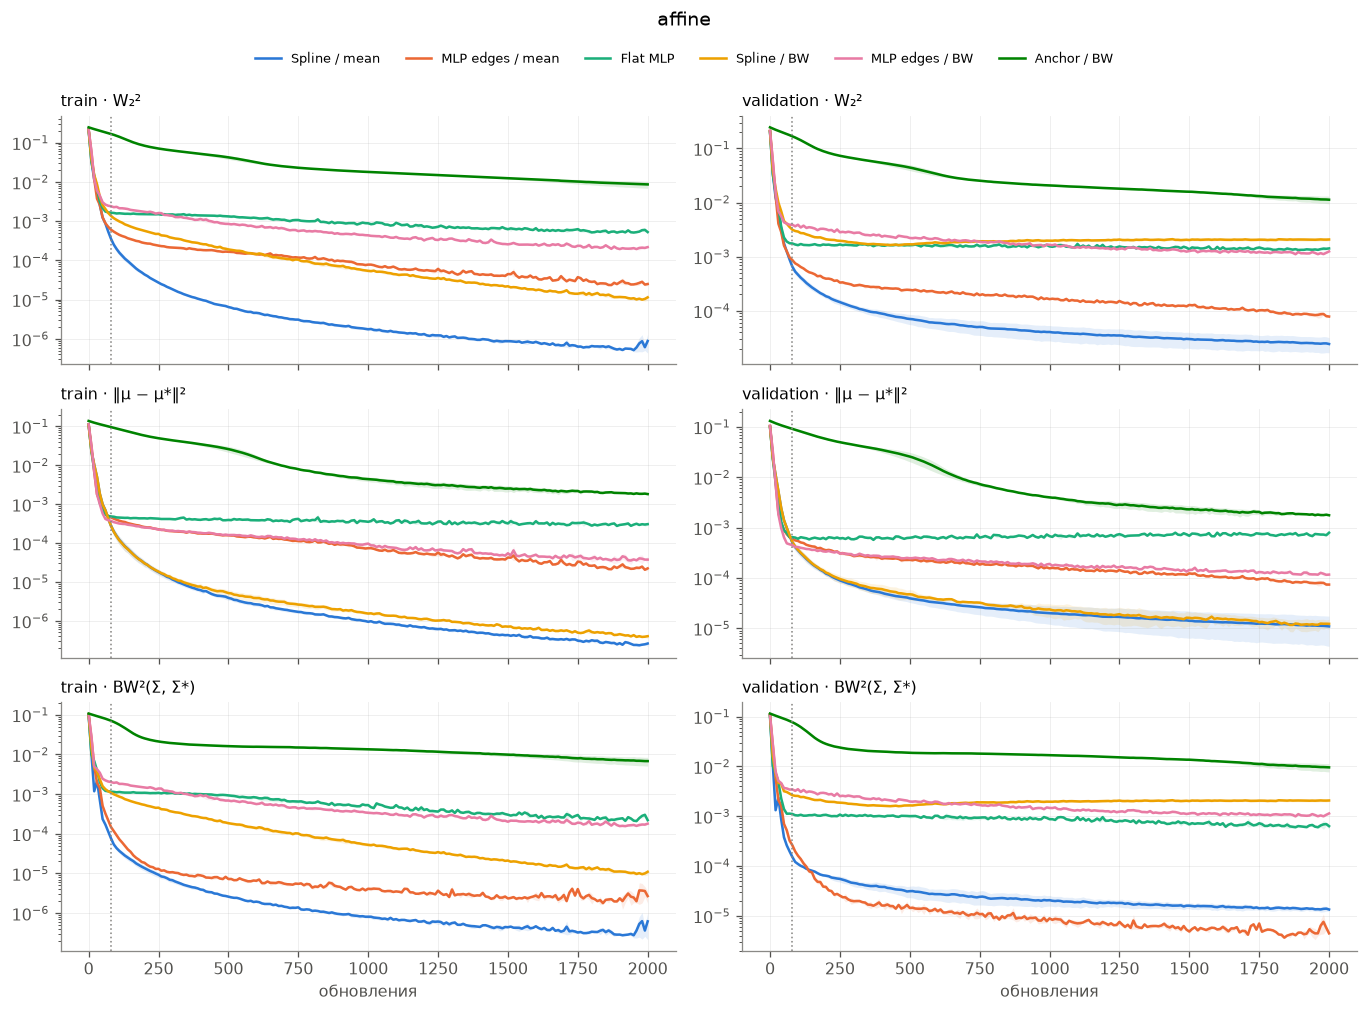

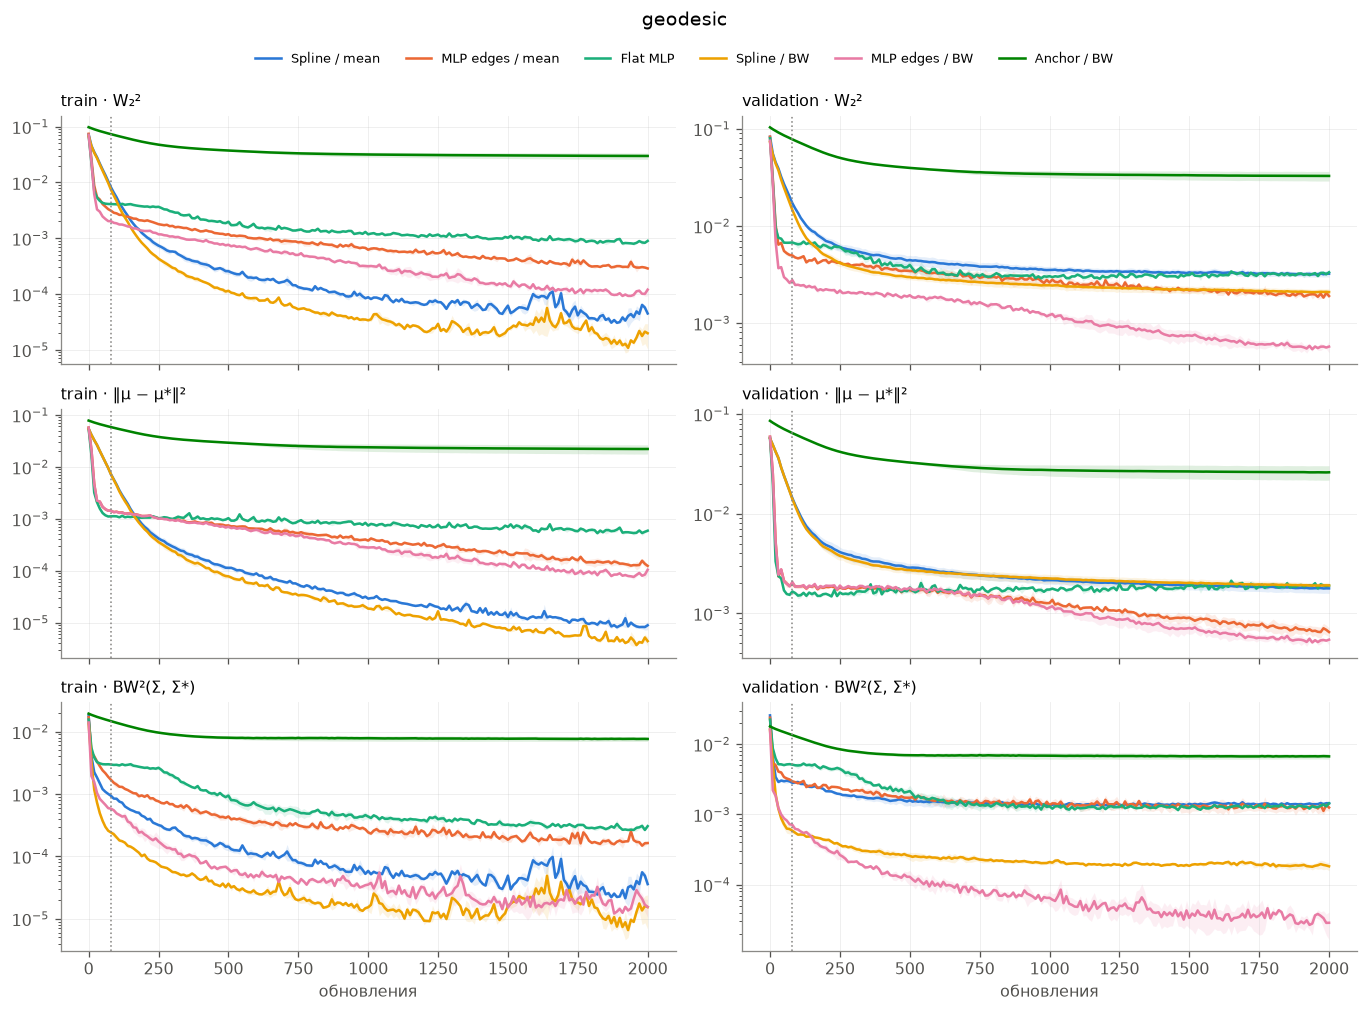

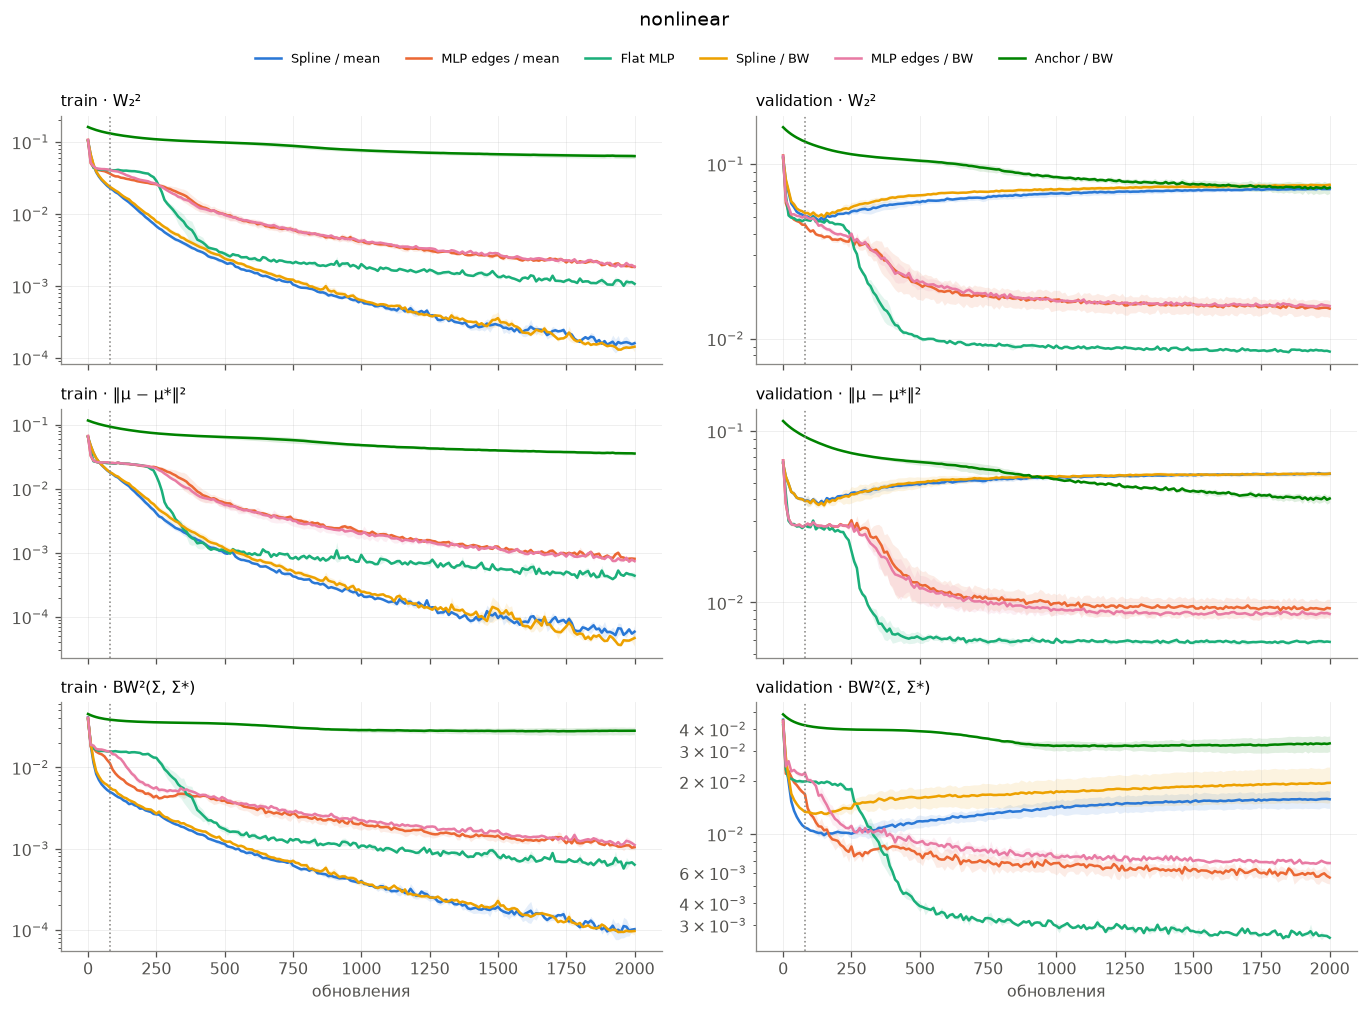

In [19]:
COMPONENTS = [('w2', 'W₂²'), ('mean_error', '‖μ − μ*‖²'), ('cov_error', 'BW²(Σ, Σ*)')]

def plot_curves(v, tasks, title_note=''):
    store = Store(v['tag'])
    curves = {rid: store.load_curve(rid) for rid in v['runs'].run_id}
    for task in tasks:
        fig, axs = plt.subplots(3, 2, figsize=(12, 8.5), sharex=True)
        drawn = False
        for model in MODELS:
            ids = v['runs'][(v['runs'].task == task) & (v['runs'].model == model)].run_id
            if not len(ids): continue
            dfs = [curves[i] for i in ids]; steps = dfs[0].step.values; drawn = True
            for row, (key, _) in enumerate(COMPONENTS):
                for col, part in enumerate(('train', 'val')):
                    vals = np.stack([d[f'{part}_{key}'].values for d in dfs])
                    ax = axs[row, col]
                    ax.plot(steps, vals.mean(0), color=MODEL_COLORS[model], label=model if row == col == 0 else None)
                    if len(dfs) > 1:
                        ax.fill_between(steps, vals.min(0), vals.max(0), color=MODEL_COLORS[model], alpha=.12, lw=0)
        if not drawn:
            plt.close(fig); continue
        for row, (_, label) in enumerate(COMPONENTS):
            for col, part in enumerate(('train', 'validation')):
                ax = axs[row, col]; ax.set_yscale('log'); ax.grid(alpha=.2, lw=.6)
                ax.set_title(f'{part} · {label}', fontsize=10, loc='left')
                if v['steps'] > v['early']:
                    ax.axvline(v['early'], color='#8a8986', lw=1, ls=':')
        for ax in axs[-1]: ax.set_xlabel('обновления')
        fig.legend(loc='upper center', ncol=6, fontsize=8, frameon=False, bbox_to_anchor=(.5, 1.0))
        fig.suptitle(f'{task}{title_note}', y=1.03, fontsize=12)
        plt.tight_layout(); plt.show()

V_A = with_tasks(view_with_fallback('long_training'), TASKS)
if V_A is not None:
    plot_curves(V_A, TASKS, '' if not V_A['smoke'] else ' · smoke, 80 обновлений')

### Лучший checkpoint шагов 0–80 против лучшего за весь прогон

На одной и той же траектории. `val_full / val_80` < 1 означает, что длинное обучение улучшило validation.
`best_at_last_eval` — число прогонов, где лучший шаг совпал с последней оценкой: это признак незавершённого улучшения,
а не доказательство сходимости. Ниже — сверка `best80` с исходной тетрадкой.

val_80  val_full   test_80  test_full  \
task      model                                                       
affine    Spline / mean     0.000651  0.000024  0.000633   0.000032   
          MLP edges / mean  0.000863  0.000076  0.000747   0.000069   
          Flat MLP          0.001750  0.001300  0.001614   0.001175   
          Spline / BW       0.003146  0.001627  0.002448   0.001348   
          MLP edges / BW    0.003881  0.001109  0.003028   0.000951   
          Anchor / BW       0.167805  0.011286  0.158583   0.009309   
geodesic  Spline / mean     0.017095  0.003153  0.017032   0.003432   
          MLP edges / mean  0.004759  0.001806  0.003847   0.001377   
          Flat MLP          0.006636  0.002789  0.004733   0.001971   
          Spline / BW       0.014541  0.002067  0.014978   0.002188   
          MLP edges / BW    0.002562  0.000526  0.002239   0.000546   
          Anchor / BW       0.077642  0.032589  0.078744   0.032593   
nonlinear Spline / mean     0.050046  0.047495  0.044065   0.043697   
          MLP edges / mean  0.044117  0.014784  0.040310   0.012308   
          Flat MLP          0.047048  0.008337  0.042009   0.006222   
          Spline / BW       0.052362  0.049851  0.044727   0.045414   
          MLP edges / BW    0.048829  0.015071  0.044954   0.012406   
          Anchor / BW       0.134383  0.072164  0.126708   0.069046   

                            best_steps  best_at_last_eval  runs  \
task      model                                                   
affine    Spline / mean     2000, 1970                  1     2   
          MLP edges / mean  2000, 1960                  1     2   
          Flat MLP          1800, 1980                  0     2   
          Spline / BW         500, 460                  0     2   
          MLP edges / BW    1880, 1880                  0     2   
          Anchor / BW       2000, 2000                  2     2   
geodesic  Spline / mean     1820, 1950                  0     2   
          MLP edges / mean  1960, 1980                  0     2   
          Flat MLP           1080, 950                  0     2   
          Spline / BW       1950, 2000                  1     2   
          MLP edges / BW    1940, 1920                  0     2   
          Anchor / BW       1920, 1970                  0     2   
nonlinear Spline / mean       130, 150                  0     2   
          MLP edges / mean  1950, 1910                  0     2   
          Flat MLP          1850, 2000                  1     2   
          Spline / BW         150, 150                  0     2   
          MLP edges / BW    1500, 1800                  0     2   
          Anchor / BW       1920, 1990                  0     2   

                            val_full/val_80  
task      model                              
affine    Spline / mean            0.037108  
          MLP edges / mean         0.088564  
          Flat MLP                 0.743091  
          Spline / BW              0.517145  
          MLP edges / BW           0.285704  
          Anchor / BW              0.067255  
geodesic  Spline / mean            0.184439  
          MLP edges / mean         0.379438  
          Flat MLP                 0.420275  
          Spline / BW              0.142183  
          MLP edges / BW           0.205364  
          Anchor / BW              0.419732  
nonlinear Spline / mean            0.949034  
          MLP edges / mean         0.335112  
          Flat MLP                 0.177195  
          Spline / BW              0.952043  
          MLP edges / BW           0.308642  
          Anchor / BW              0.537004

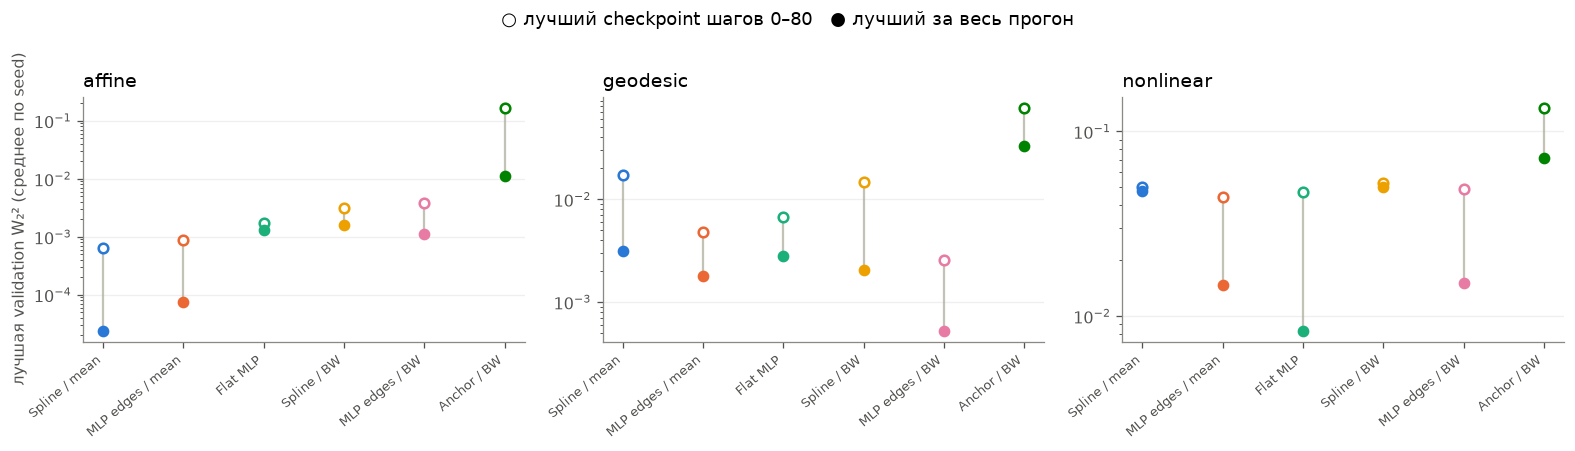

Сверка best80 с исходной тетрадкой (36 прогонов): макс. |Δ| test 4.9e-06, OOD 4.7e-06 (точность печати 5e-6); лучшие шаги совпадают: True


In [20]:
def early_vs_full(v):
    m = v['met'][v['met'].split.isin(['test', 'ood'])]
    t = m.pivot_table(index='run_id', columns=['ckpt', 'split'], values='w2')
    t.columns = [f'{s}_{c}' for c, s in t.columns]
    df = v['runs'].set_index('run_id')[['task', 'model', 'data_seed', 'train_seed', 'lr', 'best80_step',
                                       'best80_val_w2', 'best_step', 'best_val_w2', 'best_is_last_eval']].join(t)
    agg = df.groupby(['task', 'model'], sort=False).agg(
        val_80=('best80_val_w2', 'mean'), val_full=('best_val_w2', 'mean'),
        test_80=('test_best80', 'mean'), test_full=('test_best', 'mean'),
        best_steps=('best_step', lambda s: ', '.join(map(str, s))),
        best_at_last_eval=('best_is_last_eval', 'sum'), runs=('best_step', 'size'))
    agg['val_full/val_80'] = agg.val_full / agg.val_80
    order = [(t, m) for t in ALL_TASKS for m in MODELS if (t, m) in agg.index]
    return df, agg.loc[order]

def plot_early_vs_full(agg, tasks):
    fig, axs = plt.subplots(1, len(tasks), figsize=(4.6*len(tasks), 3.8), sharey=False)
    for ax, task in zip(np.atleast_1d(axs), tasks):
        sub = agg.loc[task].reindex([m for m in MODELS if m in agg.loc[task].index])
        x = np.arange(len(sub))
        for i, (model, row) in enumerate(sub.iterrows()):
            ax.plot([i, i], [row.val_80, row.val_full], color='#c3c2b7', lw=1.4, zorder=1)
            ax.scatter(i, row.val_80, s=36, facecolor='white', edgecolor=MODEL_COLORS[model], lw=1.6, zorder=2)
            ax.scatter(i, row.val_full, s=40, color=MODEL_COLORS[model], zorder=3)
        ax.set_yscale('log'); ax.set_title(task, loc='left'); ax.grid(axis='y', alpha=.2)
        ax.set_xticks(x, sub.index, rotation=40, ha='right', fontsize=8)
    np.atleast_1d(axs)[0].set_ylabel('лучшая validation W₂² (среднее по seed)')
    fig.suptitle('○ лучший checkpoint шагов 0–80   ● лучший за весь прогон', fontsize=11, y=1.02)
    plt.tight_layout(); plt.show()

if V_A is not None:
    EARLY_DF, EARLY = early_vs_full(V_A)
    display(EARLY.round(6))
    if not V_A['smoke']:
        plot_early_vs_full(EARLY, [t for t in TASKS if t in EARLY.index.get_level_values(0)])
    par = EARLY_DF[(EARLY_DF.data_seed == DATA_SEED_ORIGINAL) & (EARLY_DF.lr == 0.003)].copy()
    par['ref'] = [REFERENCE_80.get((r.task, r.train_seed, r.model)) for r in par.itertuples()]
    par = par[par.ref.notna()]
    if len(par):
        err_test = (par.test_best80 - par.ref.map(lambda d: d['test'])).abs().max()
        err_ood = (par.ood_best80 - par.ref.map(lambda d: d['ood'])).abs().max()
        same_step = (par.best80_step == par.ref.map(lambda d: d['best_step'])).all()
        print(f'Сверка best80 с исходной тетрадкой ({n_runs(len(par))}): макс. |Δ| test {err_test:.1e}, '
              f'OOD {err_ood:.1e} (точность печати 5e-6); лучшие шаги совпадают: {same_step}')

### Test и OOD при лучшем checkpoint

Общая ошибка и её компоненты. `ood_id` — контрольный ID-набор из тех же базовых случайных величин, что OOD-варианты.

In [21]:
if V_A is not None:
    for metric in ('w2', 'mean_error', 'cov_error'):
        print(f'{metric}:')
        display(split_table(V_A['met'], ['test', 'ood_id', 'ood_mean', 'ood_cov', 'ood'], metric).round(5))

w2:


task               affine                                     geodesic  \
split                test   ood_id ood_mean  ood_cov      ood     test   
model                                                                    
Spline / mean     0.00003  0.00004  0.00942  0.00048  0.01016  0.00343   
MLP edges / mean  0.00007  0.00007  0.00802  0.00022  0.01008  0.00138   
Flat MLP          0.00118  0.00134  0.01949  0.01062  0.03237  0.00197   
Spline / BW       0.00135  0.00168  0.02367  0.04160  0.07338  0.00219   
MLP edges / BW    0.00095  0.00147  0.01111  0.02372  0.03941  0.00055   
Anchor / BW       0.00931  0.00971  0.06454  0.06792  0.13191  0.03259   

task                                                 nonlinear           \
split              ood_id ood_mean  ood_cov      ood      test   ood_id   
model                                                                     
Spline / mean     0.00422  0.04930  0.05533  0.12034   0.04370  0.04460   
MLP edges / mean  0.00166  0.02050  0.02480  0.04897   0.01231  0.01257   
Flat MLP          0.00234  0.03181  0.02759  0.06061   0.00622  0.00613   
Spline / BW       0.00230  0.03798  0.01486  0.06113   0.04541  0.04749   
MLP edges / BW    0.00042  0.01757  0.00101  0.02012   0.01241  0.01515   
Anchor / BW       0.03194  0.13391  0.05691  0.16232   0.06905  0.07157   

task                                         
split            ood_mean  ood_cov      ood  
model                                        
Spline / mean     0.13015  0.07204  0.18653  
MLP edges / mean  0.12761  0.04279  0.21594  
Flat MLP          0.10737  0.01300  0.14324  
Spline / BW       0.14673  0.10060  0.22100  
MLP edges / BW    0.12280  0.06729  0.21688  
Anchor / BW       0.21302  0.13759  0.31379

mean_error:


task               affine                                     geodesic  \
split                test   ood_id ood_mean  ood_cov      ood     test   
model                                                                    
Spline / mean     0.00002  0.00001  0.00889  0.00010  0.00891  0.00155   
MLP edges / mean  0.00006  0.00007  0.00801  0.00019  0.01002  0.00065   
Flat MLP          0.00064  0.00057  0.01851  0.00085  0.02205  0.00132   
Spline / BW       0.00006  0.00004  0.01243  0.00026  0.01258  0.00195   
MLP edges / BW    0.00011  0.00011  0.00863  0.00028  0.01104  0.00052   
Anchor / BW       0.00136  0.00162  0.04819  0.00294  0.05106  0.02500   

task                                                 nonlinear           \
split              ood_id ood_mean  ood_cov      ood      test   ood_id   
model                                                                     
Spline / mean     0.00169  0.02887  0.00663  0.04232   0.03361  0.03447   
MLP edges / mean  0.00058  0.01897  0.00107  0.02233   0.00773  0.00707   
Flat MLP          0.00129  0.03065  0.00189  0.03429   0.00419  0.00374   
Spline / BW       0.00204  0.03533  0.01066  0.05253   0.03387  0.03408   
MLP edges / BW    0.00039  0.01751  0.00081  0.01982   0.00686  0.00727   
Anchor / BW       0.02403  0.12569  0.02405  0.12733   0.03960  0.04157   

task                                         
split            ood_mean  ood_cov      ood  
model                                        
Spline / mean     0.08751  0.04303  0.10088  
MLP edges / mean  0.05627  0.01820  0.06638  
Flat MLP          0.06440  0.00437  0.06294  
Spline / BW       0.08776  0.04117  0.09932  
MLP edges / BW    0.05497  0.01902  0.06877  
Anchor / BW       0.11716  0.04567  0.11469

cov_error:


task               affine                                     geodesic  \
split                test   ood_id ood_mean  ood_cov      ood     test   
model                                                                    
Spline / mean     0.00002  0.00003  0.00053  0.00038  0.00125  0.00189   
MLP edges / mean  0.00000  0.00000  0.00001  0.00003  0.00006  0.00072   
Flat MLP          0.00053  0.00077  0.00099  0.00977  0.01032  0.00065   
Spline / BW       0.00128  0.00165  0.01124  0.04134  0.06079  0.00024   
MLP edges / BW    0.00084  0.00136  0.00248  0.02344  0.02837  0.00003   
Anchor / BW       0.00795  0.00808  0.01635  0.06498  0.08086  0.00759   

task                                                 nonlinear           \
split              ood_id ood_mean  ood_cov      ood      test   ood_id   
model                                                                     
Spline / mean     0.00253  0.02043  0.04870  0.07802   0.01009  0.01012   
MLP edges / mean  0.00108  0.00153  0.02374  0.02664   0.00458  0.00550   
Flat MLP          0.00105  0.00116  0.02570  0.02632   0.00204  0.00239   
Spline / BW       0.00026  0.00265  0.00420  0.00860   0.01154  0.01341   
MLP edges / BW    0.00003  0.00006  0.00019  0.00030   0.00554  0.00788   
Anchor / BW       0.00791  0.00822  0.03286  0.03499   0.02945  0.03000   

task                                         
split            ood_mean  ood_cov      ood  
model                                        
Spline / mean     0.04264  0.02901  0.08566  
MLP edges / mean  0.07135  0.02459  0.14956  
Flat MLP          0.04297  0.00864  0.08030  
Spline / BW       0.05897  0.05944  0.12168  
MLP edges / BW    0.06782  0.04827  0.14811  
Anchor / BW       0.09586  0.09193  0.19911

## 13. Парные сравнения: тип рёбер и агрегация

Пары сравниваются внутри одного seed данных и seed обучения: одинаковые данные и батчи,
у пар mean/BW ещё и одинаковая инициализация. Точка — один seed. log₁₀(A/B) < 0 — у A меньше ошибка.
Вывод о превосходстве по одному минимальному значению не делается. Смотрите знак по всем точкам и в обеих компонентах.

test: среднее геометрическое отношение A/B и число seed, где A лучше


/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuffix='_a', rsuffix='_b', how='inner')
/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuffix='_a', rsuffix='_b', how='inner')
/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuffix='_a', rsuffix='_b', how='inner')
/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuff

ratio_geomean                       \
metric                                          w2 mean_error cov_error   
pair                       task                                           
spline vs MLP-рёбра · mean affine            0.443      0.253     2.854   
                           geodesic          2.475      2.364     2.578   
                           nonlinear         3.552      4.364     2.207   
spline vs MLP-рёбра · BW   affine            1.417      0.580     1.528   
                           geodesic          3.996      3.766     7.906   
                           nonlinear         3.674      4.957     2.087   
BW vs mean · сплайны       affine           44.625      3.922   113.427   
                           geodesic          0.640      1.261     0.126   
                           nonlinear         1.039      1.008     1.145   
BW vs mean · MLP-рёбра     affine           13.942      1.712   211.928   
                           geodesic          0.396      0.791     0.041   
                           nonlinear         1.005      0.887     1.211   

                                     A_better                       n  \
metric                                     w2 mean_error cov_error w2   
pair                       task                                         
spline vs MLP-рёбра · mean affine           2          2         0  2   
                           geodesic         0          0         0  2   
                           nonlinear        0          0         0  2   
spline vs MLP-рёбра · BW   affine           0          2         0  2   
                           geodesic         0          0         0  2   
                           nonlinear        0          0         0  2   
BW vs mean · сплайны       affine           0          0         0  2   
                           geodesic         2          0         2  2   
                           nonlinear        0          1         0  2   
BW vs mean · MLP-рёбра     affine           0          0         0  2   
                           geodesic         2          2         2  2   
                           nonlinear        1          2         0  2   

                                                           
metric                               mean_error cov_error  
pair                       task                            
spline vs MLP-рёбра · mean affine             2         2  
                           geodesic           2         2  
                           nonlinear          2         2  
spline vs MLP-рёбра · BW   affine             2         2  
                           geodesic           2         2  
                           nonlinear          2         2  
BW vs mean · сплайны       affine             2         2  
                           geodesic           2         2  
                           nonlinear          2         2  
BW vs mean · MLP-рёбра     affine             2         2  
                           geodesic           2         2  
                           nonlinear          2         2

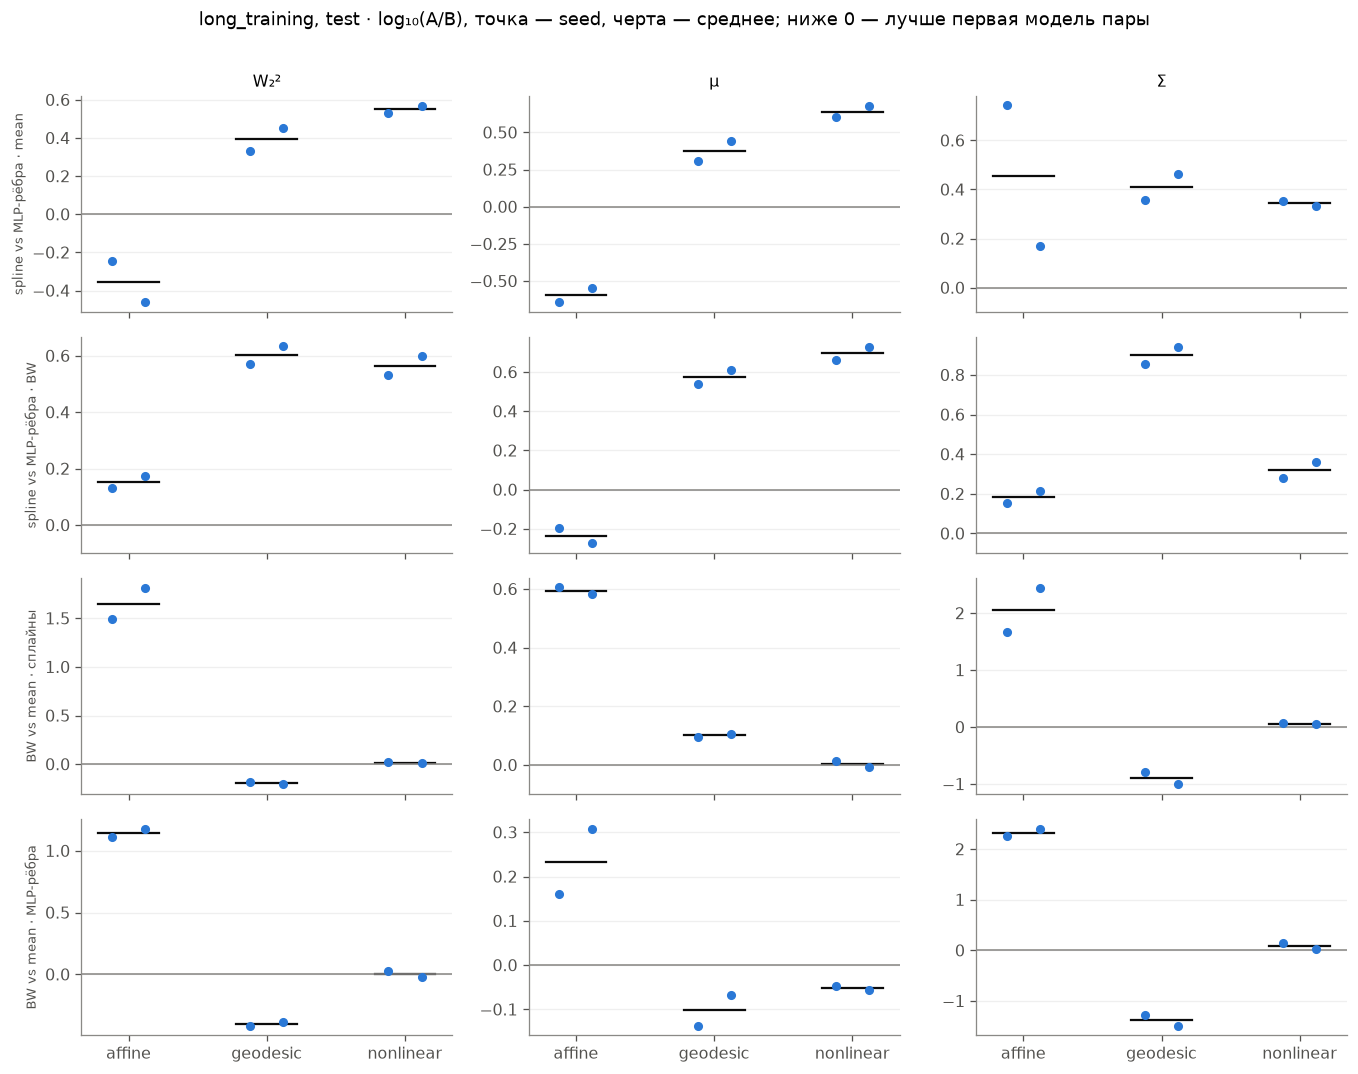

ood: среднее геометрическое отношение A/B и число seed, где A лучше


/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuffix='_a', rsuffix='_b', how='inner')
/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuffix='_a', rsuffix='_b', how='inner')
/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuffix='_a', rsuffix='_b', how='inner')
/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuff

ratio_geomean                       \
metric                                          w2 mean_error cov_error   
pair                       task                                           
spline vs MLP-рёбра · mean affine            1.008      0.889    22.104   
                           geodesic          2.459      1.891     2.928   
                           nonlinear         0.864      1.519     0.573   
spline vs MLP-рёбра · BW   affine            1.862      1.139     2.143   
                           geodesic          3.034      2.640    28.706   
                           nonlinear         1.021      1.444     0.824   
BW vs mean · сплайны       affine            7.227      1.412    48.656   
                           geodesic          0.507      1.240     0.109   
                           nonlinear         1.185      0.985     1.420   
BW vs mean · MLP-рёбра     affine            3.914      1.103   501.898   
                           geodesic          0.411      0.889     0.011   
                           nonlinear         1.003      1.036     0.988   

                                     A_better                       n  \
metric                                     w2 mean_error cov_error w2   
pair                       task                                         
spline vs MLP-рёбра · mean affine           1          2         0  2   
                           geodesic         0          0         0  2   
                           nonlinear        2          0         2  2   
spline vs MLP-рёбра · BW   affine           0          0         0  2   
                           geodesic         0          0         0  2   
                           nonlinear        1          0         2  2   
BW vs mean · сплайны       affine           0          0         0  2   
                           geodesic         2          0         2  2   
                           nonlinear        0          2         0  2   
BW vs mean · MLP-рёбра     affine           0          0         0  2   
                           geodesic         2          2         2  2   
                           nonlinear        1          0         1  2   

                                                           
metric                               mean_error cov_error  
pair                       task                            
spline vs MLP-рёбра · mean affine             2         2  
                           geodesic           2         2  
                           nonlinear          2         2  
spline vs MLP-рёбра · BW   affine             2         2  
                           geodesic           2         2  
                           nonlinear          2         2  
BW vs mean · сплайны       affine             2         2  
                           geodesic           2         2  
                           nonlinear          2         2  
BW vs mean · MLP-рёбра     affine             2         2  
                           geodesic           2         2  
                           nonlinear          2         2

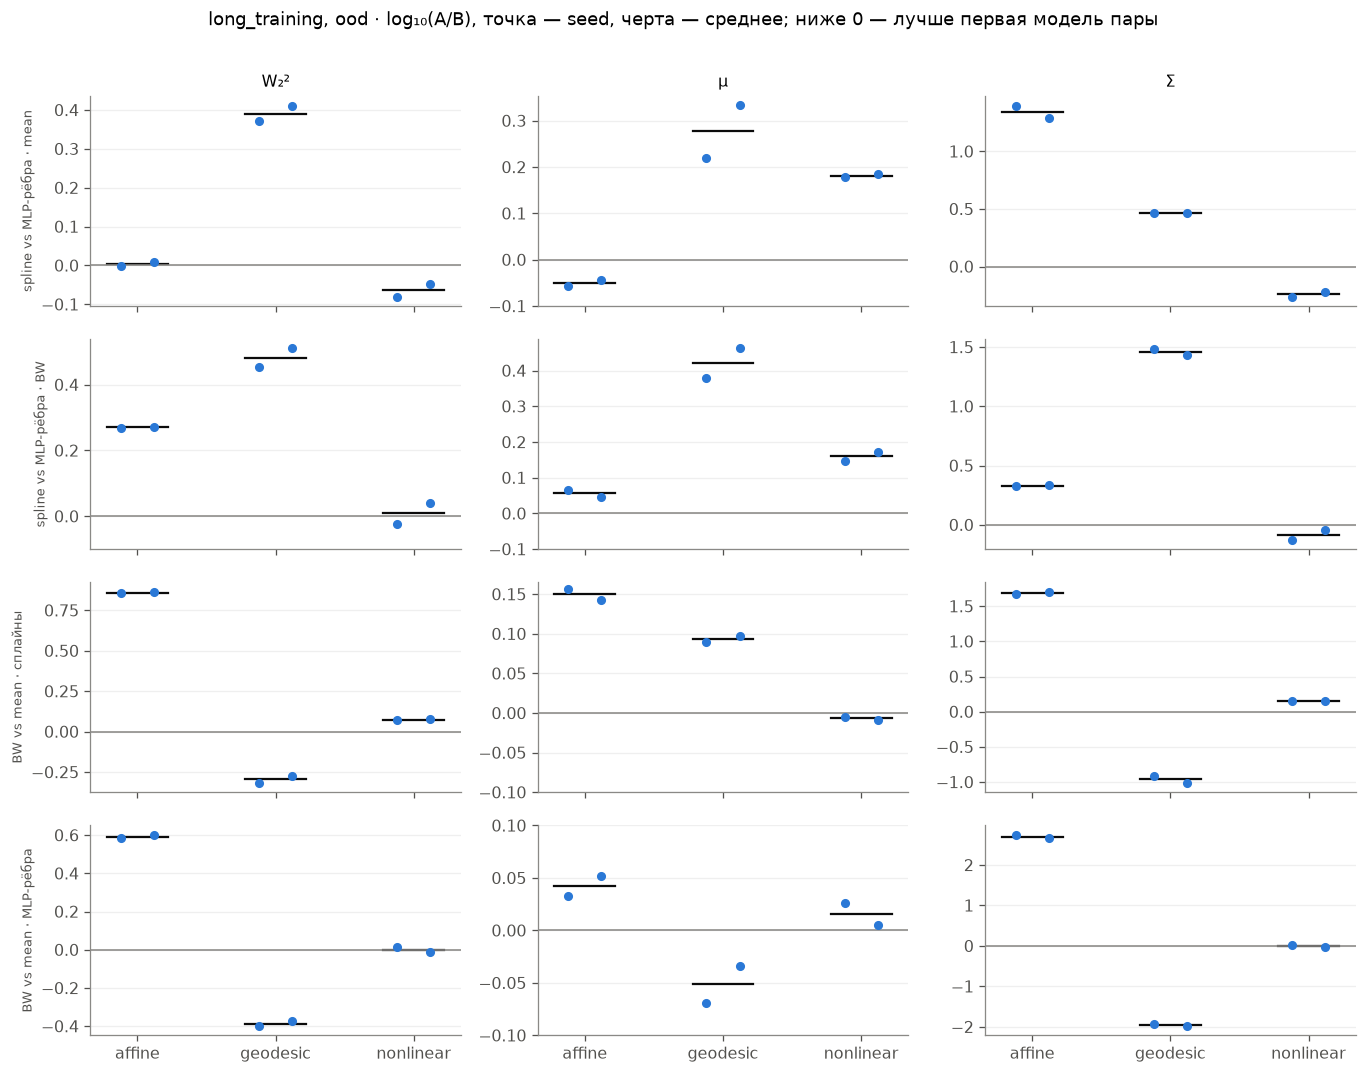

In [22]:
PAIRS = [('Spline / mean', 'MLP edges / mean', 'spline vs MLP-рёбра · mean'),
         ('Spline / BW', 'MLP edges / BW', 'spline vs MLP-рёбра · BW'),
         ('Spline / BW', 'Spline / mean', 'BW vs mean · сплайны'),
         ('MLP edges / BW', 'MLP edges / mean', 'BW vs mean · MLP-рёбра')]

def paired(met, split='test', ckpt='best'):
    m = met[(met.split == split) & (met.ckpt == ckpt)]
    keys = ['task', 'data_seed', 'train_seed']
    rows = []
    for a, b, label in PAIRS:
        A = m[m.model == a].set_index(keys); B = m[m.model == b].set_index(keys)
        j = A.join(B, lsuffix='_a', rsuffix='_b', how='inner')
        for idx, row in j.iterrows():
            for metric in ('w2', 'mean_error', 'cov_error'):
                rows.append(dict(pair=label, a=a, b=b, task=idx[0], data_seed=idx[1], train_seed=idx[2], metric=metric,
                                 log10_ratio=float(np.log10(row[f'{metric}_a'] / row[f'{metric}_b']))))
    return pd.DataFrame(rows)

def paired_summary(pr):
    return (pr.groupby(['pair', 'task', 'metric'], sort=False).log10_ratio
              .agg(ratio_geomean=lambda s: 10**s.mean(), A_better=lambda s: int((s < 0).sum()), n='size')
              .unstack('metric'))

def plot_paired(pr, title):
    metrics = [('w2', 'W₂²'), ('mean_error', 'μ'), ('cov_error', 'Σ')]
    pairs = list(dict.fromkeys(pr.pair)); tasks = [t for t in ALL_TASKS if t in set(pr.task)]
    fig, axs = plt.subplots(len(pairs), 3, figsize=(12, 2.3*len(pairs)), sharex=True, squeeze=False)
    for i, pair in enumerate(pairs):
        for j, (metric, label) in enumerate(metrics):
            ax = axs[i, j]; sub = pr[(pr.pair == pair) & (pr.metric == metric)]
            for k, task in enumerate(tasks):
                vals = sub[sub.task == task].log10_ratio.values
                jitter = np.linspace(-.12, .12, len(vals)) if len(vals) > 1 else np.zeros(1)
                ax.scatter(k + jitter[:len(vals)], vals, s=22, color='#2a78d6', zorder=3)
                if len(vals): ax.plot([k - .22, k + .22], [vals.mean()] * 2, color='#0b0b0b', lw=1.4)
            ax.axhline(0, color='#8a8986', lw=1); ax.grid(axis='y', alpha=.2)
            lo, hi = ax.get_ylim()   # не меньше ±0.1 (≈ ±26 %), чтобы крошечные различия не выглядели большими
            ax.set_ylim(min(lo, -.1), max(hi, .1))
            ax.set_xticks(range(len(tasks)), tasks)
            if i == 0: ax.set_title(label, fontsize=10)
            if j == 0: ax.set_ylabel(pair, fontsize=8)
    fig.suptitle(f'{title} · log₁₀(A/B), точка — seed, черта — среднее; ниже 0 — лучше первая модель пары',
                 fontsize=11, y=1.01)
    plt.tight_layout(); plt.show()

if V_A is not None:
    for split in ('test', 'ood'):
        pr = paired(V_A['met'], split)
        if len(pr):
            print(f'{split}: среднее геометрическое отношение A/B и число seed, где A лучше')
            display(paired_summary(pr).round(3))
            if not V_A['smoke']: plot_paired(pr, f'{V_A["stage"]}, {split}')

## 14. Flat MLP, необучаемые baseline и Anchor отдельно

Flat MLP проверяет, нужны ли гауссовы состояния между слоями. Baseline — среднее параметров
и BW-барицентр без обучения. Anchor / BW — отдельная гипотеза с 162 параметрами против 2483–2520,
поэтому она показана отдельной таблицей, а не в общем ряду.

In [23]:
if V_A is not None:
    ds = sorted(V_A['runs'].data_seed.unique())
    bl = BASELINES[BASELINES.data_seed.isin(ds) & BASELINES.task.isin(TASKS)]
    learned = V_A['met'][(V_A['met'].ckpt == 'best') & V_A['met'].model.isin(MODELS[:5])]
    tab = pd.concat([learned, bl.assign(ckpt='best')])
    t = tab[tab.split.isin(['test', 'ood'])].pivot_table(index='model', columns=['task', 'split'], values='w2')
    order = [m for m in MODELS[:5] + ['Mean, no training', 'BW, no training'] if m in t.index]
    print('W₂² (среднее по seed):'); display(t.loc[order].round(5))
    anc = V_A['met'][(V_A['met'].ckpt == 'best') & (V_A['met'].model == 'Anchor / BW') & V_A['met'].split.isin(['test', 'ood'])]
    if len(anc):
        a = anc.pivot_table(index='model', columns=['task', 'split'], values=['w2', 'mean_error', 'cov_error'])
        mb = bl[(bl.model == 'Mean, no training') & bl.split.isin(['test', 'ood'])].pivot_table(
            index='model', columns=['task', 'split'], values=['w2', 'mean_error', 'cov_error'])
        print('Anchor / BW (162 параметра) против необученного среднего:')
        display(pd.concat([a, mb]).round(5))

W₂² (среднее по seed):


task                affine          geodesic          nonlinear         
split                  ood     test      ood     test       ood     test
model                                                                   
Spline / mean      0.01016  0.00003  0.12034  0.00343   0.18653  0.04370
MLP edges / mean   0.01008  0.00007  0.04897  0.00138   0.21594  0.01231
Flat MLP           0.03237  0.00118  0.06061  0.00197   0.14324  0.00622
Spline / BW        0.07338  0.00135  0.06113  0.00219   0.22100  0.04541
MLP edges / BW     0.03941  0.00095  0.02012  0.00055   0.21688  0.01241
Mean, no training  0.31258  0.21137  0.29063  0.07518   0.21285  0.09936
BW, no training    0.34662  0.21293  0.24670  0.07024   0.27155  0.09928

Anchor / BW (162 параметра) против необученного среднего:


cov_error                                                \
task                 affine          geodesic          nonlinear            
split                   ood     test      ood     test       ood     test   
model                                                                       
Anchor / BW         0.08086  0.00795  0.03499  0.00759   0.19911  0.02945   
Mean, no training   0.15950  0.09773  0.09486  0.01787   0.09598  0.03744   

                  mean_error                                                \
task                  affine          geodesic          nonlinear            
split                    ood     test      ood     test       ood     test   
model                                                                        
Anchor / BW          0.05106  0.00136  0.12733  0.02500   0.11469  0.03960   
Mean, no training    0.15307  0.11364  0.19577  0.05731   0.11688  0.06192   

                        w2                                                
task                affine          geodesic          nonlinear           
split                  ood     test      ood     test       ood     test  
model                                                                     
Anchor / BW        0.13191  0.00931  0.16232  0.03259   0.31379  0.06905  
Mean, no training  0.31258  0.21137  0.29063  0.07518   0.21285  0.09936

## 15. Этап B: подбор learning rate

Таблица — средняя по seed лучшая validation $W_2^2$ для каждого lr. Выбранный lr отмечен.
Ниже два среза выводов: **одинаковый lr** (0.003 у всех) и **одинаковый бюджет настройки**
(у каждой модели 3 lr × 2 seed × 2000 обновлений, выбор по validation). Test и OOD оцениваются только для выбранных конфигураций.

In [24]:
V_B = stage_view('lr_search')
if V_B is not None:
    lr_tab = V_B['runs'].pivot_table(index=['task', 'model'], columns='lr', values='best_val_w2', aggfunc='mean')
    try:
        SELECTED = load_selected_lr(ANALYSIS_TAG)
    except RuntimeError:
        SELECTED = None
        if V_B['complete']:
            select_learning_rates(ANALYSIS_TAG); SELECTED = load_selected_lr(ANALYSIS_TAG)
    if SELECTED:
        lr_tab['selected_lr'] = [SELECTED.get(idx) for idx in lr_tab.index]
    display(lr_tab.round(6))
    if SELECTED:
        met = V_B['met']
        chosen = met[[SELECTED.get((t, m)) == lr for t, m, lr in zip(met.task, met.model, met.lr)]]
        same = met[met.lr == 0.003]
        for label, mm in (('одинаковый lr = 0.003', same), ('выбранный lr (одинаковый бюджет настройки)', chosen)):
            print(label + ': W₂²')
            display(split_table(mm, ['test', 'ood']).round(5))
            pr = paired(mm, 'test')
            if len(pr):
                display(paired_summary(pr)['ratio_geomean'].round(3))
else:
    print('Нет результатов этапа B.')

lr_search [main]: готово 108/108, failed 0


lr                             0.001     0.003      0.01  selected_lr
task      model                                                      
affine    Anchor / BW       0.027178  0.011286  0.005511        0.010
          Flat MLP          0.001425  0.001300  0.001328        0.003
          MLP edges / BW    0.001853  0.001109  0.001127        0.003
          MLP edges / mean  0.000194  0.000076  0.000019        0.010
          Spline / BW       0.001651  0.001627  0.001595        0.010
          Spline / mean     0.000036  0.000024  0.000097        0.003
geodesic  Anchor / BW       0.036845  0.032589  0.031933        0.010
          Flat MLP          0.002783  0.002789  0.002901        0.001
          MLP edges / BW    0.001571  0.000526  0.000394        0.010
          MLP edges / mean  0.002972  0.001806  0.001467        0.010
          Spline / BW       0.003030  0.002067  0.000628        0.010
          Spline / mean     0.004671  0.003153  0.001992        0.010
nonlinear Anchor / BW       0.097742  0.072164  0.059021        0.010
          Flat MLP          0.008692  0.008337  0.008127        0.010
          MLP edges / BW    0.017228  0.015071  0.014431        0.010
          MLP edges / mean  0.016620  0.014784  0.013786        0.010
          Spline / BW       0.049486  0.049851  0.050423        0.001
          Spline / mean     0.047685  0.047495  0.047798        0.003

одинаковый lr = 0.003: W₂²


task               affine          geodesic          nonlinear         
split                test      ood     test      ood      test      ood
model                                                                  
Spline / mean     0.00003  0.01016  0.00343  0.12034   0.04370  0.18653
MLP edges / mean  0.00007  0.01008  0.00138  0.04897   0.01231  0.21594
Flat MLP          0.00118  0.03237  0.00197  0.06061   0.00622  0.14324
Spline / BW       0.00135  0.07338  0.00219  0.06113   0.04541  0.22100
MLP edges / BW    0.00095  0.03941  0.00055  0.02012   0.01241  0.21688
Anchor / BW       0.00931  0.13191  0.03259  0.16232   0.06905  0.31379

/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuffix='_a', rsuffix='_b', how='inner')
/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuffix='_a', rsuffix='_b', how='inner')
/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuffix='_a', rsuffix='_b', how='inner')
/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuff

metric                                    w2  mean_error  cov_error
pair                       task                                    
spline vs MLP-рёбра · mean affine      0.443       0.253      2.854
                           geodesic    2.475       2.364      2.578
                           nonlinear   3.552       4.364      2.207
spline vs MLP-рёбра · BW   affine      1.417       0.580      1.528
                           geodesic    3.996       3.766      7.906
                           nonlinear   3.674       4.957      2.087
BW vs mean · сплайны       affine     44.625       3.922    113.427
                           geodesic    0.640       1.261      0.126
                           nonlinear   1.039       1.008      1.145
BW vs mean · MLP-рёбра     affine     13.942       1.712    211.928
                           geodesic    0.396       0.791      0.041
                           nonlinear   1.005       0.887      1.211

выбранный lr (одинаковый бюджет настройки): W₂²


task               affine          geodesic          nonlinear         
split                test      ood     test      ood      test      ood
model                                                                  
Spline / mean     0.00003  0.01016  0.00234  0.08455   0.04370  0.18653
MLP edges / mean  0.00002  0.00535  0.00110  0.04294   0.01276  0.21843
Flat MLP          0.00118  0.03237  0.00188  0.06045   0.00605  0.14164
Spline / BW       0.00135  0.11373  0.00073  0.04189   0.04306  0.21954
MLP edges / BW    0.00095  0.03941  0.00039  0.01670   0.01296  0.22069
Anchor / BW       0.00463  0.09680  0.03213  0.15114   0.05791  0.33583

/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuffix='_a', rsuffix='_b', how='inner')
/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuffix='_a', rsuffix='_b', how='inner')
/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuffix='_a', rsuffix='_b', how='inner')
/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuff

metric                                    w2  mean_error  cov_error
pair                       task                                    
spline vs MLP-рёбра · mean affine      1.610       0.889     25.081
                           nonlinear   3.428       4.529      1.898
                           geodesic    2.129       0.658      3.303
spline vs MLP-рёбра · BW   affine      1.424       0.663      1.523
                           nonlinear   3.330       4.805      1.761
                           geodesic    1.864       1.069     20.737
BW vs mean · сплайны       affine     44.832       4.483    113.055
                           nonlinear   0.985       0.955      1.088
                           geodesic    0.310       1.215      0.161
BW vs mean · MLP-рёбра     affine     50.711       6.010   1862.317
                           nonlinear   1.014       0.900      1.172
                           geodesic    0.354       0.748      0.026

## 16. Этап C: диагностика

### Положение на geodesic
Если отставание сплайнов на geodesic связано с вариативностью входных ковариаций, на geo_position оно должно исчезнуть.
geo_position: $\Sigma_1=\Sigma_2=I$, цель — только положение. Если отставание сохраняется, вопрос в том, как ребро
выучивает сдвиг $\mu$. `cov_error` на geo_position — отклонение предсказанной ковариации от $I$.

diagnostics [main]: готово 12/12, failed 0


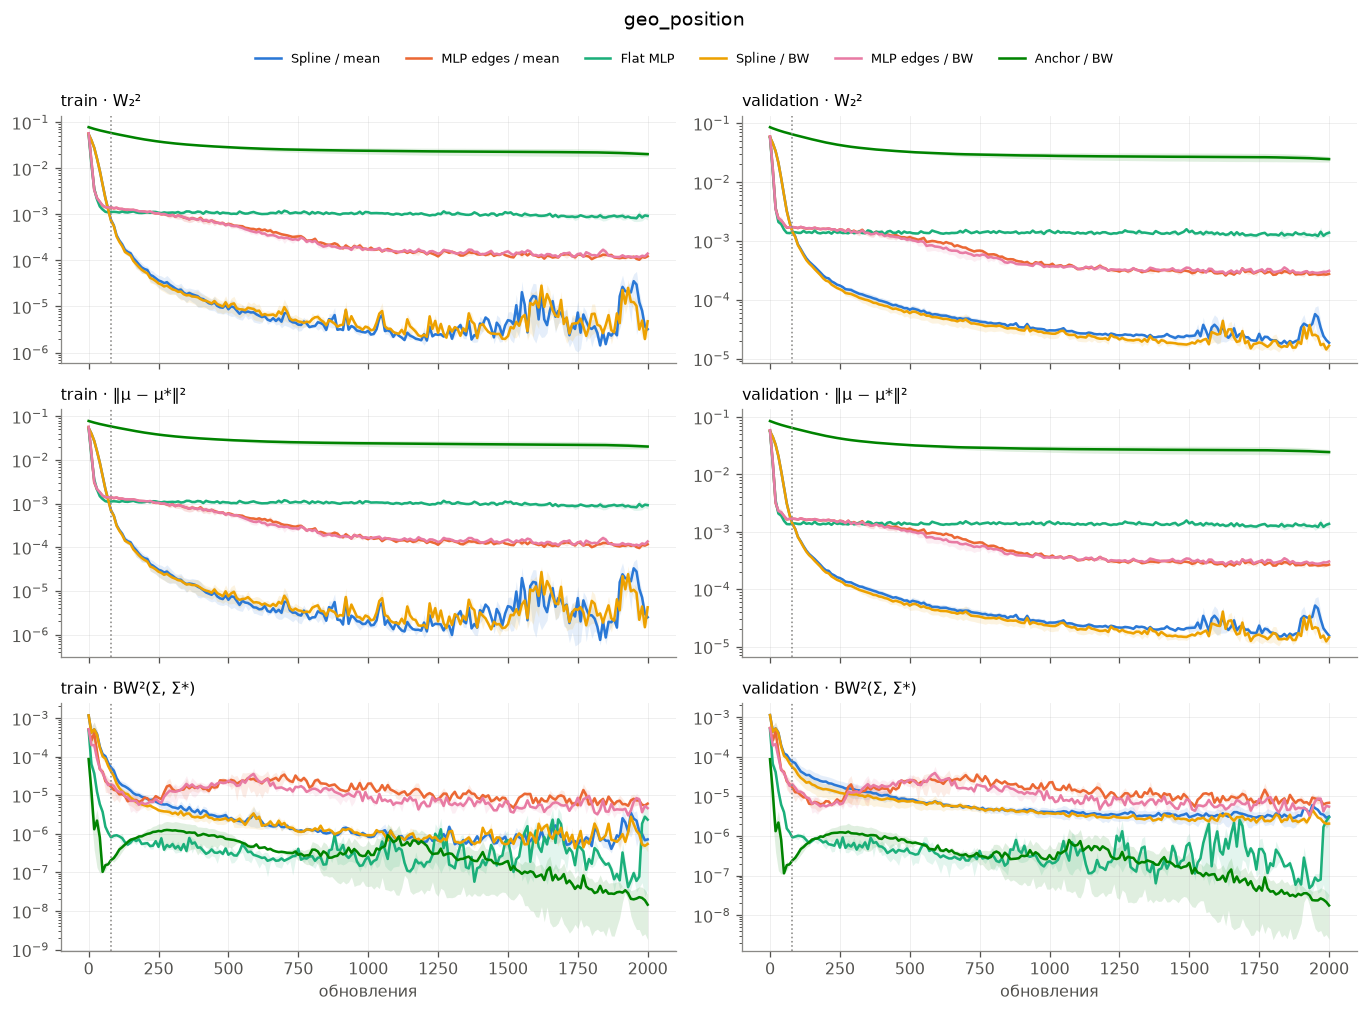

cov_error             mean_error                     w2  \
task             geo_position  geodesic geo_position  geodesic geo_position   
model                                                                         
Spline / mean        0.000035  0.001887     0.000040  0.001546     0.000075   
MLP edges / mean     0.000008  0.000725     0.000261  0.000652     0.000269   
Flat MLP             0.000000  0.000655     0.000972  0.001316     0.000972   
Spline / BW          0.000035  0.000237     0.000060  0.001951     0.000095   
MLP edges / BW       0.000004  0.000030     0.000291  0.000515     0.000296   
Anchor / BW          0.000000  0.007593     0.023106  0.025000     0.023106   

                            
task              geodesic  
model                       
Spline / mean     0.003432  
MLP edges / mean  0.001377  
Flat MLP          0.001971  
Spline / BW       0.002188  
MLP edges / BW    0.000546  
Anchor / BW       0.032593

Отношение ошибки μ, сплайн / MLP-рёбра (test):


task,geo_position,geodesic
pair,,
Spline / BW / MLP edges / BW,0.207,3.788
Spline / mean / MLP edges / mean,0.155,2.371


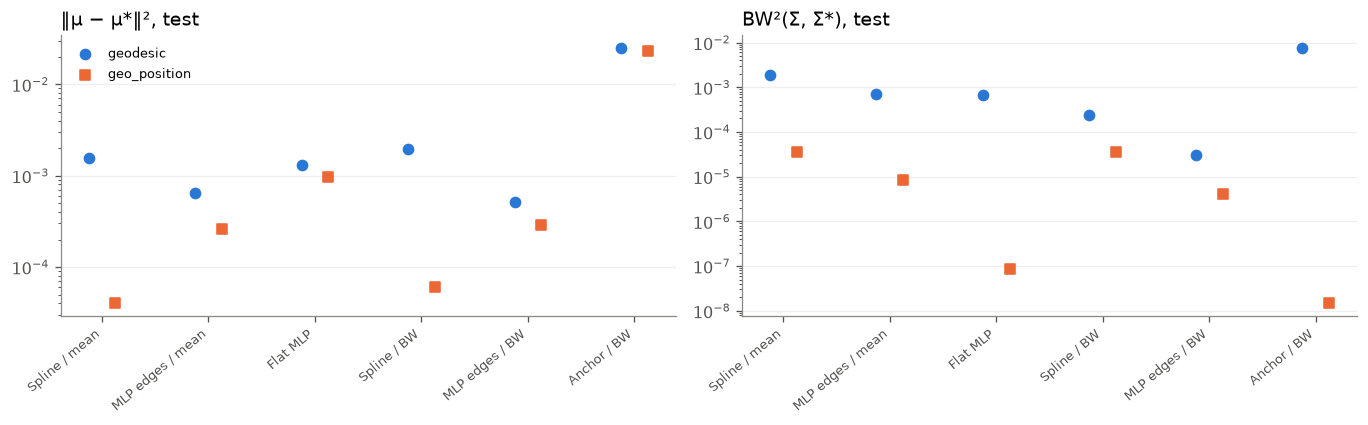

In [25]:
V_C = with_tasks(view_with_fallback('diagnostics'), ['geo_position'])
V_A_geo = with_tasks(stage_view('long_training', quiet=True) or stage_view('smoke', 'smoke', quiet=True), ['geodesic'])
if V_C is not None:
    plot_curves(V_C, ['geo_position'], '' if not V_C['smoke'] else ' · smoke, 80 обновлений')
    frames = [x['met'][(x['met'].ckpt == 'best') & (x['met'].split == 'test')] for x in (V_C, V_A_geo) if x is not None]
    both = pd.concat(frames)
    t = both.pivot_table(index='model', columns='task', values=['mean_error', 'cov_error', 'w2'])
    display(t.reindex([m for m in MODELS if m in t.index]).round(6))
    rows = []
    for spline, mlp in (('Spline / mean', 'MLP edges / mean'), ('Spline / BW', 'MLP edges / BW')):
        for task in ('geodesic', 'geo_position'):
            if ('mean_error', task) in t.columns and spline in t.index and mlp in t.index:
                rows.append(dict(pair=f'{spline} / {mlp}', task=task,
                                 mean_error_ratio=t.loc[spline, ('mean_error', task)] / t.loc[mlp, ('mean_error', task)]))
    if rows:
        print('Отношение ошибки μ, сплайн / MLP-рёбра (test):')
        display(pd.DataFrame(rows).pivot(index='pair', columns='task', values='mean_error_ratio').round(3))
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
    models = [m for m in MODELS if m in t.index]
    for ax, metric, label in ((axs[0], 'mean_error', '‖μ − μ*‖², test'), (axs[1], 'cov_error', 'BW²(Σ, Σ*), test')):
        for k, task in enumerate([x for x in ('geodesic', 'geo_position') if (metric, x) in t.columns]):
            vals = t.loc[models, (metric, task)].values
            ax.scatter(np.arange(len(models)) + (k - .5) * .25, vals, s=40, marker='o' if k == 0 else 's',
                       color=['#2a78d6', '#eb6834'][k], label=task, zorder=3)
        ax.set_yscale('log'); ax.set_title(label, loc='left'); ax.grid(axis='y', alpha=.2)
        ax.set_xticks(range(len(models)), models, rotation=40, ha='right', fontsize=8)
    axs[0].legend(fontsize=8, frameon=False)
    plt.tight_layout(); plt.show()

### Разложение nonlinear OOD
Одни и те же обученные nonlinear-модели оцениваются без дообучения на четырёх наборах из общих базовых случайных
величин: `ood_id` (без сдвига), `ood_mean`, `ood_cov`, `ood` (оба сдвига). Отдельно ошибка μ и Σ.
Напоминание: в nonlinear деформация Σ зависит от входных средних, так что рост `cov_error` на `ood_mean` — ожидаемый эффект цели,
а не обязательно слабость модели в ковариациях.

lr = 0.003, этап A: nonlinear, ошибки на OOD-вариантах


w2                            mean_error           \
split              ood_id ood_mean  ood_cov      ood     ood_id ood_mean   
model                                                                      
Spline / mean     0.04460  0.13015  0.07204  0.18653    0.03447  0.08751   
MLP edges / mean  0.01257  0.12761  0.04279  0.21594    0.00707  0.05627   
Flat MLP          0.00613  0.10737  0.01300  0.14324    0.00374  0.06440   
Spline / BW       0.04749  0.14673  0.10060  0.22100    0.03408  0.08776   
MLP edges / BW    0.01515  0.12280  0.06729  0.21688    0.00727  0.05497   
Anchor / BW       0.07157  0.21302  0.13759  0.31379    0.04157  0.11716   

                                   cov_error                             
split             ood_cov      ood    ood_id ood_mean  ood_cov      ood  
model                                                                    
Spline / mean     0.04303  0.10088   0.01012  0.04264  0.02901  0.08566  
MLP edges / mean  0.01820  0.06638   0.00550  0.07135  0.02459  0.14956  
Flat MLP          0.00437  0.06294   0.00239  0.04297  0.00864  0.08030  
Spline / BW       0.04117  0.09932   0.01341  0.05897  0.05944  0.12168  
MLP edges / BW    0.01902  0.06877   0.00788  0.06782  0.04827  0.14811  
Anchor / BW       0.04567  0.11469   0.03000  0.09586  0.09193  0.19911

Во сколько раз ошибка больше, чем на ood_id:


mean_error                         cov_error           \
split                ood_id ood_mean ood_cov    ood    ood_id ood_mean   
model                                                                    
Spline / mean           1.0     2.54    1.25   2.93       1.0     4.21   
MLP edges / mean        1.0     7.96    2.57   9.39       1.0    12.98   
Flat MLP                1.0    17.23    1.17  16.83       1.0    17.98   
Spline / BW             1.0     2.57    1.21   2.91       1.0     4.40   
MLP edges / BW          1.0     7.56    2.62   9.45       1.0     8.61   
Anchor / BW             1.0     2.82    1.10   2.76       1.0     3.20   

                                 
split            ood_cov    ood  
model                            
Spline / mean       2.87   8.46  
MLP edges / mean    4.47  27.20  
Flat MLP            3.61  33.60  
Spline / BW         4.43   9.08  
MLP edges / BW      6.13  18.81  
Anchor / BW         3.06   6.64

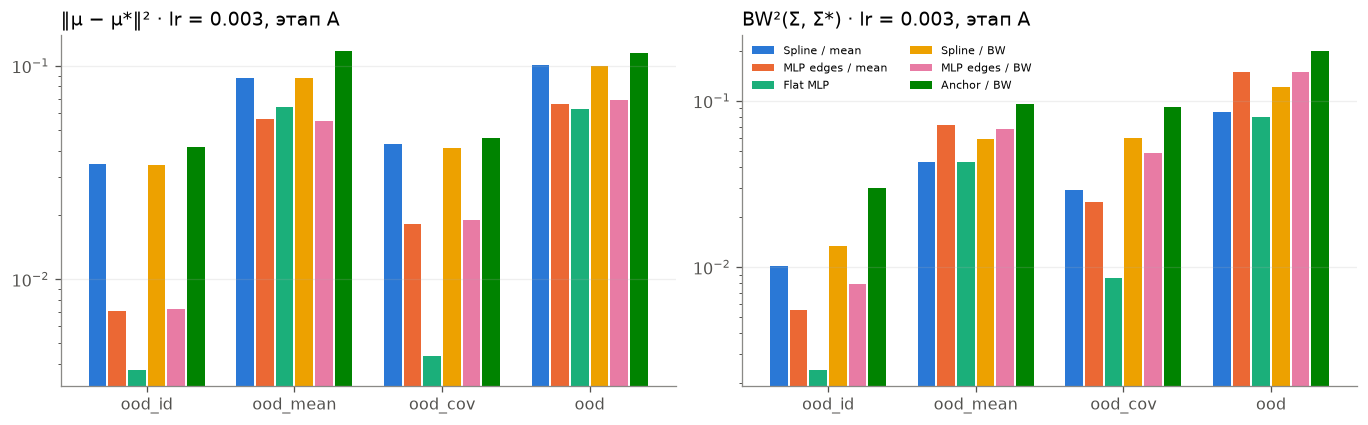

выбранный lr, этап B: nonlinear, ошибки на OOD-вариантах


w2                            mean_error           \
split              ood_id ood_mean  ood_cov      ood     ood_id ood_mean   
model                                                                      
Spline / mean     0.04460  0.13015  0.07204  0.18653    0.03447  0.08751   
MLP edges / mean  0.01411  0.12518  0.04734  0.21843    0.00810  0.06010   
Flat MLP          0.00561  0.10450  0.01317  0.14164    0.00348  0.06357   
Spline / BW       0.04659  0.14724  0.09503  0.21954    0.03295  0.08625   
MLP edges / BW    0.01446  0.13642  0.06303  0.22069    0.00657  0.06183   
Anchor / BW       0.05899  0.22490  0.12419  0.33583    0.03318  0.11978   

                                   cov_error                             
split             ood_cov      ood    ood_id ood_mean  ood_cov      ood  
model                                                                    
Spline / mean     0.04303  0.10088   0.01012  0.04264  0.02901  0.08566  
MLP edges / mean  0.01977  0.06872   0.00601  0.06508  0.02757  0.14971  
Flat MLP          0.00473  0.06247   0.00214  0.04092  0.00844  0.07917  
Spline / BW       0.03819  0.09668   0.01364  0.06100  0.05684  0.12286  
MLP edges / BW    0.01749  0.07119   0.00789  0.07459  0.04554  0.14949  
Anchor / BW       0.03716  0.12265   0.02581  0.10513  0.08703  0.21318

Во сколько раз ошибка больше, чем на ood_id:


mean_error                         cov_error           \
split                ood_id ood_mean ood_cov    ood    ood_id ood_mean   
model                                                                    
Spline / mean           1.0     2.54    1.25   2.93       1.0     4.21   
MLP edges / mean        1.0     7.42    2.44   8.48       1.0    10.83   
Flat MLP                1.0    18.29    1.36  17.97       1.0    19.16   
Spline / BW             1.0     2.62    1.16   2.93       1.0     4.47   
MLP edges / BW          1.0     9.41    2.66  10.83       1.0     9.45   
Anchor / BW             1.0     3.61    1.12   3.70       1.0     4.07   

                                 
split            ood_cov    ood  
model                            
Spline / mean       2.87   8.46  
MLP edges / mean    4.59  24.92  
Flat MLP            3.95  37.06  
Spline / BW         4.17   9.01  
MLP edges / BW      5.77  18.95  
Anchor / BW         3.37   8.26

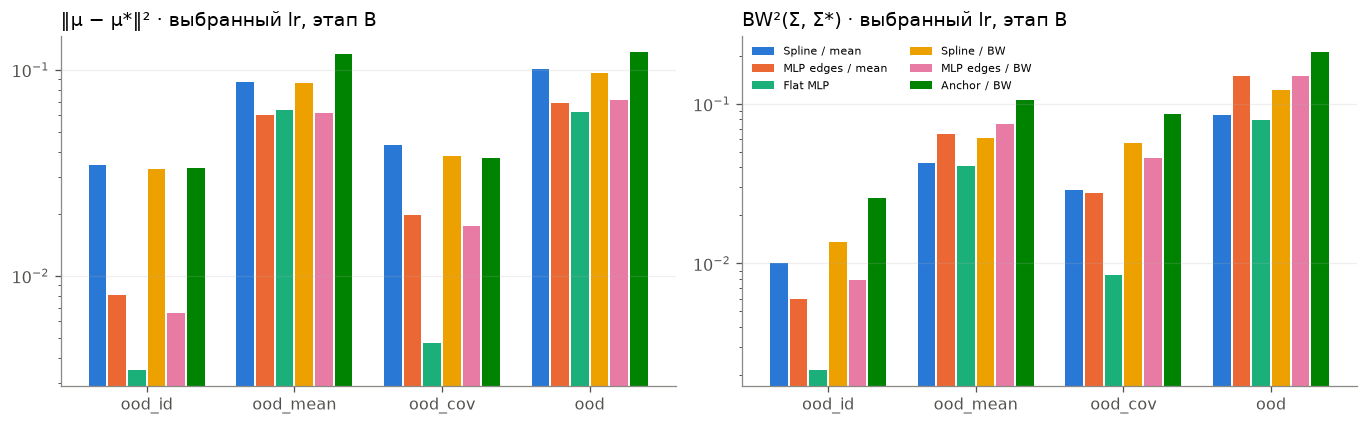

In [26]:
OOD_ORDER = ['ood_id', 'ood_mean', 'ood_cov', 'ood']
def ood_decomposition(v, label):
    m = v['met'][(v['met'].ckpt == 'best') & (v['met'].task == 'nonlinear') & v['met'].split.isin(OOD_ORDER)]
    if not len(m): return
    t = m.pivot_table(index='model', columns='split', values=['w2', 'mean_error', 'cov_error'])
    t = t.reindex([x for x in MODELS if x in t.index])
    print(f'{label}: nonlinear, ошибки на OOD-вариантах')
    display(t[[(c, s) for c in ('w2', 'mean_error', 'cov_error') for s in OOD_ORDER]].round(5))
    rel = pd.concat({c: t[c][OOD_ORDER].div(t[c]['ood_id'], axis=0) for c in ('mean_error', 'cov_error')}, axis=1)
    print('Во сколько раз ошибка больше, чем на ood_id:'); display(rel.round(2))
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), sharey=False)
    width = .8 / len(t)
    for ax, comp, title in ((axs[0], 'mean_error', '‖μ − μ*‖²'), (axs[1], 'cov_error', 'BW²(Σ, Σ*)')):
        for i, model in enumerate(t.index):
            ax.bar(np.arange(4) + (i - (len(t) - 1) / 2) * width, t.loc[model, comp][OOD_ORDER].values,
                   width=width * .9, color=MODEL_COLORS[model], label=model)
        ax.set_yscale('log'); ax.set_xticks(range(4), OOD_ORDER); ax.set_title(f'{title} · {label}', loc='left')
        ax.grid(axis='y', alpha=.2)
    axs[1].legend(fontsize=7, frameon=False, ncol=2)
    plt.tight_layout(); plt.show()

if V_A is not None:
    ood_decomposition(V_A, 'lr = 0.003' + (' · smoke' if V_A['smoke'] else ', этап A'))
if V_B is not None and SELECTED:
    vb = dict(V_B); vb['met'] = V_B['met'][[SELECTED.get((t, m)) == lr for t, m, lr in
                                           zip(V_B['met'].task, V_B['met'].model, V_B['met'].lr)]]
    ood_decomposition(vb, 'выбранный lr, этап B')

## 17. Этап D: воспроизводимость на новых выборках

Показываются отдельные прогоны, средние по датасету (по 3 seed обучения) и сводка по трём датасетам.
`std` в сводке — разброс трёх средних по датасетам, не доверительный интервал.

robustness [main]: готово 162/162, failed 0
test: отдельные прогоны, W₂²


model                           Spline / mean  MLP edges / mean  Flat MLP  \
task      data_seed train_seed                                              
affine    3000      11                0.00007           0.00005   0.00156   
                    29                0.00003           0.00003   0.00158   
                    47                0.00005           0.00004   0.00162   
          4000      11                0.00003           0.00003   0.00137   
                    29                0.00003           0.00002   0.00129   
                    47                0.00002           0.00003   0.00135   
          5000      11                0.00005           0.00004   0.00151   
                    29                0.00002           0.00003   0.00145   
                    47                0.00002           0.00004   0.00160   
geodesic  3000      11                0.00463           0.00190   0.00289   
                    29                0.00473           0.00166   0.00304   
                    47                0.00553           0.00188   0.00320   
          4000      11                0.00280           0.00144   0.00199   
                    29                0.00246           0.00125   0.00191   
                    47                0.00270           0.00131   0.00201   
          5000      11                0.00334           0.00189   0.00349   
                    29                0.00334           0.00173   0.00335   
                    47                0.00302           0.00147   0.00330   
nonlinear 3000      11                0.04787           0.01282   0.00572   
                    29                0.04716           0.01095   0.00473   
                    47                0.04729           0.01431   0.00589   
          4000      11                0.04450           0.01031   0.00393   
                    29                0.04221           0.00991   0.00423   
                    47                0.04137           0.00866   0.00418   
          5000      11                0.04019           0.01364   0.00572   
                    29                0.04143           0.01396   0.00686   
                    47                0.04182           0.01265   0.00541   

model                           Spline / BW  MLP edges / BW  Anchor / BW  
task      data_seed train_seed                                            
affine    3000      11              0.00355         0.00160      0.00533  
                    29              0.00305         0.00128      0.00584  
                    47              0.00320         0.00176      0.00536  
          4000      11              0.00147         0.00130      0.00554  
                    29              0.00146         0.00104      0.00378  
                    47              0.00162         0.00112      0.00490  
          5000      11              0.00240         0.00140      0.00770  
                    29              0.00210         0.00174      0.00641  
                    47              0.00208         0.00215      0.00552  
geodesic  3000      11              0.00135         0.00063      0.02909  
                    29              0.00107         0.00058      0.02891  
                    47              0.00168         0.00065      0.03900  
          4000      11              0.00067         0.00038      0.03667  
                    29              0.00073         0.00034      0.02488  
                    47              0.00065         0.00045      0.03578  
          5000      11              0.00057         0.00057      0.02939  
                    29              0.00118         0.00052      0.02728  
                    47              0.00086         0.00051      0.03717  
nonlinear 3000      11              0.05010         0.01760      0.06776  
                    29              0.04920         0.01846      0.07196  
                    47              0.04917         0.01520      0.06838  
          4000      11              0.043

test: среднее по seed обучения внутри датасета


model                Spline / mean  MLP edges / mean  Flat MLP  Spline / BW  \
task      data_seed                                                           
affine    3000             0.00005           0.00004   0.00159      0.00326   
          4000             0.00002           0.00003   0.00134      0.00152   
          5000             0.00003           0.00003   0.00152      0.00219   
geodesic  3000             0.00497           0.00181   0.00304      0.00137   
          4000             0.00265           0.00134   0.00197      0.00069   
          5000             0.00323           0.00170   0.00338      0.00087   
nonlinear 3000             0.04744           0.01269   0.00545      0.04949   
          4000             0.04269           0.00963   0.00411      0.04400   
          5000             0.04115           0.01342   0.00599      0.04338   

model                MLP edges / BW  Anchor / BW  
task      data_seed                               
affine    3000              0.00155      0.00551  
          4000              0.00115      0.00474  
          5000              0.00177      0.00654  
geodesic  3000              0.00062      0.03233  
          4000              0.00039      0.03244  
          5000              0.00053      0.03128  
nonlinear 3000              0.01709      0.06937  
          4000              0.01162      0.05572  
          5000              0.01779      0.06312

test: по трём датасетам (std — разброс средних датасетов, не доверительный интервал)


mean_over_datasets                    std_over_datasets  \
task                         affine geodesic nonlinear            affine   
model                                                                      
Anchor / BW                 0.00560  0.03202   0.06274           0.00090   
Flat MLP                    0.00148  0.00280   0.00519           0.00013   
MLP edges / BW              0.00149  0.00051   0.01550           0.00031   
MLP edges / mean            0.00003  0.00162   0.01191           0.00001   
Spline / BW                 0.00232  0.00097   0.04563           0.00088   
Spline / mean               0.00003  0.00362   0.04376           0.00001   

                                     
task             geodesic nonlinear  
model                                
Anchor / BW       0.00064   0.00683  
Flat MLP          0.00074   0.00097  
MLP edges / BW    0.00012   0.00338  
MLP edges / mean  0.00025   0.00201  
Spline / BW       0.00035   0.00336  
Spline / mean     0.00120   0.00328

... (5 outputs left out)

mean_over_datasets                    std_over_datasets  \
task                         affine geodesic nonlinear            affine   
model                                                                      
Anchor / BW                 0.08742  0.14636   0.31168           0.00912   
Flat MLP                    0.03231  0.05850   0.12114           0.00351   
MLP edges / BW              0.03519  0.01894   0.20959           0.00283   
MLP edges / mean            0.00584  0.04090   0.18041           0.00048   
Spline / BW                 0.07480  0.04325   0.20734           0.01480   
Spline / mean               0.00981  0.09431   0.17664           0.00590   

                                     
task             geodesic nonlinear  
model                                
Anchor / BW       0.00534   0.03631  
Flat MLP          0.00497   0.01574  
MLP edges / BW    0.00374   0.01219  
MLP edges / mean  0.00386   0.02068  
Spline / BW       0.00796   0.02259  
Spline / mean     0.02525   0.02693

Парные сравнения внутри датасета и seed (test):


/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuffix='_a', rsuffix='_b', how='inner')
/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuffix='_a', rsuffix='_b', how='inner')
/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuffix='_a', rsuffix='_b', how='inner')
/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuff

ratio_geomean                       \
metric                                          w2 mean_error cov_error   
pair                       task                                           
spline vs MLP-рёбра · mean affine            0.913      0.413     7.581   
                           geodesic          2.182      1.055     2.870   
                           nonlinear         3.716      5.474     1.870   
spline vs MLP-рёбра · BW   affine            1.522      0.259     1.662   
                           geodesic          1.819      1.055    17.433   
                           nonlinear         3.000      4.667     1.567   
BW vs mean · сплайны       affine           72.643      2.695   143.451   
                           geodesic          0.263      0.763     0.129   
                           nonlinear         1.043      0.992     1.202   
BW vs mean · MLP-рёбра     affine           43.584      4.306   654.304   
                           geodesic          0.315      0.762     0.021   
                           nonlinear         1.292      1.163     1.433   

                                     A_better                       n  \
metric                                     w2 mean_error cov_error w2   
pair                       task                                         
spline vs MLP-рёбра · mean affine           5          8         0  9   
                           geodesic         0          3         0  9   
                           nonlinear        0          0         0  9   
spline vs MLP-рёбра · BW   affine           1          9         1  9   
                           geodesic         1          3         0  9   
                           nonlinear        0          0         0  9   
BW vs mean · сплайны       affine           0          2         0  9   
                           geodesic         9          9         9  9   
                           nonlinear        1          6         0  9   
BW vs mean · MLP-рёбра     affine           0          0         0  9   
                           geodesic         9          9         9  9   
                           nonlinear        0          2         0  9   

                                                           
metric                               mean_error cov_error  
pair                       task                            
spline vs MLP-рёбра · mean affine             9         9  
                           geodesic           9         9  
                           nonlinear          9         9  
spline vs MLP-рёбра · BW   affine             9         9  
                           geodesic           9         9  
                           nonlinear          9         9  
BW vs mean · сплайны       affine             9         9  
                           geodesic           9         9  
                           nonlinear          9         9  
BW vs mean · MLP-рёбра     affine             9         9  
                           geodesic           9         9  
                           nonlinear          9         9

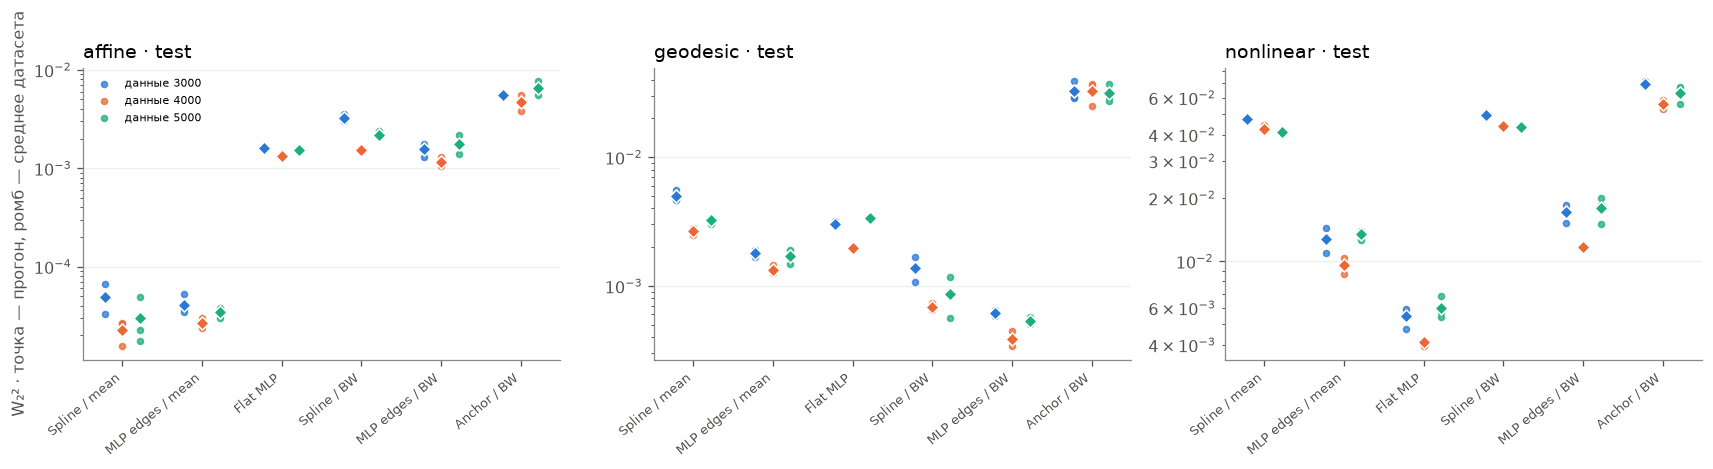

In [27]:
V_D = stage_view('robustness')
if V_D is not None:
    m = V_D['met'][(V_D['met'].ckpt == 'best')]
    for split in ('test', 'ood'):
        s = m[m.split == split]
        print(f'{split}: отдельные прогоны, W₂²')
        display(s.pivot_table(index=['task', 'data_seed', 'train_seed'], columns='model', values='w2')
                .reindex(columns=MODELS).round(5))
        per_ds = s.groupby(['task', 'model', 'data_seed']).w2.mean()
        print(f'{split}: среднее по seed обучения внутри датасета')
        display(per_ds.unstack('model').reindex(columns=MODELS).round(5))
        summ = per_ds.groupby(['task', 'model']).agg(mean_over_datasets='mean', std_over_datasets='std')
        print(f'{split}: по трём датасетам (std — разброс средних датасетов, не доверительный интервал)')
        display(summ.unstack('task').round(5))
    pr = paired(m, 'test')
    if len(pr):
        print('Парные сравнения внутри датасета и seed (test):')
        display(paired_summary(pr).round(3))
    fig, axs = plt.subplots(1, len(TASKS), figsize=(15, 3.9))
    ds_colors = dict(zip(sorted(m.data_seed.unique()), ['#2a78d6', '#eb6834', '#1baf7a']))
    for ax, task in zip(axs, TASKS):
        s = m[(m.split == 'test') & (m.task == task)]
        for i, model in enumerate(MODELS):
            for k, (ds, col) in enumerate(ds_colors.items()):
                vals = s[(s.model == model) & (s.data_seed == ds)].w2.values
                x = i + (k - 1) * .22
                ax.scatter(np.full(len(vals), x), vals, s=14, color=col, alpha=.75, zorder=2,
                           label=f'данные {ds}' if i == 0 else None)
                if len(vals): ax.scatter(x, vals.mean(), marker='D', s=34, color=col, edgecolor='white', zorder=3)
        ax.set_yscale('log'); ax.set_title(f'{task} · test', loc='left'); ax.grid(axis='y', alpha=.2)
        ax.set_xticks(range(len(MODELS)), MODELS, rotation=40, ha='right', fontsize=8)
    axs[0].legend(fontsize=7, frameon=False); axs[0].set_ylabel('W₂² · точка — прогон, ромб — среднее датасета')
    plt.tight_layout(); plt.show()
else:
    print('Нет результатов этапа D.')

## 18. Численная корректность и неудачные прогоны

По каждому тегу с результатами:
- максимальный относительный остаток BW-итерации на 32 test-примерах на слой;
- максимальное $W_2^2$-расхождение с 40 итерациями;
- минимальное собственное значение предсказанных ковариаций по всем срезам;
- доля конечных выходов.

`bary_iters` нигде не увеличивается автоматически. Если остаток заметен, это повод для отдельного эксперимента.

In [28]:
for tag in dict.fromkeys([ANALYSIS_TAG, 'smoke']):
    runs, met = load_results(tag)
    if not len(runs):
        print(f'[{tag}] результатов нет'); continue
    done = runs[runs.status == 'done']
    diag = done.groupby('model').agg(runs=('run_id', 'size'), bary_residual_max=('bary_residual_max', 'max'),
                                     bary_vs_40iter_w2max=('bary_vs_40iter_w2max', 'max'))
    if len(met):
        diag = diag.join(met.groupby('model').agg(min_eig=('min_eig', 'min'), finite_share=('finite', 'mean'),
                                                  symmetry_error_max=('symmetry_error', 'max')))
    print(f'[{tag}] готово {len(done)}, failed {int((runs.status == "failed").sum())}')
    display(diag.reindex([m for m in MODELS if m in diag.index]))
    if diag.bary_residual_max.max() > 1e-5:
        warnings.warn(f'[{tag}] остаток BW > 1e-5: оформите отдельный эксперимент с другим bary_iters')
    failed = runs[runs.status == 'failed']
    if len(failed):
        display(failed[['run_id', 'stage', 'error']])

[main] готово 282, failed 0


,runs,bary_residual_max,bary_vs_40iter_w2max,min_eig,finite_share,symmetry_error_max
model,,,,,,
Spline / mean,47,NaN,NaN,0.056963,1.0,0.0
MLP edges / mean,47,NaN,NaN,0.065025,1.0,0.0
Flat MLP,47,NaN,NaN,0.065710,1.0,0.0
Spline / BW,47,7.647295e-11,3.552714e-15,0.050452,1.0,0.0
MLP edges / BW,47,4.145412e-07,3.742784e-12,0.045478,1.0,0.0
Anchor / BW,47,1.787189e-09,3.552714e-15,0.053096,1.0,0.0


[smoke] готово 24, failed 0


,runs,bary_residual_max,bary_vs_40iter_w2max,min_eig,finite_share,symmetry_error_max
model,,,,,,
Spline / mean,4,NaN,NaN,0.105685,1.0,0.0
MLP edges / mean,4,NaN,NaN,0.100986,1.0,0.0
Flat MLP,4,NaN,NaN,0.103193,1.0,0.0
Spline / BW,4,4.589474e-16,2.664535e-15,0.110863,1.0,0.0
MLP edges / BW,4,1.988065e-15,1.776357e-15,0.089315,1.0,0.0
Anchor / BW,4,6.659541e-16,2.664535e-15,0.190264,1.0,0.0


## 19. Выводы из полученных результатов

Текст формируется из файлов результатов. Он разделяет три вещи:
- **наблюдение** — число из таблиц;
- **возможное объяснение** — то, что следует из разложения ошибки на μ и Σ;
- **непроверенную гипотезу** — то, для чего здесь нет эксперимента.

Если доступен только smoke, текст помечен как проверка генерации.

In [29]:
def fmt(x): return f'{x:.2e}' if x < 1e-3 else f'{x:.5f}'

def conclusions():
    obs, expl = [], []
    v = stage_view('long_training', quiet=True)
    p = STAGES['long_training']
    src = (f'этап A: {p["steps"]} обновлений, lr = {p["lrs"][0]}, seeds обучения {p["train_seeds"]}, '
           f'данные {p["data_seeds"][0]}')
    if v is None:
        v = stage_view('smoke', 'smoke', quiet=True)
        src = 'smoke: 80 обновлений, seed 11 — **только проверка генерации текста, не выводы**'
    if v is None:
        return '_Результатов пока нет._'
    if not v['complete'] and not v['smoke']:
        src += f' — **неполный: готово {n_runs(len(v["runs"]))}**'
    v = with_tasks(v, TASKS); met = v['met'][v['met'].ckpt == 'best']
    for task in TASKS:
        s = met[(met.task == task) & (met.split == 'test')]
        if not len(s): continue
        avg = s.groupby('model').w2.mean().sort_values()
        first, second = avg.index[0], avg.index[1]
        per = s.pivot_table(index=['data_seed', 'train_seed'], columns='model', values='w2')
        k = int((per[first] < per[second]).sum())
        obs.append(f'`{task}` test: наименьшая средняя W₂² у **{first}** ({fmt(avg[first])}), следующая — '
                   f'{second} ({fmt(avg[second])}); порядок этой пары тот же в {k} из {len(per)} seed.')
    if v['steps'] > v['early']:
        r = v['runs']
        obs.append(f'Лучший checkpoint на последней оценке (шаг {v["steps"]}) в {int(r.best_is_last_eval.sum())} из {len(r)} '
                   f'прогонов; медиана val_full/val_80 = {float((r.best_val_w2 / r.best80_val_w2).median()):.3f}.')
    pr = paired(met, 'test')
    if len(pr):
        g = pr.groupby(['pair', 'a', 'b', 'task', 'metric'], sort=False).log10_ratio.mean().unstack('metric')
        for (pair, a, b, task), row in g.iterrows():
            if abs(row['w2']) < np.log10(1.25): continue
            n_a = int((pr[(pr.pair == pair) & (pr.task == task) & (pr.metric == 'w2')].log10_ratio < 0).sum())
            n = int(((pr.pair == pair) & (pr.task == task) & (pr.metric == 'w2')).sum())
            obs.append(f'`{task}`, {a} / {b}: отношение W₂² = {10**row["w2"]:.2f} (среднее геометрическое по seed); '
                       f'{a} лучше в {n_a} из {n} seed.')
            if abs(row['mean_error']) > 2 * abs(row['cov_error']):
                expl.append(f'{pair}, `{task}`: разница сосредоточена в μ (отношение {10**row["mean_error"]:.2f} против '
                            f'{10**row["cov_error"]:.2f} для Σ) — речь о том, как модель выучивает сдвиг средних.')
            elif abs(row['cov_error']) > 2 * abs(row['mean_error']):
                expl.append(f'{pair}, `{task}`: разница сосредоточена в Σ (отношение {10**row["cov_error"]:.2f} против '
                            f'{10**row["mean_error"]:.2f} для μ).')
    o = met[(met.task == 'nonlinear') & met.split.isin(['ood_id', 'ood_mean', 'ood_cov'])]
    if len(o):
        t = o.pivot_table(index='model', columns='split', values=['mean_error', 'cov_error'])
        for model in [m for m in ('Spline / mean', 'MLP edges / mean') if m in t.index]:
            obs.append(f'nonlinear, {model}: относительно ood_id сдвиг средних увеличивает ошибку μ в '
                       f'{t.loc[model, ("mean_error", "ood_mean")] / t.loc[model, ("mean_error", "ood_id")]:.1f} раза '
                       f'и Σ в {t.loc[model, ("cov_error", "ood_mean")] / t.loc[model, ("cov_error", "ood_id")]:.1f} раза; '
                       f'сдвиг анизотропии — μ в {t.loc[model, ("mean_error", "ood_cov")] / t.loc[model, ("mean_error", "ood_id")]:.1f}, '
                       f'Σ в {t.loc[model, ("cov_error", "ood_cov")] / t.loc[model, ("cov_error", "ood_id")]:.1f} раза.')
    vc = with_tasks(stage_view('diagnostics', quiet=True), ['geo_position'])
    if vc is not None:
        gm = vc['met'][(vc['met'].ckpt == 'best') & (vc['met'].split == 'test')].groupby('model').mean_error.mean()
        gd = met[(met.task == 'geodesic') & (met.split == 'test')].groupby('model').mean_error.mean()
        for sp, ml in (('Spline / mean', 'MLP edges / mean'), ('Spline / BW', 'MLP edges / BW')):
            if sp in gm and ml in gm and sp in gd and ml in gd:
                r_gd, r_gm = gd[sp] / gd[ml], gm[sp] / gm[ml]
                obs.append(f'Отношение ошибки μ {sp} к {ml} (test): geodesic {r_gd:.2f}, geo_position (Σ₁ = Σ₂ = I) {r_gm:.2f}.')
                if r_gd > 2 and r_gm < 1.25:
                    expl.append(f'{sp} vs {ml}: отставание сплайнов по μ на geodesic исчезает, когда входные ковариации '
                                'фиксированы (= I). Значит, оно связано с вариативностью Σ на входе ребра, а не с самим '
                                'усреднением μ. Механизм этим экспериментом не установлен.')
                elif r_gd > 2 and r_gm > 2:
                    expl.append(f'{sp} vs {ml}: отставание сплайнов по μ сохраняется и при Σ = I, то есть не объясняется '
                                'вариативностью входных ковариаций.')
    try:
        sel = load_selected_lr(ANALYSIS_TAG)
        by_lr = {}
        for (t, m), lr in sel.items():
            by_lr.setdefault(lr, []).append(f'{m} / {t}')
        obs.append('Этап B, выбранный по validation lr: ' + '; '.join(
            f'{lr:g} — {len(v)} из {len(sel)} пар' + (f' ({", ".join(v)})' if len(v) <= 4 else '')
            for lr, v in sorted(by_lr.items())) + '.')
    except RuntimeError:
        pass
    vd = stage_view('robustness', quiet=True)
    if vd is not None:
        s = vd['met'][(vd['met'].ckpt == 'best') & (vd['met'].split == 'test')]
        for task in TASKS:
            per_ds = s[s.task == task].groupby(['data_seed', 'model']).w2.mean().unstack()
            if per_ds.empty: continue
            winners = per_ds.idxmin(axis=1)
            obs.append(f'Этап D, `{task}`: модель с наименьшей средней test W₂² по датасетам — '
                       + ', '.join(f'{ds}: {w}' for ds, w in winners.items()) + '.')
    hyp = ['Равномерная сетка сплайна (8 интервалов) по tanh-координатам может хуже передавать почти линейный сдвиг μ, '
           'чем MLP с tanh. Не проверено: нужен отдельный эксперимент с размером сетки, вне рамок этой версии.',
           'Входной tanh(·/coord_scale) насыщается на сдвинутых средних, это может объяснять рост ошибки μ на ood_mean. '
           'Не проверено напрямую: нужна доля насыщенных координат на каждом наборе.',
           'BW-агрегация может помогать на geodesic, потому что цель — точка BW-геодезической между входами. '
           'Но используемый барицентр невзвешенный, то есть не совпадает с целью структурно. Не проверено.',
           'Слабость Anchor / BW может быть следствием одного ориентира на ребро и 162 параметров, '
           'а не BW-геометрии как таковой. Не проверено: несколько ориентиров в этой версии намеренно не добавлены.']
    parts = [f'**Источник:** {src}.', '', '**Наблюдения**'] + [f'- {x}' for x in obs]
    parts += ['', '**Возможные объяснения** (из разложения ошибки на μ и Σ)'] + ([f'- {x}' for x in expl] or ['- —'])
    parts += ['', '**Непроверенные гипотезы**'] + [f'- {x}' for x in hyp]
    return '\n'.join(parts)

display(Markdown(conclusions()))

/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuffix='_a', rsuffix='_b', how='inner')
/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuffix='_a', rsuffix='_b', how='inner')
/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuffix='_a', rsuffix='_b', how='inner')
/tmp/ipykernel_19608/1360013136.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = A.join(B, lsuff

**Источник:** этап A: 2000 обновлений, lr = 0.003, seeds обучения [11, 29], данные 2000.

**Наблюдения**
- `affine` test: наименьшая средняя W₂² у **Spline / mean** (3.20e-05), следующая — MLP edges / mean (6.85e-05); порядок этой пары тот же в 2 из 2 seed.
- `geodesic` test: наименьшая средняя W₂² у **MLP edges / BW** (5.46e-04), следующая — MLP edges / mean (0.00138); порядок этой пары тот же в 2 из 2 seed.
- `nonlinear` test: наименьшая средняя W₂² у **Flat MLP** (0.00622), следующая — MLP edges / mean (0.01231); порядок этой пары тот же в 2 из 2 seed.
- Лучший checkpoint на последней оценке (шаг 2000) в 6 из 36 прогонов; медиана val_full/val_80 = 0.311.
- `affine`, Spline / mean / MLP edges / mean: отношение W₂² = 0.44 (среднее геометрическое по seed); Spline / mean лучше в 2 из 2 seed.
- `geodesic`, Spline / mean / MLP edges / mean: отношение W₂² = 2.48 (среднее геометрическое по seed); Spline / mean лучше в 0 из 2 seed.
- `nonlinear`, Spline / mean / MLP edges / mean: отношение W₂² = 3.55 (среднее геометрическое по seed); Spline / mean лучше в 0 из 2 seed.
- `affine`, Spline / BW / MLP edges / BW: отношение W₂² = 1.42 (среднее геометрическое по seed); Spline / BW лучше в 0 из 2 seed.
- `geodesic`, Spline / BW / MLP edges / BW: отношение W₂² = 4.00 (среднее геометрическое по seed); Spline / BW лучше в 0 из 2 seed.
- `nonlinear`, Spline / BW / MLP edges / BW: отношение W₂² = 3.67 (среднее геометрическое по seed); Spline / BW лучше в 0 из 2 seed.
- `affine`, Spline / BW / Spline / mean: отношение W₂² = 44.63 (среднее геометрическое по seed); Spline / BW лучше в 0 из 2 seed.
- `geodesic`, Spline / BW / Spline / mean: отношение W₂² = 0.64 (среднее геометрическое по seed); Spline / BW лучше в 2 из 2 seed.
- `affine`, MLP edges / BW / MLP edges / mean: отношение W₂² = 13.94 (среднее геометрическое по seed); MLP edges / BW лучше в 0 из 2 seed.
- `geodesic`, MLP edges / BW / MLP edges / mean: отношение W₂² = 0.40 (среднее геометрическое по seed); MLP edges / BW лучше в 2 из 2 seed.
- nonlinear, Spline / mean: относительно ood_id сдвиг средних увеличивает ошибку μ в 2.5 раза и Σ в 4.2 раза; сдвиг анизотропии — μ в 1.2, Σ в 2.9 раза.
- nonlinear, MLP edges / mean: относительно ood_id сдвиг средних увеличивает ошибку μ в 8.0 раза и Σ в 13.0 раза; сдвиг анизотропии — μ в 2.6, Σ в 4.5 раза.
- Отношение ошибки μ Spline / mean к MLP edges / mean (test): geodesic 2.37, geo_position (Σ₁ = Σ₂ = I) 0.16.
- Отношение ошибки μ Spline / BW к MLP edges / BW (test): geodesic 3.79, geo_position (Σ₁ = Σ₂ = I) 0.21.
- Этап B, выбранный по validation lr: 0.001 — 2 из 18 пар (Flat MLP / geodesic, Spline / BW / nonlinear); 0.003 — 4 из 18 пар (Flat MLP / affine, MLP edges / BW / affine, Spline / mean / affine, Spline / mean / nonlinear); 0.01 — 12 из 18 пар.
- Этап D, `affine`: модель с наименьшей средней test W₂² по датасетам — 3000: MLP edges / mean, 4000: Spline / mean, 5000: Spline / mean.
- Этап D, `geodesic`: модель с наименьшей средней test W₂² по датасетам — 3000: MLP edges / BW, 4000: MLP edges / BW, 5000: MLP edges / BW.
- Этап D, `nonlinear`: модель с наименьшей средней test W₂² по датасетам — 3000: Flat MLP, 4000: Flat MLP, 5000: Flat MLP.

**Возможные объяснения** (из разложения ошибки на μ и Σ)
- spline vs MLP-рёбра · BW, `nonlinear`: разница сосредоточена в μ (отношение 4.96 против 2.09 для Σ) — речь о том, как модель выучивает сдвиг средних.
- BW vs mean · сплайны, `affine`: разница сосредоточена в Σ (отношение 113.43 против 3.92 для μ).
- BW vs mean · сплайны, `geodesic`: разница сосредоточена в Σ (отношение 0.13 против 1.26 для μ).
- BW vs mean · MLP-рёбра, `affine`: разница сосредоточена в Σ (отношение 211.93 против 1.71 для μ).
- BW vs mean · MLP-рёбра, `geodesic`: разница сосредоточена в Σ (отношение 0.04 против 0.79 для μ).
- Spline / mean vs MLP edges / mean: отставание сплайнов по μ на geodesic исчезает, когда входные ковариации фиксированы (= I). Значит, оно связано с вариативностью Σ на входе ребра, а не с самим усреднением μ. Механизм этим экспериментом не установлен.
- Spline / BW vs MLP edges / BW: отставание сплайнов по μ на geodesic исчезает, когда входные ковариации фиксированы (= I). Значит, оно связано с вариативностью Σ на входе ребра, а не с самим усреднением μ. Механизм этим экспериментом не установлен.

**Непроверенные гипотезы**
- Равномерная сетка сплайна (8 интервалов) по tanh-координатам может хуже передавать почти линейный сдвиг μ, чем MLP с tanh. Не проверено: нужен отдельный эксперимент с размером сетки, вне рамок этой версии.
- Входной tanh(·/coord_scale) насыщается на сдвинутых средних, это может объяснять рост ошибки μ на ood_mean. Не проверено напрямую: нужна доля насыщенных координат на каждом наборе.
- BW-агрегация может помогать на geodesic, потому что цель — точка BW-геодезической между входами. Но используемый барицентр невзвешенный, то есть не совпадает с целью структурно. Не проверено.
- Слабость Anchor / BW может быть следствием одного ориентира на ребро и 162 параметров, а не BW-геометрии как таковой. Не проверено: несколько ориентиров в этой версии намеренно не добавлены.

## 20. Смотрим, что выучило ребро

На первом слое Anchor/BW рисуем $t(G)$ как функцию расстояния до ориентира.
Это не полная функция $G\mapsto G'$: направление зависит от самого входа и от ориентира.
График показывает только контроллер длины шага. Разные рёбра имеют собственные ориентиры.

Модели загружаются с диска: nonlinear, seed 11, этап A, а если его нет — smoke.

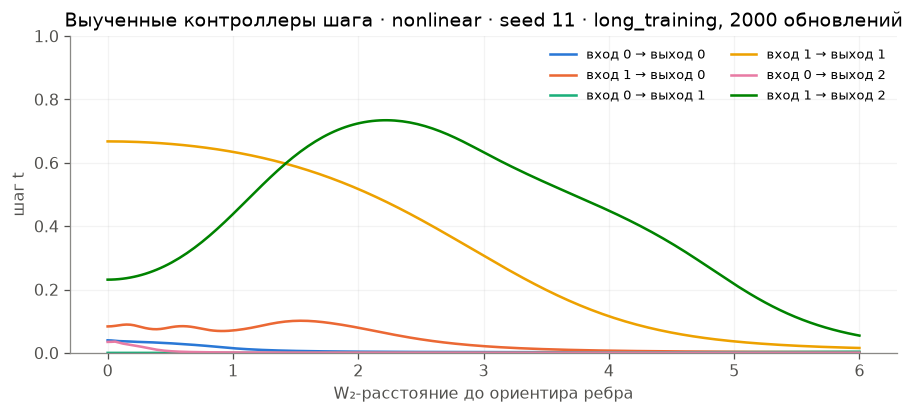

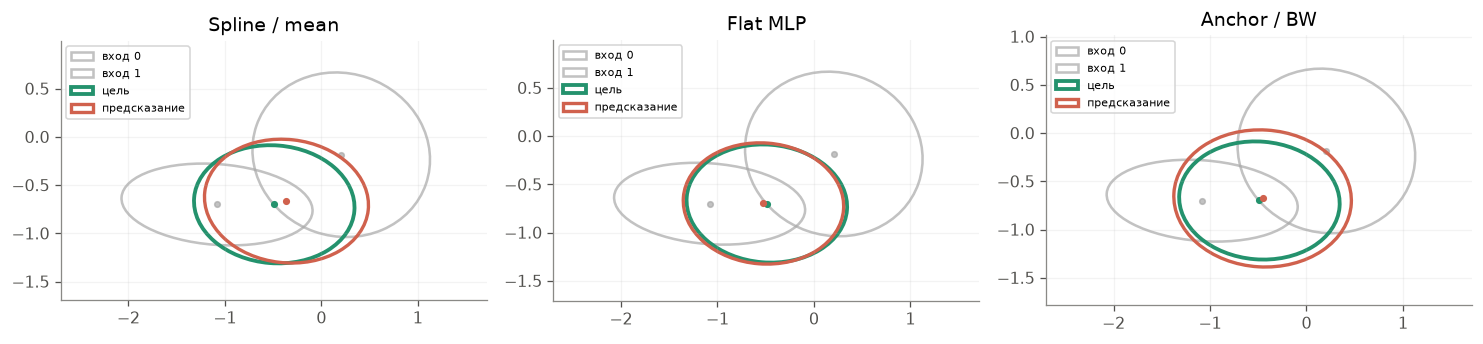

In [30]:
def pick_snapshot(model_name, task='nonlinear'):
    for stage, tag in (('long_training', EXPERIMENT_TAG), ('smoke', 'smoke')):
        cfg = cfg_like(stage, model=model_name, task=task, train_seed=11)
        model = load_best_model(tag, cfg)
        if model is not None:
            return model, f'{stage}, {cfg.steps} обновлений'
    return None, None

trained_anchor, source = pick_snapshot('Anchor / BW')
if trained_anchor is None:
    print('Нет обученных моделей: запустите smoke или этап A.')
else:
    layer = trained_anchor.layers[0]
    with torch.no_grad():
        distances = torch.linspace(0, 6, 200, device=DEVICE)
        rr = distances[:, None, None].square() / layer.log_tau.exp().square()
        uu = rr / (1 + rr)
        tt = torch.sigmoid((layer.basis(uu) * layer.coeff).sum(-1) + layer.bias)
    fig, ax = plt.subplots(figsize=(8, 3.7))
    edge_colors = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
    for o in range(3):
        for i in range(2):
            ax.plot(distances.cpu(), tt[:, o, i].cpu(), color=edge_colors[2*o + i], label=f'вход {i} → выход {o}')
    ax.set(xlabel='W₂-расстояние до ориентира ребра', ylabel='шаг t', ylim=(0, 1),
           title=f'Выученные контроллеры шага · nonlinear · seed 11 · {source}')
    ax.legend(ncol=2, fontsize=8, frameon=False); ax.grid(alpha=.15)
    plt.tight_layout(); plt.show()

    # Один фиксированный test-пример, без отбора самого красивого результата.
    example = 0; G, Y = make_dataset('nonlinear', DATA_SEED_ORIGINAL, *SIZES0)['test']
    fig, axs = plt.subplots(1, 3, figsize=(13, 4))
    for ax, name in zip(axs, ['Spline / mean', 'Flat MLP', 'Anchor / BW']):
        model, _ = pick_snapshot(name)
        with torch.no_grad():
            pred = model(G[0][example:example+1].to(DEVICE), G[1][example:example+1].to(DEVICE))
        for i in range(2):
            draw_gaussian(ax, (G[0][example, i], G[1][example, i]), '#A8A8A8', f'вход {i}', .7)
        draw_gaussian(ax, (Y[0][example, 0], Y[1][example, 0]), '#24926D', 'цель', linewidth=2.4)
        draw_gaussian(ax, (pred[0][0, 0], pred[1][0, 0]), '#D0614D', 'предсказание', linewidth=2.1)
        ax.set_title(name); ax.set_aspect('equal'); ax.autoscale_view(); ax.margins(.2)
        ax.grid(alpha=.15); ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()

## 21. Как читать результаты и что дальше

1. **Spline/mean vs MLP edges/mean** — сплайны против MLP при одинаковых 2520 параметрах,
   одинаковых состоянияx и агрегации. Здесь важны не только ошибка, но и время.
2. **Spline/mean vs Spline/BW**, затем та же пара для MLP — эффект агрегации.
   В каждой паре seed задаёт одинаковые начальные параметры.
3. **Flat MLP** — проверка, нужны ли Gaussian states между слоями для этой задачи.
4. **Anchor/BW** — отдельная гипотеза, очень маленькая модель с ограниченной выразительностью.
   Её проигрыш может быть следствием одного ориентира, а не недостатком BW-геометрии вообще.
5. Если все модели уступают простому baseline, сначала исследовать оптимизацию/постановку;
   не объявлять новую архитектуру успешной из-за одного убывающего loss.

### Математические вопросы для следующего обсуждения

- Точная роль гауссианы в CAD: состояние объекта, локальный эллипсоид формы,
  неопределённость или значение поля? От этого зависит задача: $(G_1,G_2)\mapsto G$ или $(u,v)\mapsto G$.
- Для геометрического ребра: непрерывность, локальные производные и ограничение выразительности.
  Для $0\le t\le1$ SPD сохраняется, поскольку $(1-t)I+tT$ положительно определена.
  При точной геодезической $W_2(G,F(G))=t(G)W_2(G,H)$.
- $t(G)$, зависящий только от расстояния, одинаков на метрической сфере вокруг $H$.
  Следующий вариант — несколько ориентиров/направлений, но сначала измерить недостаток одного.
- При совместном евклидовом повороте/сдвиге входа и всех ориентиров расстояния сохраняются;
  это не означает инвариантность фиксированной обученной сети к произвольному повороту только входа.
- BW-барицентр заменяет усреднение, но не является линейной суммой из теоремы
  Колмогорова–Арнольда. Нельзя объявлять универсальность без отдельного доказательства.
- Геодезический Безье и минимизатор взвешенных квадратов расстояний с весами Бернштейна
  в общем случае дают разные кривые. В этой тетрадке реализован именно де Кастельжо.

### Последовательные следующие изменения

**Шаг A:** длительность и lr реализованы в этапах A–B этой версии; подбор ширины — следующий шаг.
Не выбирать настройки по test или OOD. Отдельно варьировать размеры train и seed датасета.

**Шаг B:** проверить условность матриц, точность барицентра и устойчивость градиента на более
широком диапазоне спектров. Для 3D заменить аналитический 2×2 корень и заново проверить backward.

**Шаг C:** добавить несколько ориентиров на ребре; сравнить с одним при одинаковом числе параметров.
Отдельно проверить тождественное отображение и преобразования, которые требуют удаления от ориентиров.

**Шаг D:** выбрать реальную CAD-задачу с научным руководителем; строить кривую/поверхность,
если на входе пространственные параметры, либо сеть преобразований, если на входе действительно гауссианы.

### Источники

- Liu et al., *KAN: Kolmogorov–Arnold Networks*: https://arxiv.org/abs/2404.19756
- Bhatia, Jain, Lim, *On the Bures–Wasserstein distance between positive definite matrices*:
  https://arxiv.org/abs/1712.01504 — расстояние, транспорт, геодезические и барицентры.
- Bergmann & Gousenbourger, *A Variational Model for Data Fitting on Manifolds by Minimizing
  the Acceleration of a Bézier Curve*: https://doi.org/10.3389/fams.2018.00059
- PyTorch: https://docs.pytorch.org/docs/stable/generated/torch.autograd.gradcheck.html

Определение радиального контроллера, набор моделей и синтетические цели здесь — наша
экспериментальная постановка. Ссылки подтверждают базовые конструкции, не превосходство этой модели.